# Startup Outcome Analysis & Prediction

## Project scope

This notebook is an exploratory classification study of recorded startup outcomes: `Failure`, `Acquisition`, and `IPO`. It is not a validated real-world startup success prediction system. The dataset source, collection methodology, licensing, and timing of measurements were not independently verified. In particular, the data does not establish whether predictors such as revenue or product traction were recorded before the outcome, so temporal leakage cannot be ruled out.

The nine stages below preserve the original analytical work while separating data quality, exploration, statistical association, feature engineering, preprocessing, modeling, evaluation, interpretation, and final documentation.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Load the data

Change `DATA_PATH` if your CSV is in a different place.

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "startup_success_dataset.csv"
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")

Rows: 100,000, Columns: 11


## Quick look

In [3]:
df.head()

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
0,4,13,58,48.225483,594843,18.519211,1.483962e+06,tier2_vc,Health,academic,IPO
1,1,6,221,31.532647,393020,14.298149,8.620568e+05,tier2_vc,Fintech,first_time,Failure
2,3,5,247,4.969722,27636,20.447567,9.726169e+04,none,SaaS,first_time,Failure
3,3,14,229,3.084209,235376,8.177417,1.145785e+06,none,Ecommerce,ex_bigtech,Acquisition
4,1,17,235,13.818188,391765,4.879792,8.608949e+05,none,Health,first_time,Acquisition


In [4]:
df.tail()

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
99995,1,10,189,38.766348,261932,7.945616,1.005687e+06,tier1_vc,Ecommerce,serial_founder,Failure
99996,1,15,39,49.983039,355153,93.223490,1.627273e+06,none,AI,first_time,Acquisition
99997,0,22,215,3.086470,606292,12.832589,1.967245e+06,tier1_vc,Health,academic,Failure
99998,4,24,231,10.815435,277717,28.205609,2.757053e+05,angel,Crypto,ex_bigtech,Failure
99999,2,9,286,9.505618,227192,24.351561,1.018080e+06,tier1_vc,AI,first_time,Acquisition


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   funding_rounds            100000 non-null  int64  
 1   founder_experience_years  100000 non-null  int64  
 2   team_size                 100000 non-null  int64  
 3   market_size_billion       100000 non-null  float64
 4   product_traction_users    100000 non-null  int64  
 5   burn_rate_million         100000 non-null  float64
 6   revenue_million           100000 non-null  float64
 7   investor_type             100000 non-null  str    
 8   sector                    100000 non-null  str    
 9   founder_background        100000 non-null  str    
 10  outcome                   100000 non-null  str    
dtypes: float64(3), int64(4), str(4)
memory usage: 8.4 MB


## 1. Missing values

We count the empty cells in each column.

In [6]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})
display(missing.sort_values("missing_count", ascending=False))

print("Total missing cells:", missing["missing_count"].sum())

,missing_count,missing_percent
funding_rounds,0,0.0
founder_experience_years,0,0.0
team_size,0,0.0
market_size_billion,0,0.0
product_traction_users,0,0.0
burn_rate_million,0,0.0
revenue_million,0,0.0
investor_type,0,0.0
sector,0,0.0
founder_background,0,0.0


Total missing cells: 0


## 2. Duplicate rows

A duplicate is a row that matches another row in every column.

In [7]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count:,} ({duplicate_count / len(df) * 100:.2f}%)")

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))

Duplicate rows: 0 (0.00%)


## 3. Data types

We split the columns into numbers and categories. Each type needs different checks.

In [8]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

dtype_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
})
display(dtype_summary)

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

,dtype,unique_values
funding_rounds,int64,9
founder_experience_years,int64,25
team_size,int64,298
market_size_billion,float64,100000
product_traction_users,int64,91579
burn_rate_million,float64,100000
revenue_million,float64,100000
investor_type,str,4
sector,str,7
founder_background,str,4


Numeric columns: ['funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million']
Categorical columns: ['investor_type', 'sector', 'founder_background', 'outcome']


## 4. Outliers

We use the IQR rule. A value is flagged if it is below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR`.

A flag does not mean the value is wrong. Real startups can have extreme values too, so we only flag them and keep every row.

In [9]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
funding_rounds,100000.0,2.002300,1.414671,0.000000,1.000000,2.000000,3.000000e+00,8.000000e+00
founder_experience_years,100000.0,12.024300,7.208089,0.000000,6.000000,12.000000,1.800000e+01,2.400000e+01
team_size,100000.0,150.732000,86.272631,2.000000,76.000000,151.000000,2.260000e+02,2.990000e+02
market_size_billion,100000.0,33.203875,43.034753,0.288738,10.196778,20.158063,3.953197e+01,1.072434e+03
product_traction_users,100000.0,285422.832730,159323.885405,668.000000,161194.750000,264989.500000,3.892140e+05,9.152030e+05
burn_rate_million,100000.0,16.776213,15.711368,0.279763,7.087591,12.169059,2.095356e+01,3.574915e+02
revenue_million,100000.0,782819.143683,608506.910922,1344.810178,315486.092584,621362.389435,1.098921e+06,4.168443e+06


In [10]:
q1 = df[numeric_columns].quantile(0.25)
q3 = df[numeric_columns].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

is_outlier = (df[numeric_columns] < lower) | (df[numeric_columns] > upper)

outlier_summary = pd.DataFrame({
    "lower_fence": lower,
    "upper_fence": upper,
    "outlier_count": is_outlier.sum(),
    "outlier_percent": is_outlier.mean() * 100,
}).sort_values("outlier_count", ascending=False)

outlier_summary

,lower_fence,upper_fence,outlier_count,outlier_percent
market_size_billion,-33.806006,8.353475e+01,7811,7.811
burn_rate_million,-13.711365,4.175252e+01,6186,6.186
revenue_million,-859665.724750,2.274072e+06,2888,2.888
product_traction_users,-180834.125000,7.312429e+05,624,0.624
funding_rounds,-2.000000,6.000000e+00,470,0.470
team_size,-149.000000,4.510000e+02,0,0.000
founder_experience_years,-12.000000,3.600000e+01,0,0.000


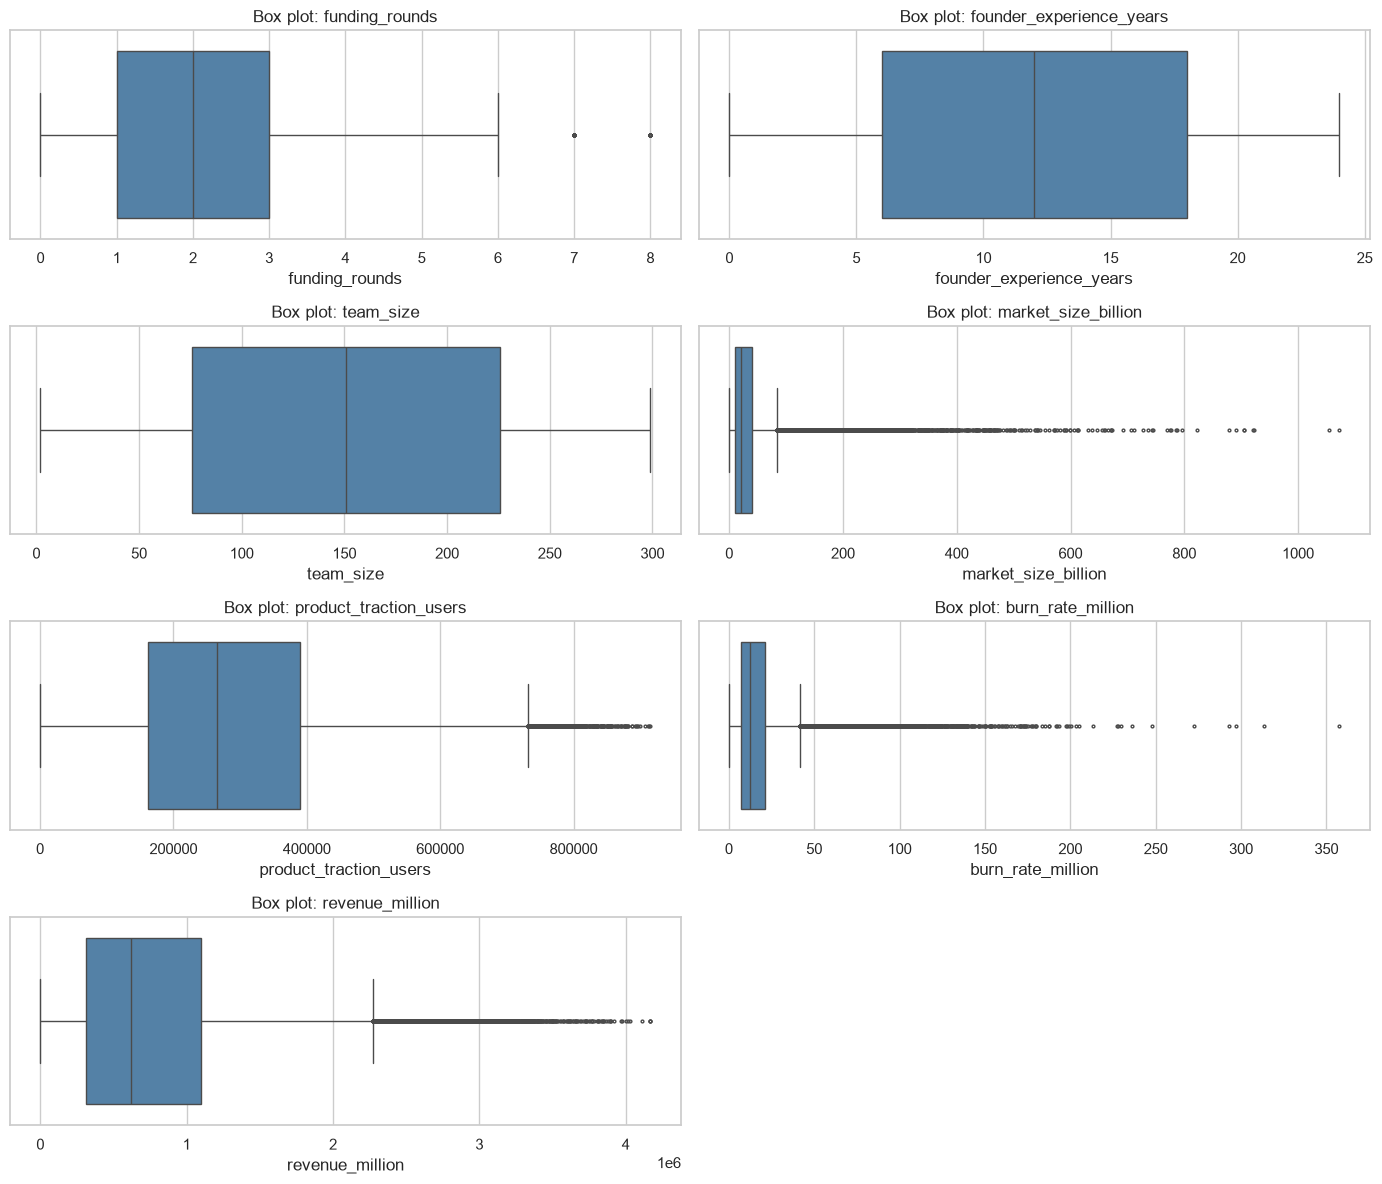

In [11]:
n_cols = 2
n_rows = int(np.ceil(len(numeric_columns) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3 * n_rows))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(x=df[column], ax=ax, color="steelblue", fliersize=2)
    ax.set_title(f"Box plot: {column}")

# hide any empty plot at the end
for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 5. Data validity

Here we check that the values make sense. For example, team size cannot be zero or negative.

In [12]:
# column: a check that is True when the value is valid
rules = {
    "funding_rounds": df["funding_rounds"] >= 0,
    "founder_experience_years": df["founder_experience_years"] >= 0,
    "team_size": df["team_size"] > 0,
    "market_size_billion": df["market_size_billion"] > 0,
    "product_traction_users": df["product_traction_users"] >= 0,
    "burn_rate_million": df["burn_rate_million"] >= 0,
    "revenue_million": df["revenue_million"] >= 0,
}

validity_summary = pd.DataFrame({
    "invalid_count": {column: (~valid).sum() for column, valid in rules.items()}
})
validity_summary["min"] = df[list(rules)].min()
validity_summary["max"] = df[list(rules)].max()
validity_summary

,invalid_count,min,max
funding_rounds,0,0.000000,8.000000e+00
founder_experience_years,0,0.000000,2.400000e+01
team_size,0,2.000000,2.990000e+02
market_size_billion,0,0.288738,1.072434e+03
product_traction_users,0,668.000000,9.152030e+05
burn_rate_million,0,0.279763,3.574915e+02
revenue_million,0,1344.810178,4.168443e+06


We also check the category columns. We look at the labels and see if the same label is written in different ways, like `AI` and `ai `.

In [13]:
for column in categorical_columns:
    print(f"{column}: {sorted(df[column].unique())}")

investor_type: ['angel', 'none', 'tier1_vc', 'tier2_vc']
sector: ['AI', 'Climate', 'Crypto', 'Ecommerce', 'Fintech', 'Health', 'SaaS']
founder_background: ['academic', 'ex_bigtech', 'first_time', 'serial_founder']
outcome: ['Acquisition', 'Failure', 'IPO']


In [14]:
variant_found = False

for column in categorical_columns:
    cleaned = df[column].str.strip().str.lower()
    if cleaned.nunique() < df[column].nunique():
        variant_found = True
        print(f"{column}: same label written in different ways")

if not variant_found:
    print("No spelling or case problems found.")

No spelling or case problems found.


## 6. Target and features

`outcome` is what we want to predict. It must never be used as an input feature, or the model would be cheating.

In [15]:
target_column = "outcome"
feature_columns = [column for column in df.columns if column != target_column]

print("Target:", target_column)
print("Features:", feature_columns)
print()
print(df[target_column].value_counts())

Target: outcome
Features: ['funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million', 'investor_type', 'sector', 'founder_background']

outcome
Failure        55610
Acquisition    42335
IPO             2055
Name: count, dtype: int64


## Summary

In [16]:
quality_summary = pd.DataFrame({
    "check": [
        "Missing cells",
        "Duplicate rows",
        "Numeric / categorical columns",
        "IQR outlier flags",
        "Invalid values",
    ],
    "result": [
        int(missing["missing_count"].sum()),
        int(duplicate_count),
        f"{len(numeric_columns)} / {len(categorical_columns)}",
        int(outlier_summary["outlier_count"].sum()),
        int(validity_summary["invalid_count"].sum()),
    ],
})
quality_summary

,check,result
0,Missing cells,0
1,Duplicate rows,0
2,Numeric / categorical columns,7 / 4
3,IQR outlier flags,17979
4,Invalid values,0


What we found on the full dataset (100,000 rows, 11 columns):

- No missing values and no duplicate rows.
- 7 numeric columns and 4 category columns. The types look right.
- The IQR rule flagged a lot of values, mostly in market size, burn rate, revenue and user traction. These need a closer look before we decide anything.
- No invalid values and no label spelling problems.
- `outcome` is the target and stays out of the features.

Next steps:

1. Keep the raw file as it is.
2. Look at the flagged outliers before deciding to keep, cap or transform them.
3. Re-run these checks after any cleaning.

## Step 2 ? Exploratory Data Analysis (EDA)

### 2.1 Target Variable Analysis

The objective of this area is to understand the distribution of the classification target, `outcome`, before examining predictor variables. We calculate class counts and percentages and visualise the distribution. This establishes whether the classes are balanced and informs later choices about evaluation metrics, stratified splitting, and?if needed?class-weighting or resampling. No hypothesis testing or model training is performed here.

,class_count,percentage
outcome,,
Acquisition,42335,42.34
Failure,55610,55.61
IPO,2055,2.05


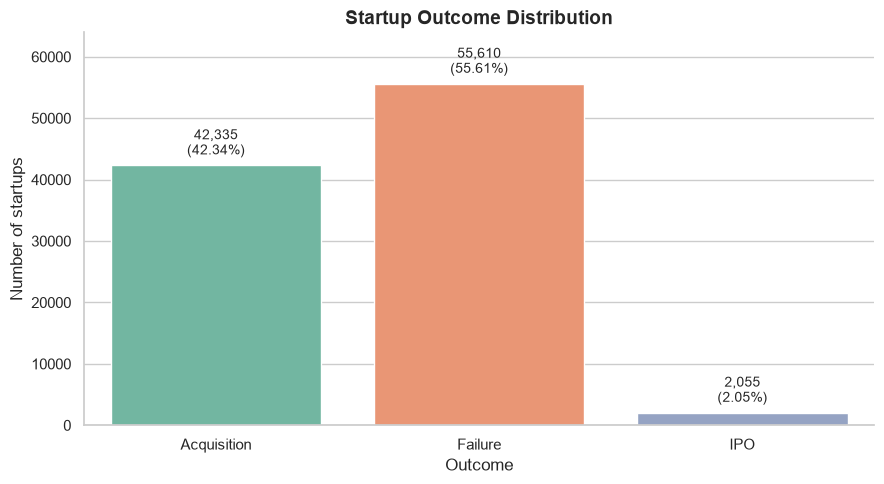

The target is strongly imbalanced: the minority class is below 10% of observations and the largest-to-smallest class ratio is at least 3.
Largest-to-smallest class percentage ratio: 27.13
Implications for classification: report per-class precision, recall, and F1-score in addition to accuracy; use stratified train/test splits; and consider class weights or resampling only if later model evaluation shows minority-class performance is inadequate.


In [17]:
target_counts = df["outcome"].value_counts().sort_index()
target_percentages = df["outcome"].value_counts(normalize=True).sort_index().mul(100)

target_distribution = pd.DataFrame({
    "class_count": target_counts,
    "percentage": target_percentages.round(2)
})

display(target_distribution)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    x=target_distribution.index,
    y=target_distribution["class_count"],
    hue=target_distribution.index,
    palette="Set2",
    legend=False,
    ax=ax
)
ax.set_title("Startup Outcome Distribution", fontsize=14, fontweight="bold")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of startups")
ax.set_ylim(0, target_distribution["class_count"].max() * 1.15)

for index, (class_name, row) in enumerate(target_distribution.iterrows()):
    ax.text(
        index,
        row["class_count"] + target_distribution["class_count"].max() * 0.02,
        f'{int(row["class_count"]):,}\n({row["percentage"]:.2f}%)',
        ha="center",
        va="bottom",
        fontsize=10
    )

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

largest_class_percentage = target_distribution["percentage"].max()
smallest_class_percentage = target_distribution["percentage"].min()
class_ratio = largest_class_percentage / smallest_class_percentage

if smallest_class_percentage < 10 or class_ratio >= 3:
    balance_interpretation = "The target is strongly imbalanced: the minority class is below 10% of observations and the largest-to-smallest class ratio is at least 3."
else:
    balance_interpretation = "The target does not show strong class imbalance under the screening rules used here."

print(balance_interpretation)
print(f"Largest-to-smallest class percentage ratio: {class_ratio:.2f}")
print("Implications for classification: report per-class precision, recall, and F1-score in addition to accuracy; use stratified train/test splits; and consider class weights or resampling only if later model evaluation shows minority-class performance is inadequate.")

## 2.2 Univariate Analysis: Numerical Features

This area describes each numerical feature using location, spread, quartiles, range, and skewness. Histograms with KDE curves show distribution shape, while boxplots make potential extreme values visible. These are descriptive checks only: no outliers are removed and no transformations are applied.

Descriptive statistics and skewness:


,count,mean,median,std,min,25%,50%,75%,max,skewness
funding_rounds,100000.0,2.002,2.000,1.415,0.000,1.000,2.000,3.000,8.000,0.694
founder_experience_years,100000.0,12.024,12.000,7.208,0.000,6.000,12.000,18.000,24.000,-0.009
team_size,100000.0,150.732,151.000,86.273,2.000,76.000,151.000,226.000,299.000,-0.005
market_size_billion,100000.0,33.204,20.158,43.035,0.289,10.197,20.158,39.532,1072.434,5.262
product_traction_users,100000.0,285422.833,264989.500,159323.885,668.000,161194.750,264989.500,389214.000,915203.000,0.586
burn_rate_million,100000.0,16.776,12.169,15.711,0.280,7.088,12.169,20.954,357.491,3.346
revenue_million,100000.0,782819.144,621362.389,608506.911,1344.810,315486.093,621362.389,1098920.637,4168442.503,1.255


Skewness interpretation (absolute skewness above 1 is treated as strong for screening):


,skewness,shape
funding_rounds,0.693892,approximately symmetric to moderately skewed
founder_experience_years,-0.009426,approximately symmetric to moderately skewed
team_size,-0.004519,approximately symmetric to moderately skewed
market_size_billion,5.262352,strong right skew
product_traction_users,0.585569,approximately symmetric to moderately skewed
burn_rate_million,3.346480,strong right skew
revenue_million,1.254592,strong right skew


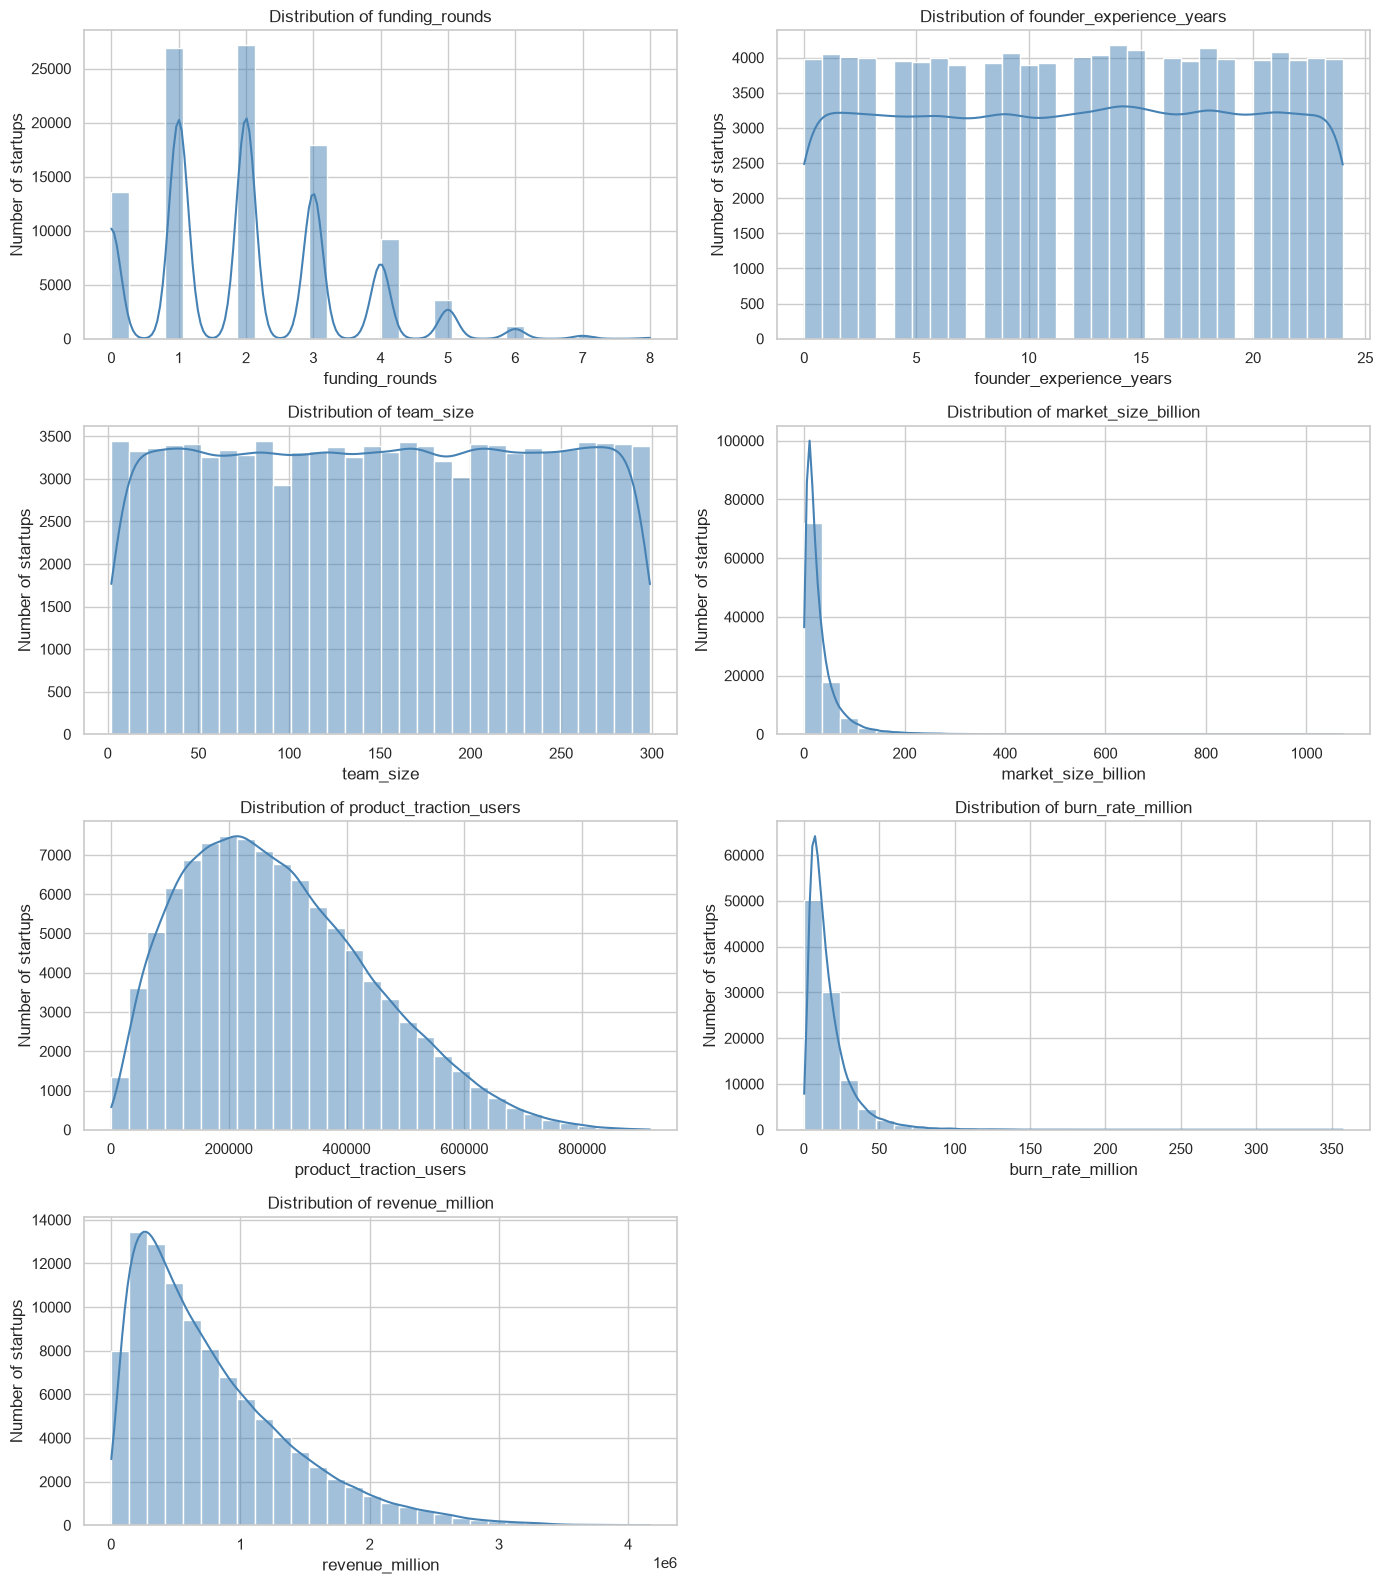

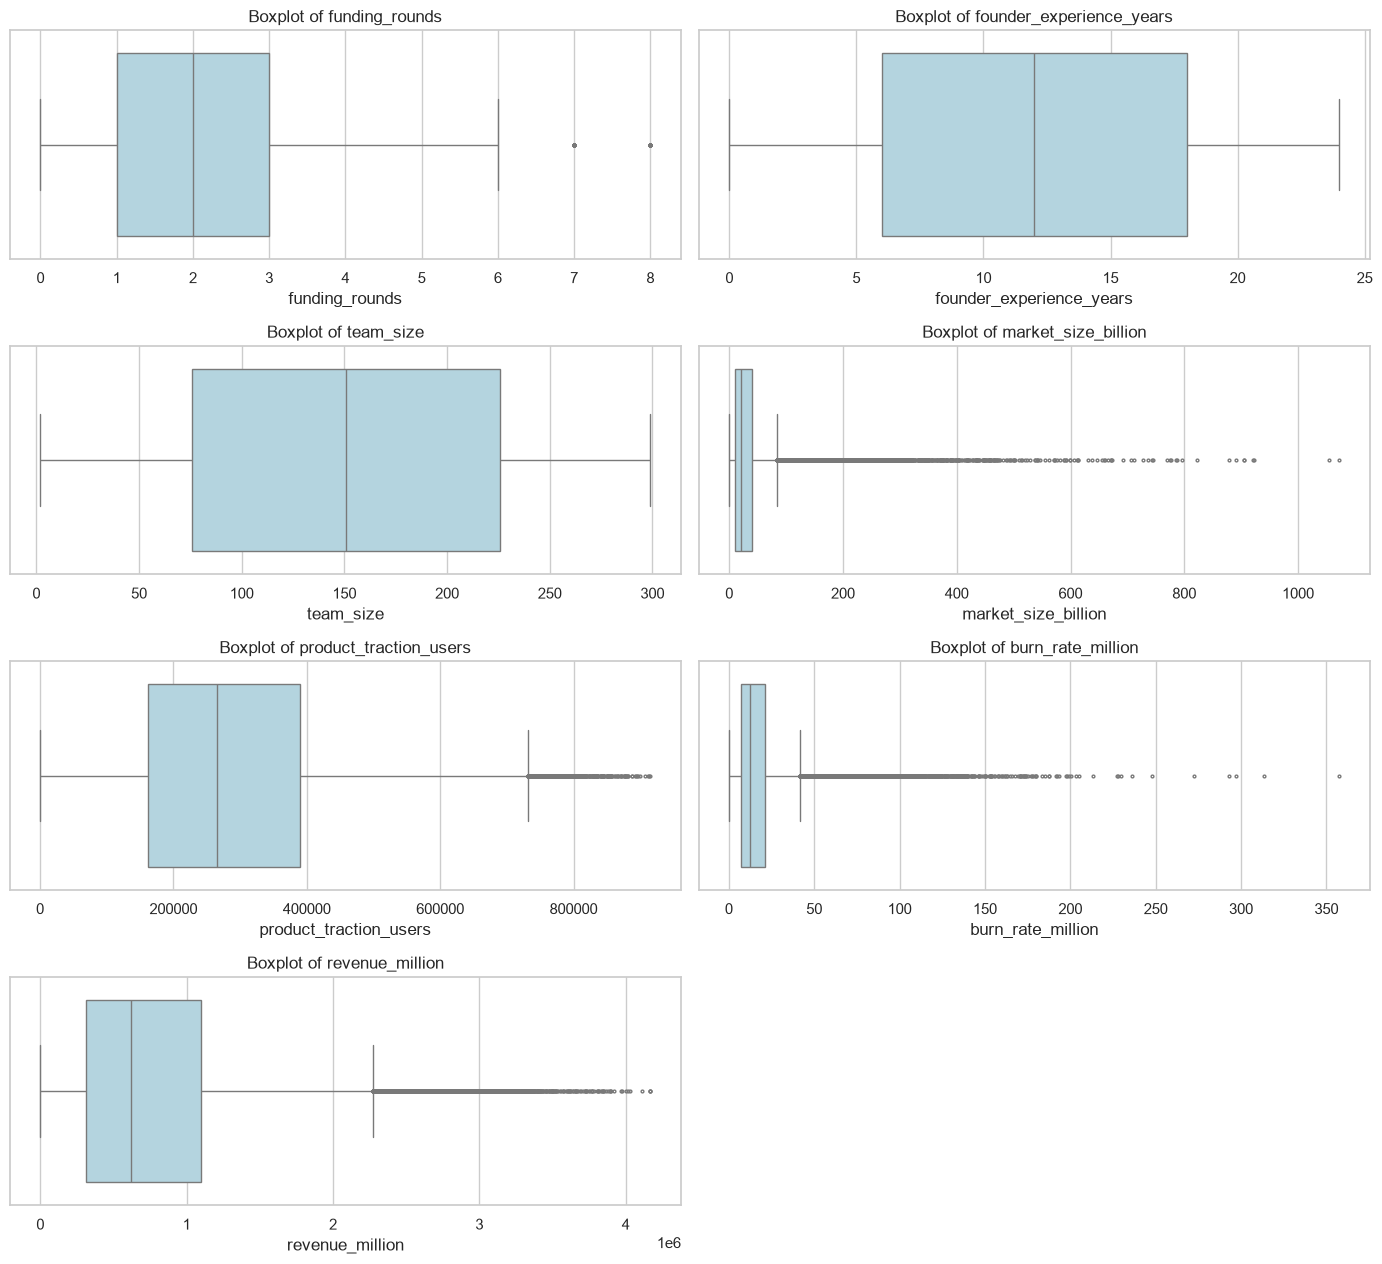

Interpretation: market_size_billion has the highest positive skewness, while founder_experience_years has the lowest skewness.
Relative variation is greatest for market_size_billion based on the standard-deviation-to-mean ratio.
The boxplots and the previously computed IQR screening should be reviewed together; extreme values are documented, not removed.


In [18]:
numerical_features = [
    "funding_rounds", "founder_experience_years", "team_size",
    "market_size_billion", "product_traction_users", "burn_rate_million",
    "revenue_million"
]

numerical_descriptive = df[numerical_features].describe().T
numerical_descriptive["median"] = df[numerical_features].median()
numerical_descriptive["skewness"] = df[numerical_features].skew()
numerical_descriptive = numerical_descriptive[[
    "count", "mean", "median", "std", "min", "25%", "50%", "75%", "max", "skewness"
]]
print("Descriptive statistics and skewness:")
display(numerical_descriptive.round(3))

skew_interpretation = numerical_descriptive[["skewness"]].copy()
skew_interpretation["shape"] = np.select(
    [skew_interpretation["skewness"] < -1, skew_interpretation["skewness"] > 1],
    ["strong left skew", "strong right skew"],
    default="approximately symmetric to moderately skewed"
)
print("Skewness interpretation (absolute skewness above 1 is treated as strong for screening):")
display(skew_interpretation)

n_cols = 2
n_rows = int(np.ceil(len(numerical_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
for axis, column in zip(np.ravel(axes), numerical_features):
    sns.histplot(df[column], kde=True, bins=30, color="steelblue", ax=axis)
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column)
    axis.set_ylabel("Number of startups")
for axis in np.ravel(axes)[len(numerical_features):]:
    axis.remove()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
for axis, column in zip(np.ravel(axes), numerical_features):
    sns.boxplot(x=df[column], color="lightblue", fliersize=2, ax=axis)
    axis.set_title(f"Boxplot of {column}")
    axis.set_xlabel(column)
for axis in np.ravel(axes)[len(numerical_features):]:
    axis.remove()
plt.tight_layout()
plt.show()

most_right_skewed = numerical_descriptive["skewness"].idxmax()
most_left_skewed = numerical_descriptive["skewness"].idxmin()
most_variable = (numerical_descriptive["std"] / numerical_descriptive["mean"].replace(0, np.nan)).idxmax()
print(f"Interpretation: {most_right_skewed} has the highest positive skewness, while {most_left_skewed} has the lowest skewness.")
print(f"Relative variation is greatest for {most_variable} based on the standard-deviation-to-mean ratio.")
print("The boxplots and the previously computed IQR screening should be reviewed together; extreme values are documented, not removed.")

## 2.3 Univariate Analysis: Categorical Features

This area measures the frequency and percentage of each category for investor type, sector, and founder background. Count plots show the absolute sample sizes, which is important when interpreting rare categories and later comparing outcomes.

investor_type frequency and percentage:


,count,percentage
investor_type,,
tier2_vc,35327,35.33
angel,25137,25.14
none,24866,24.87
tier1_vc,14670,14.67


sector frequency and percentage:


,count,percentage
sector,,
Crypto,14456,14.46
Climate,14412,14.41
Health,14357,14.36
SaaS,14333,14.33
Fintech,14220,14.22
Ecommerce,14148,14.15
AI,14074,14.07


founder_background frequency and percentage:


,count,percentage
founder_background,,
first_time,39980,39.98
ex_bigtech,25009,25.01
academic,20054,20.05
serial_founder,14957,14.96


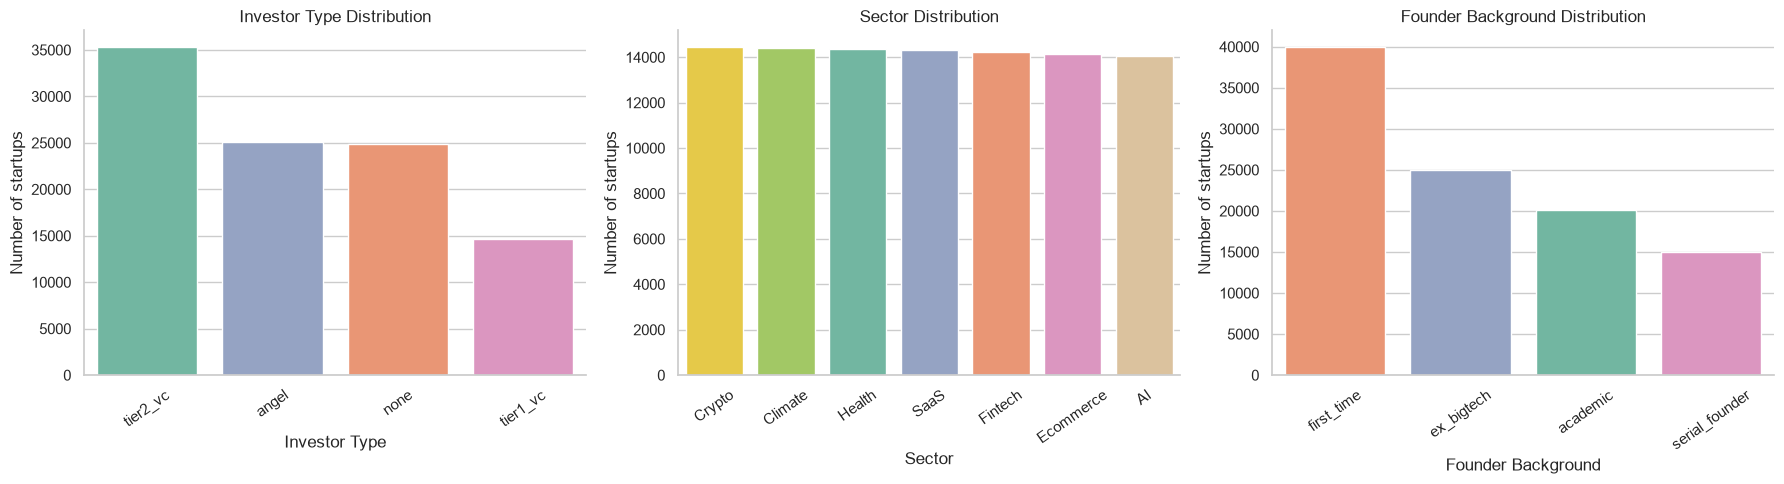

investor_type: dominant category is 'tier2_vc' (35.33%).
investor_type: categories at or below 5% of records: none.
sector: dominant category is 'Crypto' (14.46%).
sector: categories at or below 5% of records: none.
founder_background: dominant category is 'first_time' (39.98%).
founder_background: categories at or below 5% of records: none.
Interpretation: rare categories should be retained for now because their small sample sizes can make outcome percentages unstable; category counts should accompany all comparisons.


In [19]:
categorical_features = ["investor_type", "sector", "founder_background"]
category_summaries = {}
for column in categorical_features:
    summary = df[column].value_counts(dropna=False).rename("count").to_frame()
    summary["percentage"] = summary["count"] / len(df) * 100
    category_summaries[column] = summary
    print(f"{column} frequency and percentage:")
    display(summary.round(2))

fig, axes = plt.subplots(1, len(categorical_features), figsize=(18, 5))
for axis, column in zip(np.ravel(axes), categorical_features):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, hue=column, palette="Set2", legend=False, ax=axis)
    axis.set_title(f"{column.replace('_', ' ').title()} Distribution")
    axis.set_xlabel(column.replace("_", " ").title())
    axis.set_ylabel("Number of startups")
    axis.tick_params(axis="x", rotation=35)
    sns.despine(ax=axis)
plt.tight_layout()
plt.show()

for column, summary in category_summaries.items():
    dominant = summary["percentage"].idxmax()
    rare = summary[summary["percentage"] <= 5].index.tolist()
    print(f"{column}: dominant category is {dominant!r} ({summary.loc[dominant, 'percentage']:.2f}%).")
    print(f"{column}: categories at or below 5% of records: {rare if rare else 'none'}.")
print("Interpretation: rare categories should be retained for now because their small sample sizes can make outcome percentages unstable; category counts should accompany all comparisons.")

## 2.4 Bivariate Analysis: Numerical Features vs Outcome

For each numerical feature, grouped descriptive statistics and outcome-separated plots are used to compare Failure, Acquisition, and IPO. Differences in group centers and spreads are descriptive associations only; overlap and unequal group sizes must be considered, and no causal conclusion is drawn.

Grouped descriptive statistics by outcome:


funding_rounds                      founder_experience_years  \
                     count   mean median    std                    count   
outcome                                                                    
Acquisition          42335  2.347    2.0  1.480                    42335   
Failure              55610  1.703    2.0  1.269                    55610   
IPO                   2055  2.999    3.0  1.682                     2055   

                                  team_size                          \
               mean median    std     count     mean median     std   
outcome                                                               
Acquisition  13.534   14.0  7.054     42335  159.243  164.0  85.678   
Failure      10.745   10.0  7.074     55610  143.464  140.0  86.011   
IPO          15.537   17.0  6.737      2055  172.093  183.0  86.018   

            market_size_billion                          \
                          count    mean  median     std   
outcome                                                   
Acquisition               42335  33.379  20.159  44.019   
Failure                   55610  33.085  20.132  42.380   
IPO                        2055  32.817  20.608  40.024   

            product_traction_users                                    \
                             count        mean    median         std   
outcome                                                                
Acquisition                  42335  350871.972  342404.0  154881.310   
Failure                      55610  225905.483  205908.5  131483.576   
IPO                           2055  547695.586  547752.0  142675.133   

            burn_rate_million                         revenue_million  \
                        count    mean  median     std           count   
outcome                                                                 
Acquisition             42335  16.834  12.149  15.719           42335   
Failure                 55610  16.716  12.175  15.697           55610   
IPO                      2055  17.225  12.476  15.950            2055   

                                                   
                    mean       median         std  
outcome                                            
Acquisition  1041604.001   949165.710  634987.538  
Failure       536378.931   434142.609  400542.893  
IPO          2120475.258  2144511.183  747296.971

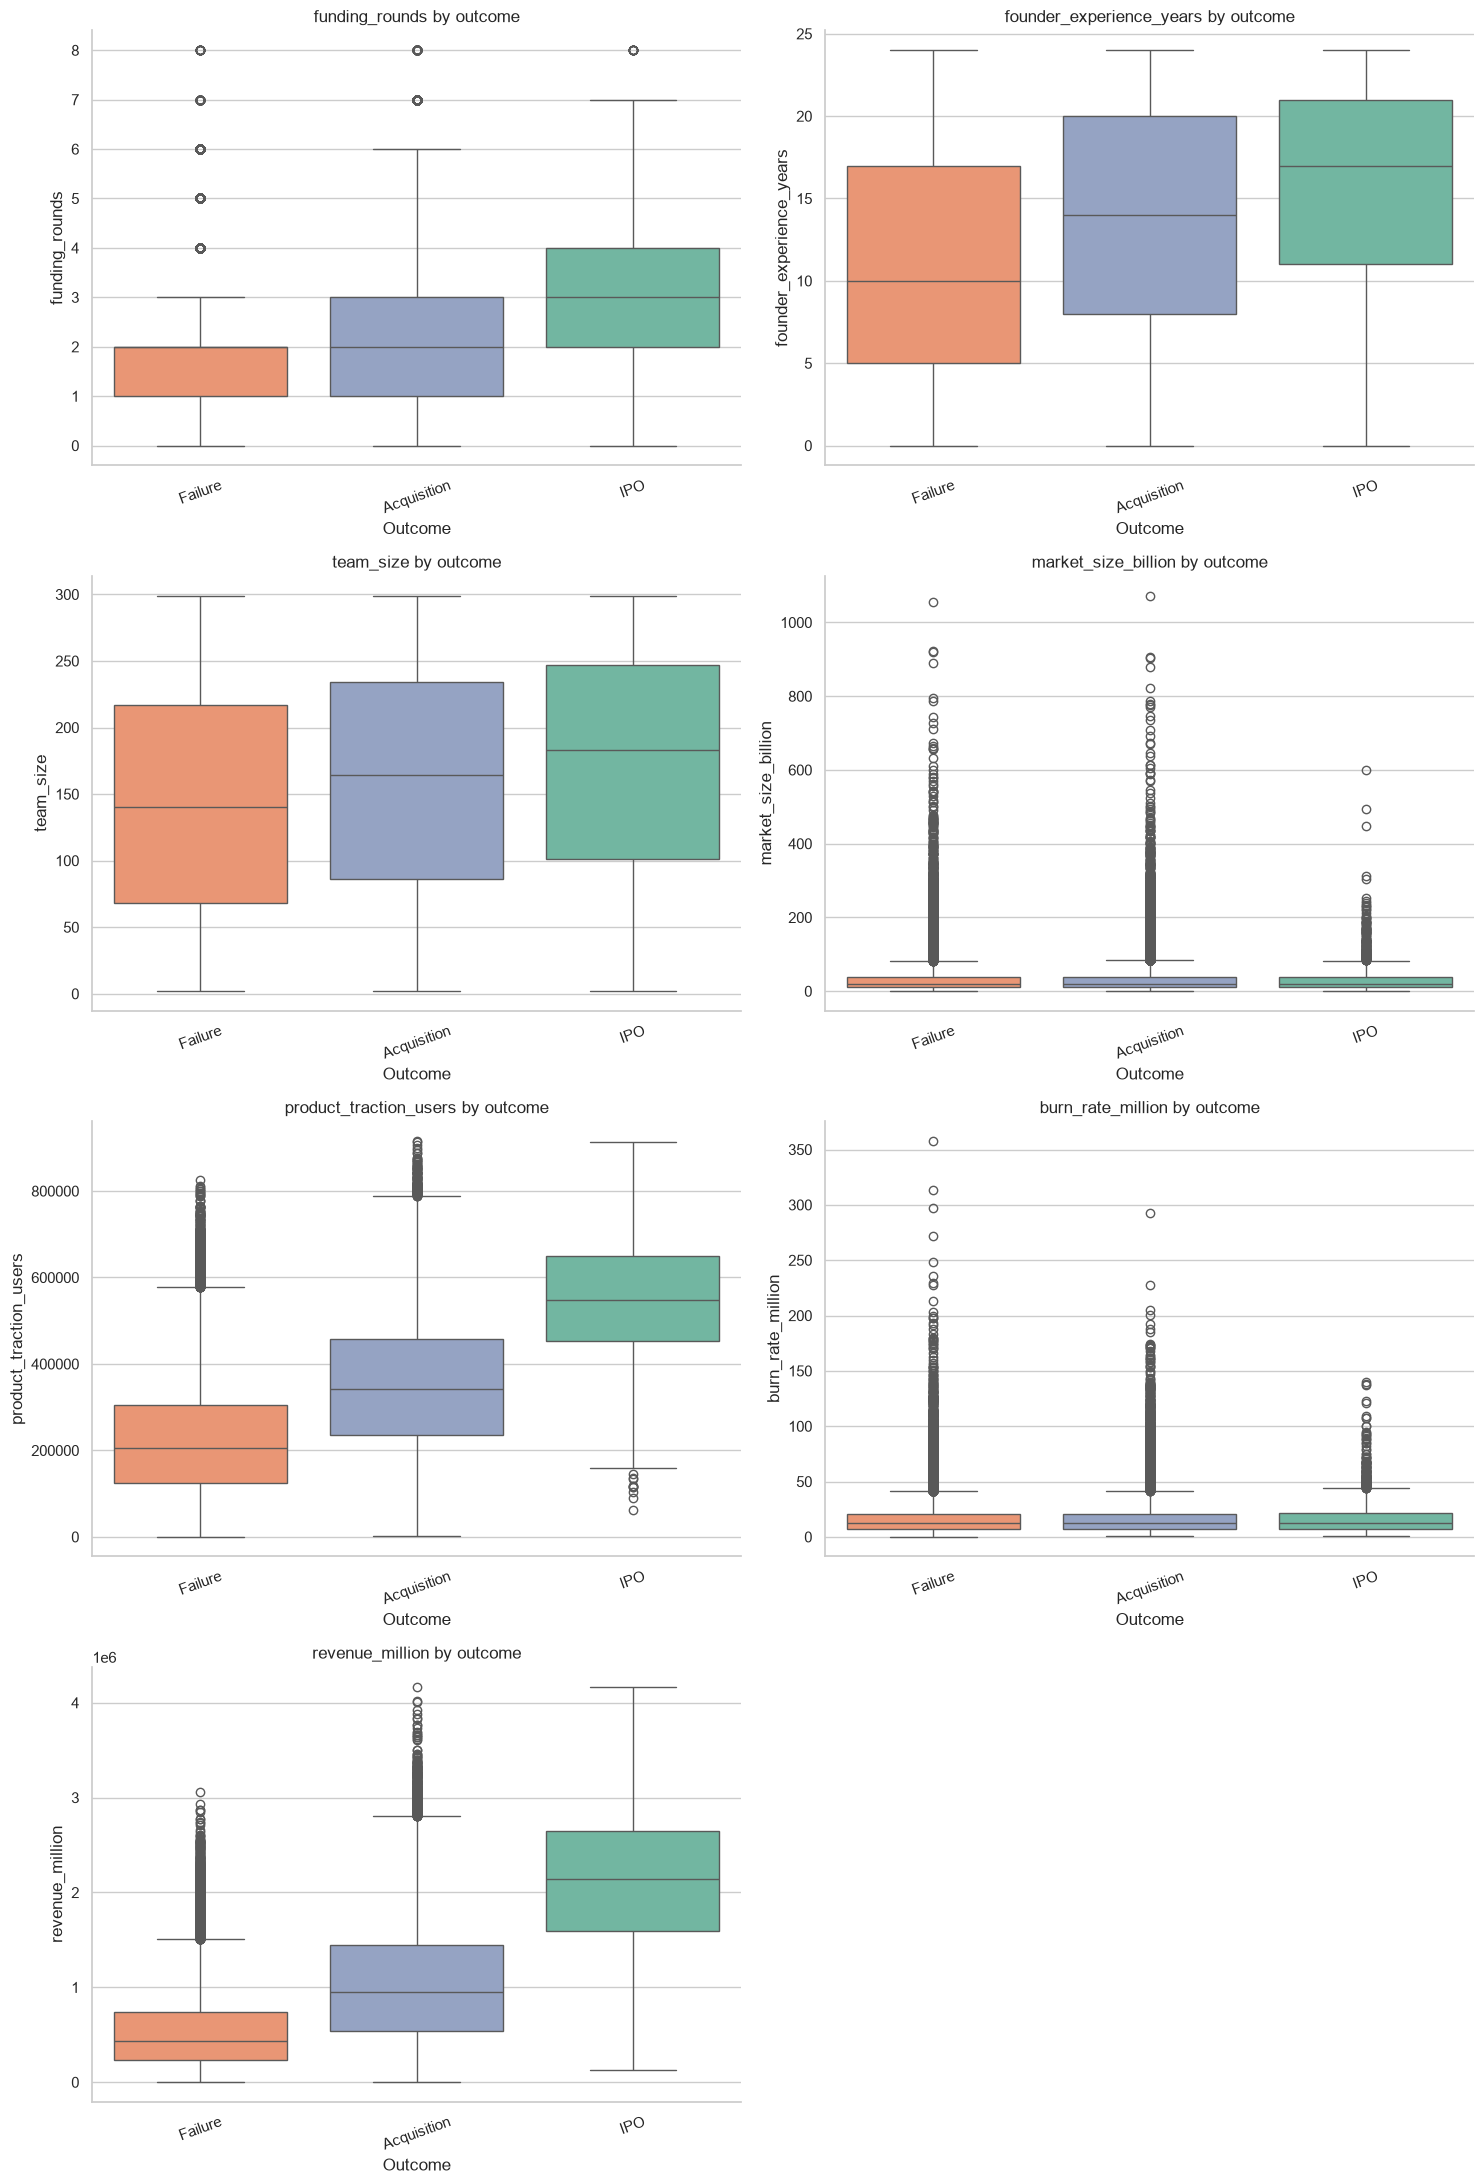

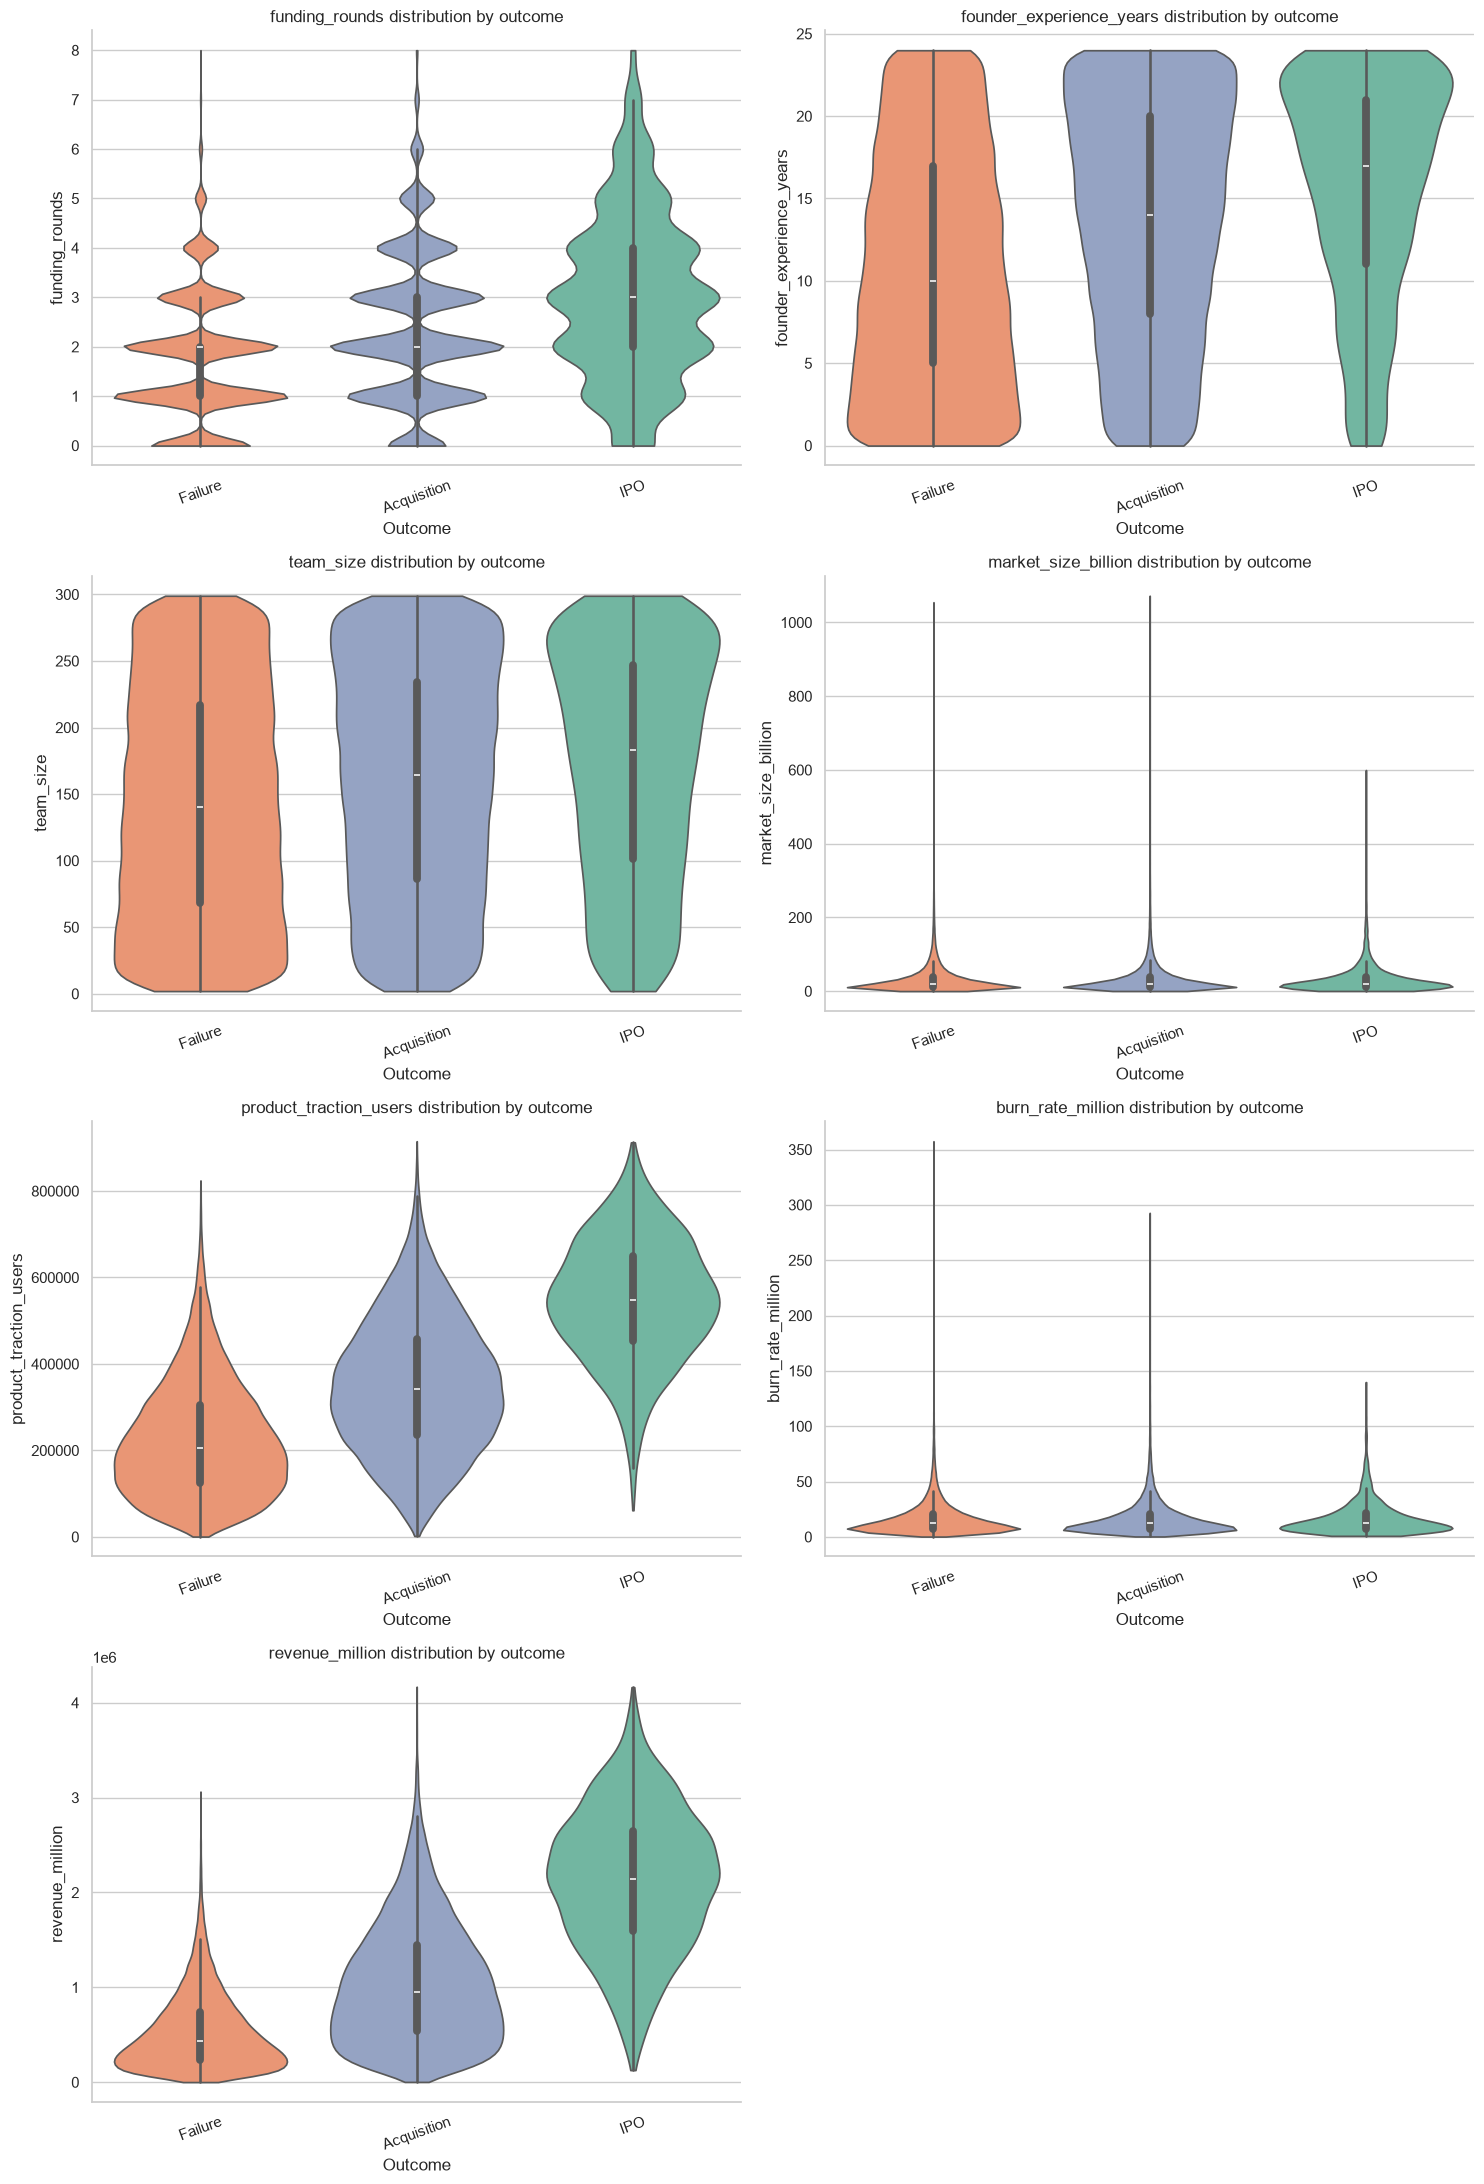

Features ranked by the absolute range of outcome-group medians:


,median_range
revenue_million,1710368.573
product_traction_users,341843.500
team_size,43.000
founder_experience_years,7.000
funding_rounds,1.000
market_size_billion,0.477
burn_rate_million,0.326


Interpretation: larger median ranges indicate stronger descriptive separation between outcome groups, but overlapping boxplots/violins and the small IPO group mean these patterns require statistical investigation later.


In [20]:
grouped_numerical_statistics = df.groupby("outcome", observed=True)[numerical_features].agg(["count", "mean", "median", "std"])
print("Grouped descriptive statistics by outcome:")
display(grouped_numerical_statistics.round(3))

fig, axes = plt.subplots(4, 2, figsize=(15, 22))
for axis, column in zip(np.ravel(axes), numerical_features):
    sns.boxplot(data=df, x="outcome", y=column, order=["Failure", "Acquisition", "IPO"], hue="outcome", palette="Set2", legend=False, ax=axis)
    axis.set_title(f"{column} by outcome")
    axis.set_xlabel("Outcome")
    axis.set_ylabel(column)
    axis.tick_params(axis="x", rotation=20)
    sns.despine(ax=axis)
np.ravel(axes)[-1].remove()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(15, 22))
for axis, column in zip(np.ravel(axes), numerical_features):
    sns.violinplot(data=df, x="outcome", y=column, order=["Failure", "Acquisition", "IPO"], hue="outcome", palette="Set2", legend=False, cut=0, ax=axis)
    axis.set_title(f"{column} distribution by outcome")
    axis.set_xlabel("Outcome")
    axis.set_ylabel(column)
    axis.tick_params(axis="x", rotation=20)
    sns.despine(ax=axis)
np.ravel(axes)[-1].remove()
plt.tight_layout()
plt.show()

outcome_medians = df.groupby("outcome", observed=True)[numerical_features].median()
median_ranges = (outcome_medians.max() - outcome_medians.min()).sort_values(ascending=False)
print("Features ranked by the absolute range of outcome-group medians:")
display(median_ranges.rename("median_range").to_frame().round(3))
print("Interpretation: larger median ranges indicate stronger descriptive separation between outcome groups, but overlapping boxplots/violins and the small IPO group mean these patterns require statistical investigation later.")

## 2.5 Bivariate Analysis: Categorical Features vs Outcome

Cross-tabulations show both counts and within-category outcome percentages. Proportion-based stacked bars make outcome composition comparable across categories, while the count tables provide the sample-size context needed to interpret rare groups.

investor_type ? outcome counts:


outcome,Acquisition,Failure,IPO
investor_type,,,
angel,10535,14049,553
none,10625,13727,514
tier1_vc,6220,8172,278
tier2_vc,14955,19662,710


investor_type ? outcome percentages within category:


outcome,Acquisition,Failure,IPO
investor_type,,,
angel,41.91,55.89,2.20
none,42.73,55.20,2.07
tier1_vc,42.40,55.71,1.90
tier2_vc,42.33,55.66,2.01


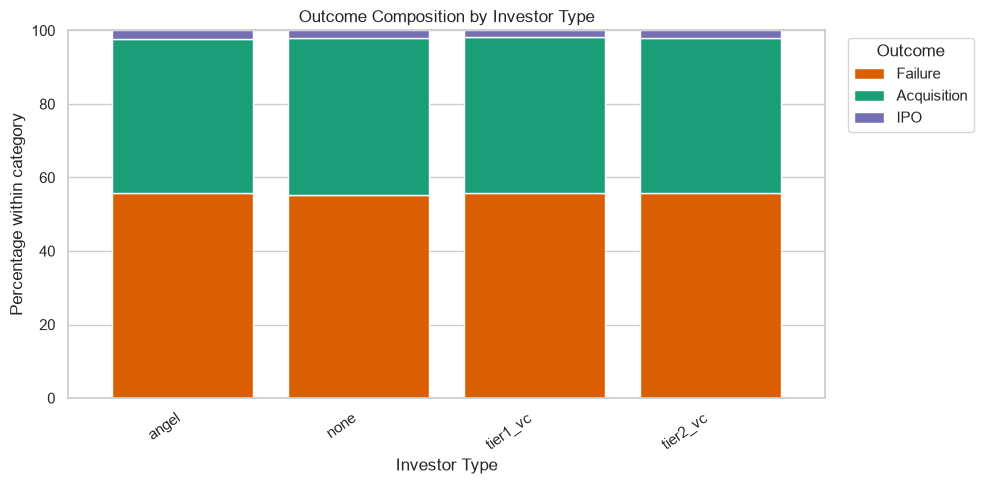

sector ? outcome counts:


outcome,Acquisition,Failure,IPO
sector,,,
AI,5952,7862,260
Climate,6098,8004,310
Crypto,6187,7965,304
Ecommerce,5999,7863,286
Fintech,5910,8009,301
Health,6135,7919,303
SaaS,6054,7988,291


sector ? outcome percentages within category:


outcome,Acquisition,Failure,IPO
sector,,,
AI,42.29,55.86,1.85
Climate,42.31,55.54,2.15
Crypto,42.80,55.10,2.10
Ecommerce,42.40,55.58,2.02
Fintech,41.56,56.32,2.12
Health,42.73,55.16,2.11
SaaS,42.24,55.73,2.03


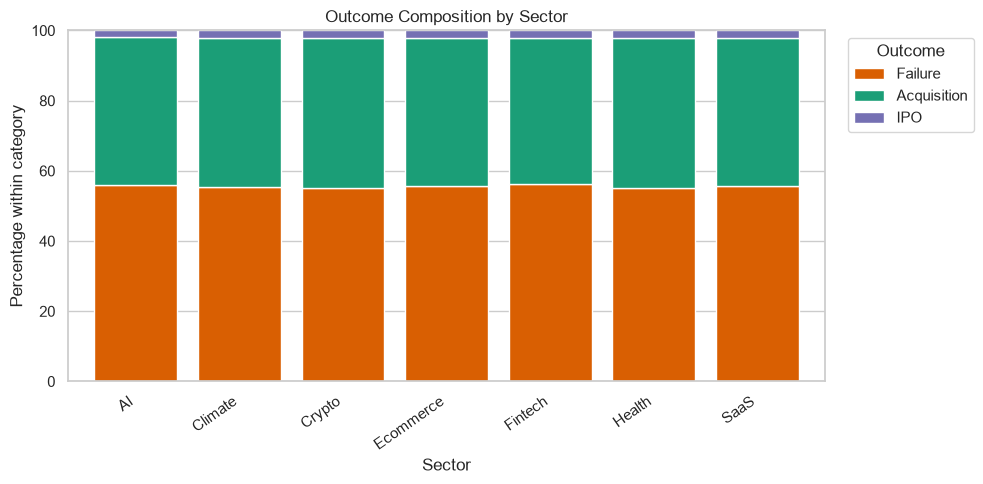

founder_background ? outcome counts:


outcome,Acquisition,Failure,IPO
founder_background,,,
academic,8367,11268,419
ex_bigtech,10549,13943,517
first_time,17021,22145,814
serial_founder,6398,8254,305


founder_background ? outcome percentages within category:


outcome,Acquisition,Failure,IPO
founder_background,,,
academic,41.72,56.19,2.09
ex_bigtech,42.18,55.75,2.07
first_time,42.57,55.39,2.04
serial_founder,42.78,55.18,2.04


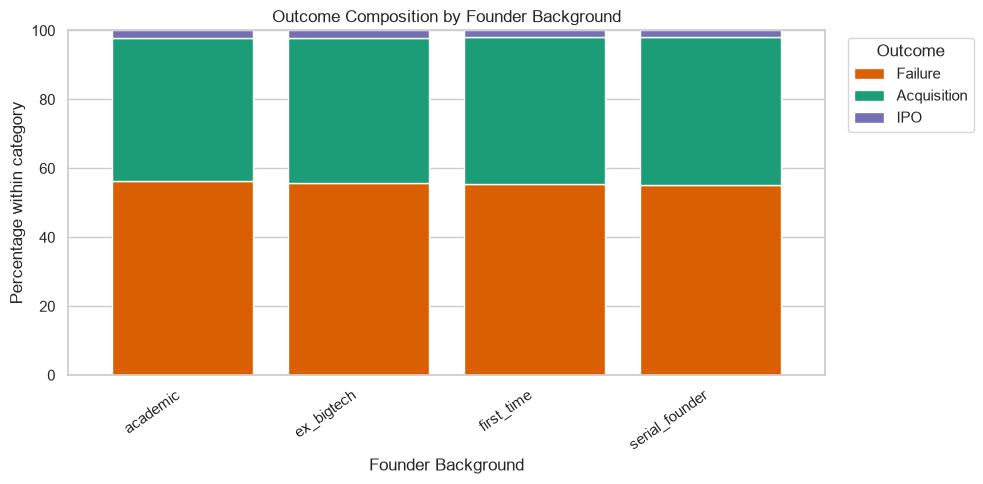

investor_type: highest observed IPO percentage is in 'angel' (2.20%).
investor_type: highest observed Failure percentage is in 'angel' (55.89%).
investor_type: smallest category by sample size is 'tier1_vc'; interpret its percentages cautiously.
sector: highest observed IPO percentage is in 'Climate' (2.15%).
sector: highest observed Failure percentage is in 'Fintech' (56.32%).
sector: smallest category by sample size is 'AI'; interpret its percentages cautiously.
founder_background: highest observed IPO percentage is in 'academic' (2.09%).
founder_background: highest observed Failure percentage is in 'academic' (56.19%).
founder_background: smallest category by sample size is 'serial_founder'; interpret its percentages cautiously.
These are observational group comparisons. Category size and the strong overall class imbalance can materially affect the displayed percentages.


In [21]:
categorical_outcome_tables = {}
for column in categorical_features:
    counts = pd.crosstab(df[column], df["outcome"], dropna=False)
    percentages = pd.crosstab(df[column], df["outcome"], normalize="index", dropna=False).mul(100)
    categorical_outcome_tables[column] = {"counts": counts, "percentages": percentages}
    print(f"{column} ? outcome counts:")
    display(counts)
    print(f"{column} ? outcome percentages within category:")
    display(percentages.round(2))

    percentages.reindex(columns=["Failure", "Acquisition", "IPO"]).plot(
        kind="bar", stacked=True, figsize=(10, 5), color=["#d95f02", "#1b9e77", "#7570b3"], width=0.8
    )
    plt.title(f"Outcome Composition by {column.replace('_', ' ').title()}")
    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel("Percentage within category")
    plt.ylim(0, 100)
    plt.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

for column, tables in categorical_outcome_tables.items():
    percentages = tables["percentages"]
    ipo_category = percentages["IPO"].idxmax()
    failure_category = percentages["Failure"].idxmax()
    smallest_category = tables["counts"].sum(axis=1).idxmin()
    print(f"{column}: highest observed IPO percentage is in {ipo_category!r} ({percentages.loc[ipo_category, 'IPO']:.2f}%).")
    print(f"{column}: highest observed Failure percentage is in {failure_category!r} ({percentages.loc[failure_category, 'Failure']:.2f}%).")
    print(f"{column}: smallest category by sample size is {smallest_category!r}; interpret its percentages cautiously.")
print("These are observational group comparisons. Category size and the strong overall class imbalance can materially affect the displayed percentages.")

## 2.6 Correlation Analysis

Pearson correlations quantify linear association between numerical features. The heatmap provides a visual overview, while the extracted pair list identifies potentially strong relationships for later multicollinearity review. Correlation is not evidence of causation.

Pearson correlation matrix:


,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million
funding_rounds,1.000,0.000,0.004,-0.001,-0.001,-0.003,-0.002
founder_experience_years,0.000,1.000,0.002,0.006,-0.002,0.003,-0.002
team_size,0.004,0.002,1.000,0.005,-0.003,-0.002,0.001
market_size_billion,-0.001,0.006,0.005,1.000,0.001,0.007,0.002
product_traction_users,-0.001,-0.002,-0.003,0.001,1.000,-0.001,0.714
burn_rate_million,-0.003,0.003,-0.002,0.007,-0.001,1.000,-0.001
revenue_million,-0.002,-0.002,0.001,0.002,0.714,-0.001,1.000


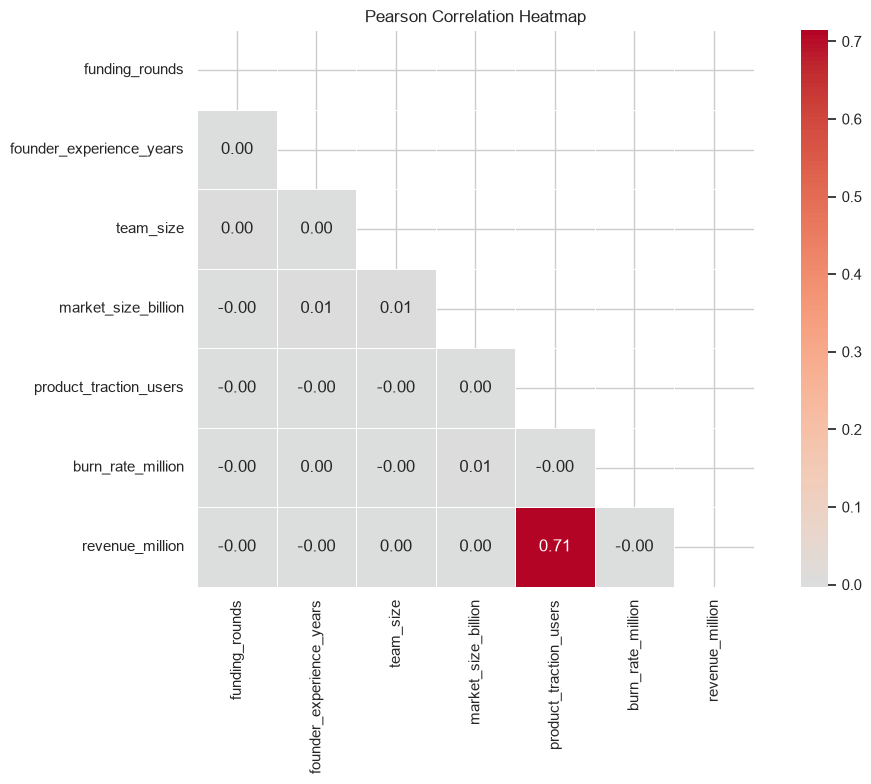

Strong correlation pairs (absolute Pearson r >= 0.70):


,feature_1,feature_2,pearson_r,absolute_r
46,revenue_million,product_traction_users,0.714043,0.714043


The listed pairs may create multicollinearity concerns in later models and should be reviewed alongside model diagnostics.


In [22]:
pearson_correlation = df[numerical_features].corr(method="pearson")
print("Pearson correlation matrix:")
display(pearson_correlation.round(3))

mask = np.triu(np.ones_like(pearson_correlation, dtype=bool))
plt.figure(figsize=(11, 8))
sns.heatmap(pearson_correlation, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

correlation_pairs = pearson_correlation.where(np.tril(np.ones(pearson_correlation.shape), k=-1).astype(bool)).stack().reset_index()
correlation_pairs.columns = ["feature_1", "feature_2", "pearson_r"]
correlation_pairs["absolute_r"] = correlation_pairs["pearson_r"].abs()
correlation_pairs = correlation_pairs.sort_values("absolute_r", ascending=False)
strong_correlation_pairs = correlation_pairs[correlation_pairs["absolute_r"] >= 0.70]
print("Strong correlation pairs (absolute Pearson r >= 0.70):")
display(strong_correlation_pairs if not strong_correlation_pairs.empty else pd.DataFrame(columns=correlation_pairs.columns))
if strong_correlation_pairs.empty:
    print("No numerical pair reached the 0.70 screening threshold; substantial linear multicollinearity is not evident from this matrix alone.")
else:
    print("The listed pairs may create multicollinearity concerns in later models and should be reviewed alongside model diagnostics.")

## 2.7 Multivariate Analysis

This area examines selected numerical relationships while using outcome as a visual grouping variable. A fixed random sample is used for the pairplot to keep rendering manageable and reproducible; the underlying dataframe is not changed. The plots are exploratory and do not perform feature engineering or modelling.

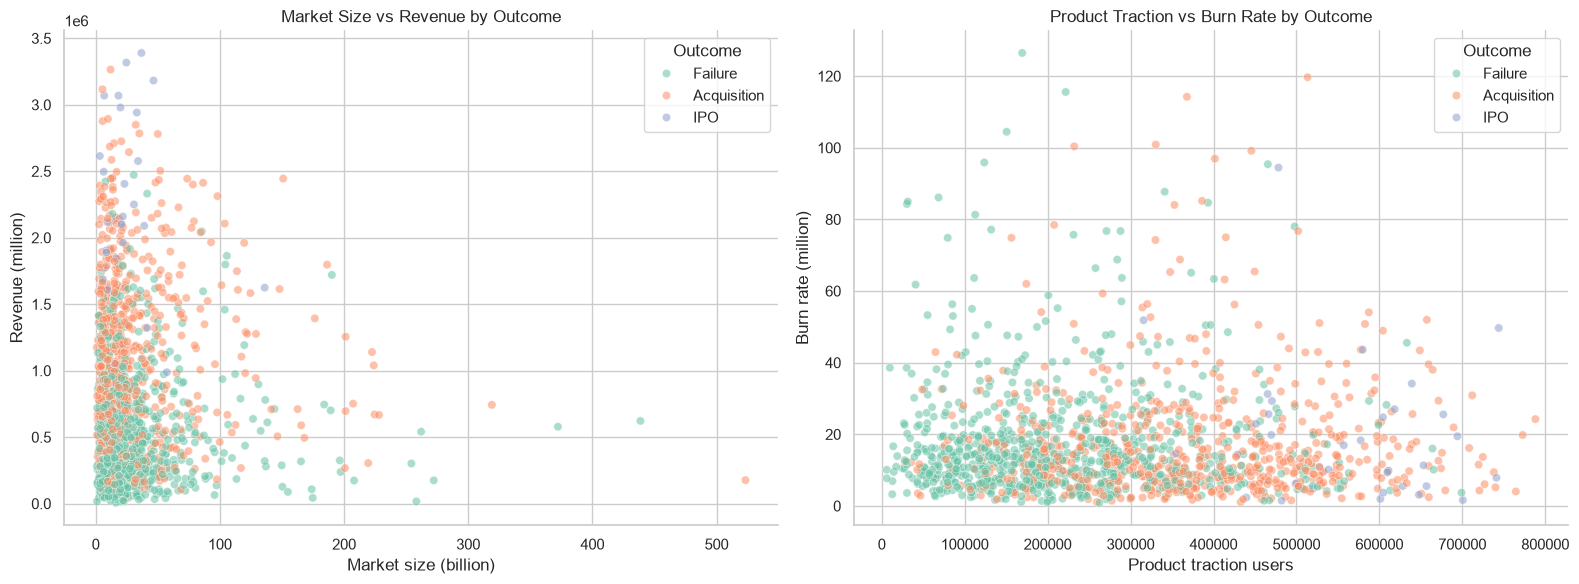

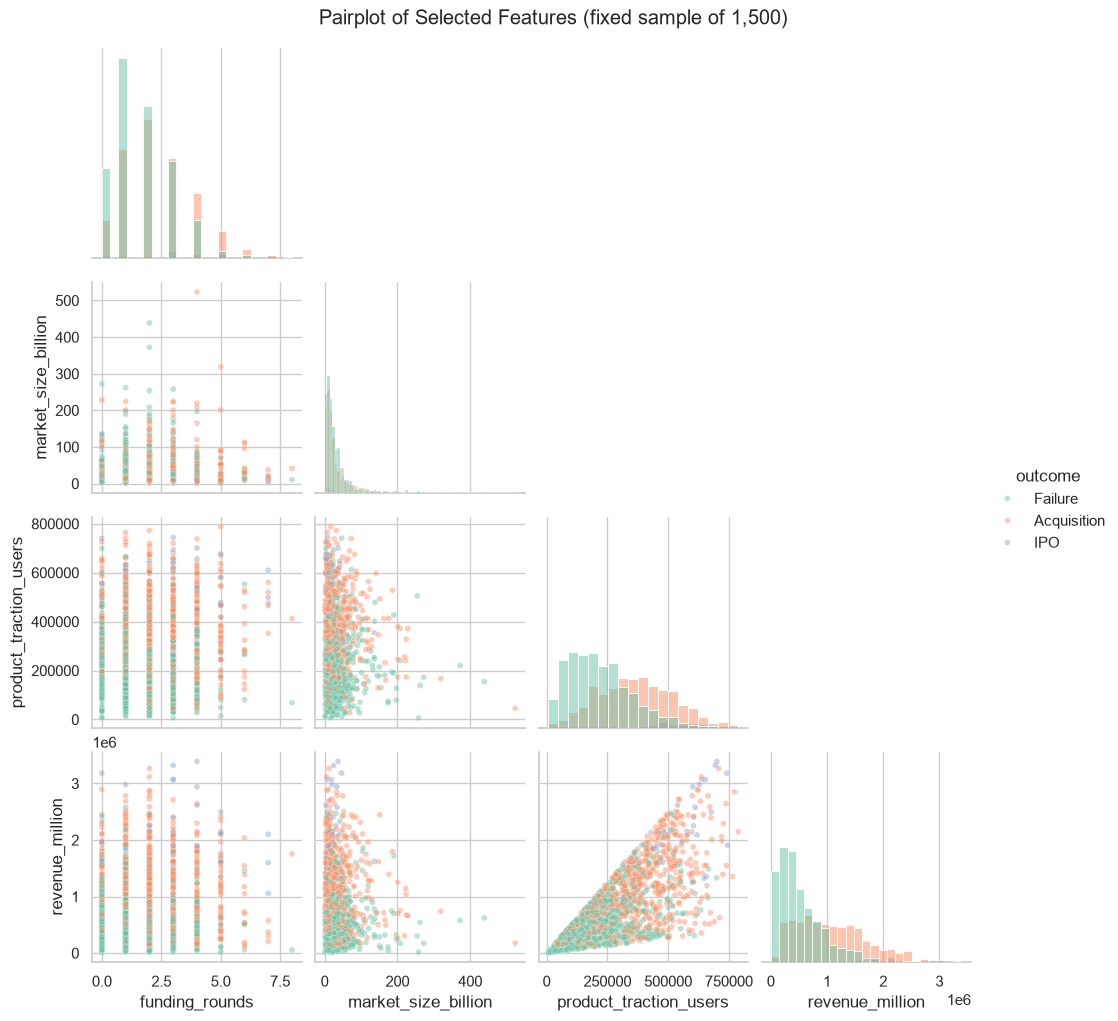

Multivariate visualisations used a fixed random sample of 1,500 rows; no source rows were modified.
Interpretation: assess whether outcome colours form visibly distinct regions or remain overlapped; strong overlap would indicate that individual two-feature projections are unlikely to separate classes by themselves.


In [23]:
multivariate_sample_size = min(1500, len(df))
multivariate_sample = df[numerical_features + ["outcome"]].sample(n=multivariate_sample_size, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=multivariate_sample, x="market_size_billion", y="revenue_million", hue="outcome", hue_order=["Failure", "Acquisition", "IPO"], alpha=0.55, palette="Set2", ax=axes[0])
axes[0].set_title("Market Size vs Revenue by Outcome")
axes[0].set_xlabel("Market size (billion)")
axes[0].set_ylabel("Revenue (million)")
sns.scatterplot(data=multivariate_sample, x="product_traction_users", y="burn_rate_million", hue="outcome", hue_order=["Failure", "Acquisition", "IPO"], alpha=0.55, palette="Set2", ax=axes[1])
axes[1].set_title("Product Traction vs Burn Rate by Outcome")
axes[1].set_xlabel("Product traction users")
axes[1].set_ylabel("Burn rate (million)")
for axis in axes:
    sns.move_legend(axis, "upper right", title="Outcome")
    sns.despine(ax=axis)
plt.tight_layout()
plt.show()

pairplot_features = ["funding_rounds", "market_size_billion", "product_traction_users", "revenue_million", "outcome"]
pair_grid = sns.pairplot(multivariate_sample[pairplot_features], hue="outcome", hue_order=["Failure", "Acquisition", "IPO"], corner=True, diag_kind="hist", plot_kws={"alpha": 0.45, "s": 18}, palette="Set2")
pair_grid.figure.suptitle(f"Pairplot of Selected Features (fixed sample of {multivariate_sample_size:,})", y=1.02)
plt.show()

print(f"Multivariate visualisations used a fixed random sample of {multivariate_sample_size:,} rows; no source rows were modified.")
print("Interpretation: assess whether outcome colours form visibly distinct regions or remain overlapped; strong overlap would indicate that individual two-feature projections are unlikely to separate classes by themselves.")

## 2.8 Key EDA Findings

The following summary consolidates the descriptive evidence produced above. It reports computed rankings and limitations rather than treating visual separation or correlation as proof of predictive power or causality.

In [24]:
top_skewed_features = numerical_descriptive["skewness"].abs().sort_values(ascending=False).head(3)
top_median_separation = median_ranges.head(3)
strongest_category_patterns = []
for column, tables in categorical_outcome_tables.items():
    percentages = tables["percentages"]
    for outcome in ["Failure", "Acquisition", "IPO"]:
        category = percentages[outcome].idxmax()
        strongest_category_patterns.append({
            "feature": column,
            "outcome": outcome,
            "category_with_highest_percentage": category,
            "percentage": percentages.loc[category, outcome],
            "category_count": int(tables["counts"].loc[category].sum())
        })
strongest_category_patterns = pd.DataFrame(strongest_category_patterns)

print("Target distribution:")
display(target_distribution)
print("Most skewed numerical features by absolute skewness:")
display(top_skewed_features.rename("absolute_skewness").to_frame().round(3))
print("Numerical features with the largest outcome-group median ranges:")
display(top_median_separation.rename("median_range").to_frame().round(3))
print("Highest within-category outcome percentages (sample sizes shown):")
display(strongest_category_patterns.round(2))
print("Strong Pearson correlation pairs:")
display(strong_correlation_pairs if not strong_correlation_pairs.empty else pd.DataFrame(columns=correlation_pairs.columns))

print("Key interpretations:")
print("- Numerical patterns: skewness, spread, and IQR flags identify distributions that may require careful scaling or robust modelling later, but no transformations are performed now.")
print("- Categorical patterns: outcome percentages differ across some categories, but rare categories and the small IPO class make estimates less stable.")
print("- Outcome relationships: grouped medians and plots identify candidate predictive features descriptively; overlap means these relationships should not be treated as deterministic rules.")
print("- Correlations: strong Pearson pairs, if any, may indicate redundant information and possible multicollinearity in future models.")
print("- Potentially useful predictors: prioritize features showing outcome-group separation, meaningful category differences, and/or stable relationships after checking sample sizes and later statistical evidence.")
print("- Limitations: this EDA is observational and descriptive; it does not test significance, establish causality, address temporal leakage, or validate out-of-sample predictive performance.")
print("Step 2 complete: EDA Areas 2.1?2.8 only. Step 3 statistical analysis has not been started.")

Target distribution:


,class_count,percentage
outcome,,
Acquisition,42335,42.34
Failure,55610,55.61
IPO,2055,2.05


Most skewed numerical features by absolute skewness:


,absolute_skewness
market_size_billion,5.262
burn_rate_million,3.346
revenue_million,1.255


Numerical features with the largest outcome-group median ranges:


,median_range
revenue_million,1710368.573
product_traction_users,341843.500
team_size,43.000


Highest within-category outcome percentages (sample sizes shown):


,feature,outcome,category_with_highest_percentage,percentage,category_count
0,investor_type,Failure,angel,55.89,25137
1,investor_type,Acquisition,none,42.73,24866
2,investor_type,IPO,angel,2.20,25137
3,sector,Failure,Fintech,56.32,14220
4,sector,Acquisition,Crypto,42.80,14456
5,sector,IPO,Climate,2.15,14412
6,founder_background,Failure,academic,56.19,20054
7,founder_background,Acquisition,serial_founder,42.78,14957
8,founder_background,IPO,academic,2.09,20054


Strong Pearson correlation pairs:


,feature_1,feature_2,pearson_r,absolute_r
46,revenue_million,product_traction_users,0.714043,0.714043


Key interpretations:
- Numerical patterns: skewness, spread, and IQR flags identify distributions that may require careful scaling or robust modelling later, but no transformations are performed now.
- Categorical patterns: outcome percentages differ across some categories, but rare categories and the small IPO class make estimates less stable.
- Outcome relationships: grouped medians and plots identify candidate predictive features descriptively; overlap means these relationships should not be treated as deterministic rules.
- Correlations: strong Pearson pairs, if any, may indicate redundant information and possible multicollinearity in future models.
- Potentially useful predictors: prioritize features showing outcome-group separation, meaningful category differences, and/or stable relationships after checking sample sizes and later statistical evidence.
- Limitations: this EDA is observational and descriptive; it does not test significance, establish causality, address temporal lea

# Step 3 ? Statistical Analysis

Statistical tests are used to assess whether the descriptive patterns identified in EDA are compatible with no association in the population represented by this dataset. Results are interpreted with effect sizes, confidence intervals where appropriate, the severe IPO class imbalance, and the dataset's sampling/provenance limitations. Statistical association does not establish causation.

## 3.1 Hypothesis Formulation

The hypotheses below are based on the completed EDA. Numerical hypotheses focus on the seven measured numeric features because EDA showed outcome-group variation across the feature set, with the largest median separations in revenue, product traction, and team size and substantial skew in market size, burn rate, and revenue. Categorical hypotheses cover the three categorical predictors because EDA showed different outcome compositions across their levels. These are pre-specified omnibus questions; pairwise comparisons are reserved for features whose omnibus test is significant.

In [25]:
hypothesis_rows = [
    {
        "hypothesis_id": "N1",
        "variables": "Each numerical feature vs outcome",
        "H0": "The distribution of the numerical feature is the same across Failure, Acquisition, and IPO.",
        "H1": "At least one outcome group has a different distribution.",
        "rationale": "EDA showed outcome-group median differences and skewed/extreme financial variables; Kruskal-Wallis is appropriate for a three-group distribution comparison without requiring normality."
    },
    {
        "hypothesis_id": "C1",
        "variables": "investor_type and outcome",
        "H0": "investor_type and outcome are independent.",
        "H1": "investor_type and outcome are associated.",
        "rationale": "EDA showed different outcome percentages across investor categories."
    },
    {
        "hypothesis_id": "C2",
        "variables": "sector and outcome",
        "H0": "sector and outcome are independent.",
        "H1": "sector and outcome are associated.",
        "rationale": "EDA showed different outcome percentages across sectors."
    },
    {
        "hypothesis_id": "C3",
        "variables": "founder_background and outcome",
        "H0": "founder_background and outcome are independent.",
        "H1": "founder_background and outcome are associated.",
        "rationale": "EDA showed different outcome percentages across founder-background categories."
    }
]
hypothesis_summary = pd.DataFrame(hypothesis_rows)
display(hypothesis_summary)
print("The null hypotheses are tested at an unadjusted alpha of 0.05, with Holm correction applied within each family of multiple comparisons.")

,hypothesis_id,variables,H0,H1,rationale
0,N1,Each numerical feature vs outcome,The distribution of the numerical feature is t...,At least one outcome group has a different dis...,EDA showed outcome-group median differences an...
1,C1,investor_type and outcome,investor_type and outcome are independent.,investor_type and outcome are associated.,EDA showed different outcome percentages acros...
2,C2,sector and outcome,sector and outcome are independent.,sector and outcome are associated.,EDA showed different outcome percentages acros...
3,C3,founder_background and outcome,founder_background and outcome are independent.,founder_background and outcome are associated.,EDA showed different outcome percentages acros...


The null hypotheses are tested at an unadjusted alpha of 0.05, with Holm correction applied within each family of multiple comparisons.


## 3.2 Numerical Features vs Outcome

The numerical variables are strongly non-normal in several cases according to the EDA skewness results, and the IPO group is much smaller than the other classes. Rather than relying on normality-based ANOVA assumptions, the Kruskal-Wallis H-test compares the rank distributions across the three independent outcome groups. It tests an omnibus null hypothesis only; pairwise Mann-Whitney U tests are run for features with a significant omnibus result. Holm correction controls the family-wise error rate across the pairwise follow-up tests.

In [26]:
from itertools import combinations
from scipy import stats

alpha = 0.05
outcome_order = ["Failure", "Acquisition", "IPO"]

def format_p_value(value):
    return "<1e-300" if value == 0 else f"{value:.3e}"

# A simple Holm step-down adjustment avoids requiring an additional package.
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan, dtype=float)
    valid = np.isfinite(p_values)
    if not valid.any():
        return adjusted
    valid_indices = np.where(valid)[0]
    order = valid_indices[np.argsort(p_values[valid])]
    m = len(order)
    running_max = 0.0
    for rank, index in enumerate(order):
        running_max = max(running_max, (m - rank) * p_values[index])
        adjusted[index] = min(running_max, 1.0)
    return adjusted

def rank_biserial_effect(x, y):
    result = stats.mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")
    return 2 * result.statistic / (len(x) * len(y)) - 1

kruskal_rows = []
for feature in numerical_features:
    groups = [df.loc[df["outcome"] == outcome, feature].dropna() for outcome in outcome_order]
    h_statistic, p_value = stats.kruskal(*groups)
    kruskal_rows.append({
        "feature": feature,
        "H_statistic": h_statistic,
        "p_value": p_value,
        "significant_at_0.05": p_value < alpha,
        "assumption_note": "Rank-based omnibus test; robust to non-normality, but independent observations and comparable distribution shapes remain relevant."
    })
kruskal_results = pd.DataFrame(kruskal_rows)
kruskal_results["holm_p_value"] = holm_adjust(kruskal_results["p_value"].to_numpy())
kruskal_results["significant_after_holm"] = kruskal_results["holm_p_value"] < alpha
print("Kruskal-Wallis omnibus results:")
kruskal_display = kruskal_results.sort_values("holm_p_value").round(5).copy()
kruskal_display["p_value"] = kruskal_results.sort_values("holm_p_value")["p_value"].map(format_p_value).to_numpy()
kruskal_display["holm_p_value"] = kruskal_results.sort_values("holm_p_value")["holm_p_value"].map(format_p_value).to_numpy()
display(kruskal_display)

significant_features = kruskal_results.loc[kruskal_results["significant_after_holm"], "feature"].tolist()
pairwise_rows = []
for feature in significant_features:
    for first, second in combinations(outcome_order, 2):
        x = df.loc[df["outcome"] == first, feature].dropna()
        y = df.loc[df["outcome"] == second, feature].dropna()
        test = stats.mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")
        pairwise_rows.append({
            "feature": feature,
            "group_1": first,
            "group_2": second,
            "U_statistic": test.statistic,
            "raw_p_value": test.pvalue,
            "rank_biserial_effect": rank_biserial_effect(x, y),
            "median_group_1": x.median(),
            "median_group_2": y.median(),
            "n_group_1": len(x),
            "n_group_2": len(y)
        })
pairwise_results = pd.DataFrame(pairwise_rows)
if not pairwise_results.empty:
    pairwise_results["holm_p_value"] = holm_adjust(pairwise_results["raw_p_value"].to_numpy())
    pairwise_results["significant_after_holm"] = pairwise_results["holm_p_value"] < alpha
else:
    pairwise_results["holm_p_value"] = []
    pairwise_results["significant_after_holm"] = []
print("Holm-adjusted Mann-Whitney U post-hoc results for significant omnibus features:")
if not pairwise_results.empty:
    pairwise_display = pairwise_results.sort_values("holm_p_value").round(5).copy()
    pairwise_display["raw_p_value"] = pairwise_results.sort_values("holm_p_value")["raw_p_value"].map(format_p_value).to_numpy()
    pairwise_display["holm_p_value"] = pairwise_results.sort_values("holm_p_value")["holm_p_value"].map(format_p_value).to_numpy()
    display(pairwise_display)
else:
    display(pairwise_results)

print("Interpretation: a significant adjusted p-value indicates evidence that outcome groups differ in the tested rank distributions, not that the feature causes the outcome. Rank-biserial effects and median differences should be considered to judge practical importance, especially given the 100,000-record sample and small IPO class.")

Kruskal-Wallis omnibus results:


,feature,H_statistic,p_value,significant_at_0.05,assumption_note,holm_p_value,significant_after_holm
0,funding_rounds,5534.72922,<1e-300,True,Rank-based omnibus test; robust to non-normali...,<1e-300,True
1,founder_experience_years,4097.73517,<1e-300,True,Rank-based omnibus test; robust to non-normali...,<1e-300,True
6,revenue_million,21898.25413,<1e-300,True,Rank-based omnibus test; robust to non-normali...,<1e-300,True
4,product_traction_users,19037.33452,<1e-300,True,Rank-based omnibus test; robust to non-normali...,<1e-300,True
2,team_size,932.53498,3.181e-203,True,Rank-based omnibus test; robust to non-normali...,9.544e-203,True
3,market_size_billion,1.02335,5.995e-01,False,Rank-based omnibus test; robust to non-normali...,1.000e+00,False
5,burn_rate_million,1.04912,5.918e-01,False,Rank-based omnibus test; robust to non-normali...,1.000e+00,False


Holm-adjusted Mann-Whitney U post-hoc results for significant omnibus features:


,feature,group_1,group_2,U_statistic,raw_p_value,rank_biserial_effect,median_group_1,median_group_2,n_group_1,n_group_2,holm_p_value,significant_after_holm
0,funding_rounds,Failure,Acquisition,8.820540e+08,<1e-300,-0.25067,2.00000,2.000000e+00,55610,42335,<1e-300,True
3,founder_experience_years,Failure,Acquisition,9.140817e+08,<1e-300,-0.22346,10.00000,1.400000e+01,55610,42335,<1e-300,True
13,revenue_million,Failure,IPO,4.023169e+06,<1e-300,-0.92959,434142.60942,2.144511e+06,55610,2055,<1e-300,True
14,revenue_million,Acquisition,IPO,1.222947e+07,<1e-300,-0.71886,949165.71021,2.144511e+06,42335,2055,<1e-300,True
12,revenue_million,Failure,Acquisition,5.876898e+08,<1e-300,-0.50074,434142.60942,9.491657e+05,55610,42335,<1e-300,True
11,product_traction_users,Acquisition,IPO,1.545081e+07,<1e-300,-0.64480,342404.00000,5.477520e+05,42335,2055,<1e-300,True
10,product_traction_users,Failure,IPO,6.587228e+06,<1e-300,-0.88472,205908.50000,5.477520e+05,55610,2055,<1e-300,True
9,product_traction_users,Failure,Acquisition,6.284773e+08,<1e-300,-0.46609,205908.50000,3.424040e+05,55610,42335,<1e-300,True
1,funding_rounds,Failure,IPO,3.137748e+07,8.068e-281,-0.45086,2.00000,3.000000e+00,55610,2055,5.648e-280,True
4,founder_experience_years,Failure,IPO,3.549946e+07,8.992e-188,-0.37872,10.00000,1.700000e+01,55610,2055,5.395e-187,True


Interpretation: a significant adjusted p-value indicates evidence that outcome groups differ in the tested rank distributions, not that the feature causes the outcome. Rank-biserial effects and median differences should be considered to judge practical importance, especially given the 100,000-record sample and small IPO class.


## 3.3 Categorical Features vs Outcome

For each categorical feature, a contingency table is evaluated with a chi-square test of independence. Expected cell frequencies are checked explicitly. Cramer's V quantifies association strength on a 0-to-1 scale, so a very small p-value is not treated as evidence of a practically large relationship. With this dataset's large sample, chi-square significance can occur for small effects.

In [27]:
def cramers_v(contingency):
    chi2_value, _, _, _ = stats.chi2_contingency(contingency, correction=False)
    n = contingency.to_numpy().sum()
    rows, columns = contingency.shape
    return np.sqrt((chi2_value / n) / max(1, min(rows - 1, columns - 1)))

categorical_test_rows = []
for feature in categorical_features:
    contingency = pd.crosstab(df[feature], df["outcome"])
    chi2_value, p_value, degrees_freedom, expected = stats.chi2_contingency(contingency, correction=False)
    expected_minimum = expected.min()
    expected_below_5 = int((expected < 5).sum())
    categorical_test_rows.append({
        "feature": feature,
        "chi2_statistic": chi2_value,
        "degrees_of_freedom": degrees_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v(contingency),
        "minimum_expected_frequency": expected_minimum,
        "expected_cells_below_5": expected_below_5,
        "assumptions_satisfied": expected_below_5 == 0
    })
categorical_test_results = pd.DataFrame(categorical_test_rows)
categorical_test_results["holm_p_value"] = holm_adjust(categorical_test_results["p_value"].to_numpy())
categorical_test_results["significant_after_holm"] = categorical_test_results["holm_p_value"] < alpha
print("Chi-square tests of independence and Cramer's V:")
categorical_display = categorical_test_results.sort_values("holm_p_value").round(5).copy()
categorical_display["p_value"] = categorical_test_results.sort_values("holm_p_value")["p_value"].map(format_p_value).to_numpy()
categorical_display["holm_p_value"] = categorical_test_results.sort_values("holm_p_value")["holm_p_value"].map(format_p_value).to_numpy()
display(categorical_display)

for feature in categorical_features:
    contingency = pd.crosstab(df[feature], df["outcome"])
    _, _, _, expected = stats.chi2_contingency(contingency, correction=False)
    expected_table = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    print(f"Expected frequencies for {feature}:")
    display(expected_table.round(2))

print("Interpretation: all expected-frequency checks are reported so that the chi-square approximation is transparent. If any expected cell were below 5, category grouping or an exact/Monte Carlo alternative would need consideration; no categories are grouped automatically here.")

Chi-square tests of independence and Cramer's V:


,feature,chi2_statistic,degrees_of_freedom,p_value,cramers_v,minimum_expected_frequency,expected_cells_below_5,assumptions_satisfied,holm_p_value,significant_after_holm
0,investor_type,7.89225,6,2.461e-01,0.00628,301.46850,0,True,7.383e-01,False
1,sector,10.41409,12,5.797e-01,0.00722,289.22070,0,True,9.640e-01,False
2,founder_background,5.49571,6,4.820e-01,0.00524,307.36635,0,True,9.640e-01,False


Expected frequencies for investor_type:


outcome,Acquisition,Failure,IPO
investor_type,,,
angel,10641.75,13978.69,516.57
none,10527.02,13827.98,511.00
tier1_vc,6210.54,8157.99,301.47
tier2_vc,14955.69,19645.34,725.97


Expected frequencies for sector:


outcome,Acquisition,Failure,IPO
sector,,,
AI,5958.23,7826.55,289.22
Climate,6101.32,8014.51,296.17
Crypto,6119.95,8038.98,297.07
Ecommerce,5989.56,7867.70,290.74
Fintech,6020.04,7907.74,292.22
Health,6078.04,7983.93,295.04
SaaS,6067.88,7970.58,294.54


Expected frequencies for founder_background:


outcome,Acquisition,Failure,IPO
founder_background,,,
academic,8489.86,11152.03,412.11
ex_bigtech,10587.56,13907.50,513.93
first_time,16925.53,22232.88,821.59
serial_founder,6332.05,8317.59,307.37


Interpretation: all expected-frequency checks are reported so that the chi-square approximation is transparent. If any expected cell were below 5, category grouping or an exact/Monte Carlo alternative would need consideration; no categories are grouped automatically here.


## 3.4 Effect Sizes and Confidence Intervals

Because a very large sample can make small differences statistically significant, this section reports effect sizes. For numerical pairwise comparisons, rank-biserial correlation describes the direction and magnitude of rank separation. For significant pairwise comparisons, bootstrap 95% confidence intervals quantify the uncertainty around the difference in group medians. For categorical variables, Cramer's V is the effect size; bootstrap intervals are computed for V when the chi-square association remains significant after Holm correction. These intervals are descriptive bootstrap intervals, not a substitute for a sampling-design-based interval.

In [28]:
rng = np.random.default_rng(42)

def bootstrap_median_difference(x, y, iterations=1000):
    x = np.asarray(x)
    y = np.asarray(y)
    estimates = np.empty(iterations)
    for i in range(iterations):
        estimates[i] = np.median(rng.choice(x, size=len(x), replace=True)) - np.median(rng.choice(y, size=len(y), replace=True))
    return np.median(x) - np.median(y), np.quantile(estimates, [0.025, 0.975])

def bootstrap_cramers_v(data, feature, iterations=1000):
    values = data[[feature, "outcome"]].to_numpy()
    estimates = np.empty(iterations)
    for i in range(iterations):
        sample_indices = rng.integers(0, len(values), len(values))
        sample = pd.DataFrame(values[sample_indices], columns=[feature, "outcome"])
        estimates[i] = cramers_v(pd.crosstab(sample[feature], sample["outcome"]))
    observed = cramers_v(pd.crosstab(data[feature], data["outcome"]))
    return observed, np.quantile(estimates, [0.025, 0.975])

significant_pairwise = pairwise_results[pairwise_results["significant_after_holm"]].copy() if not pairwise_results.empty else pairwise_results.copy()
ci_rows = []
for _, row in significant_pairwise.iterrows():
    x = df.loc[df["outcome"] == row["group_1"], row["feature"]].dropna().to_numpy()
    y = df.loc[df["outcome"] == row["group_2"], row["feature"]].dropna().to_numpy()
    difference, interval = bootstrap_median_difference(x, y)
    ci_rows.append({
        "feature": row["feature"], "group_1": row["group_1"], "group_2": row["group_2"],
        "median_difference_group_1_minus_group_2": difference,
        "median_difference_ci_lower": interval[0],
        "median_difference_ci_upper": interval[1],
        "rank_biserial_effect": row["rank_biserial_effect"]
    })
numerical_effects = pd.DataFrame(ci_rows)
print("Numerical effect sizes and bootstrap 95% CIs for significant pairwise comparisons:")
display(numerical_effects.round(5) if not numerical_effects.empty else numerical_effects)

categorical_effect_rows = []
for _, row in categorical_test_results[categorical_test_results["significant_after_holm"]].iterrows():
    observed, interval = bootstrap_cramers_v(df, row["feature"])
    categorical_effect_rows.append({
        "feature": row["feature"], "cramers_v": observed,
        "cramers_v_ci_lower": interval[0], "cramers_v_ci_upper": interval[1]
    })
categorical_effects = pd.DataFrame(categorical_effect_rows)
print("Categorical effect sizes and bootstrap 95% CIs for significant associations:")
display(categorical_effects.round(5) if not categorical_effects.empty else categorical_effects)

print("Practical-significance guidance: effect sizes close to zero indicate weak separation/association even when p-values are small. Confidence intervals that are narrow reflect the large sample but do not correct for possible non-representative or synthetic data provenance.")

Numerical effect sizes and bootstrap 95% CIs for significant pairwise comparisons:


,feature,group_1,group_2,median_difference_group_1_minus_group_2,median_difference_ci_lower,median_difference_ci_upper,rank_biserial_effect
0,funding_rounds,Failure,Acquisition,0.000000e+00,0.000000e+00,0.000000e+00,-0.25067
1,funding_rounds,Failure,IPO,-1.000000e+00,-1.000000e+00,-1.000000e+00,-0.45086
2,funding_rounds,Acquisition,IPO,-1.000000e+00,-1.000000e+00,-1.000000e+00,-0.22448
3,founder_experience_years,Failure,Acquisition,-4.000000e+00,-4.000000e+00,-4.000000e+00,-0.22346
4,founder_experience_years,Failure,IPO,-7.000000e+00,-7.000000e+00,-7.000000e+00,-0.37872
5,founder_experience_years,Acquisition,IPO,-3.000000e+00,-3.000000e+00,-3.000000e+00,-0.16710
6,team_size,Failure,Acquisition,-2.400000e+01,-2.600000e+01,-2.200000e+01,-0.10565
7,team_size,Failure,IPO,-4.300000e+01,-5.100000e+01,-3.600000e+01,-0.19023
8,team_size,Acquisition,IPO,-1.900000e+01,-2.700000e+01,-1.200000e+01,-0.08794
9,product_traction_users,Failure,Acquisition,-1.364955e+05,-1.387949e+05,-1.338949e+05,-0.46609


Categorical effect sizes and bootstrap 95% CIs for significant associations:


""


Practical-significance guidance: effect sizes close to zero indicate weak separation/association even when p-values are small. Confidence intervals that are narrow reflect the large sample but do not correct for possible non-representative or synthetic data provenance.


## 3.5 Final Statistical Findings

This report consolidates the tests, adjusted decisions, effect sizes, and limitations. It distinguishes statistical evidence from practical importance and does not make causal claims.

In [29]:
significant_kruskal = kruskal_results[kruskal_results["significant_after_holm"]][["feature", "H_statistic", "holm_p_value"]]
non_significant_kruskal = kruskal_results[~kruskal_results["significant_after_holm"]][["feature", "H_statistic", "holm_p_value"]]
significant_categorical = categorical_test_results[categorical_test_results["significant_after_holm"]][["feature", "chi2_statistic", "degrees_of_freedom", "holm_p_value", "cramers_v"]]
non_significant_categorical = categorical_test_results[~categorical_test_results["significant_after_holm"]][["feature", "chi2_statistic", "degrees_of_freedom", "holm_p_value", "cramers_v"]]

print("Significant numerical omnibus relationships after Holm correction:")
significant_kruskal_display = significant_kruskal.round(5).copy()
significant_kruskal_display["holm_p_value"] = significant_kruskal["holm_p_value"].map(format_p_value)
display(significant_kruskal_display)
print("Non-significant numerical omnibus relationships after Holm correction:")
non_significant_kruskal_display = non_significant_kruskal.round(5).copy()
non_significant_kruskal_display["holm_p_value"] = non_significant_kruskal["holm_p_value"].map(format_p_value)
display(non_significant_kruskal_display)
print("Significant categorical relationships after Holm correction:")
significant_categorical_display = significant_categorical.round(5).copy()
significant_categorical_display["holm_p_value"] = significant_categorical["holm_p_value"].map(format_p_value)
display(significant_categorical_display)
print("Non-significant categorical relationships after Holm correction:")
non_significant_categorical_display = non_significant_categorical.round(5).copy()
non_significant_categorical_display["holm_p_value"] = non_significant_categorical["holm_p_value"].map(format_p_value)
display(non_significant_categorical_display)

print("Final interpretation:")
print("- Hypotheses tested: one omnibus distribution hypothesis for each numerical feature and one independence hypothesis for each categorical feature.")
print("- Numerical tests: Kruskal-Wallis was selected because EDA showed skewness and extreme values; Mann-Whitney U follow-ups were restricted to significant omnibus results and Holm-adjusted.")
print("- Categorical tests: chi-square assumptions were checked through expected frequencies and Cramer's V was reported for magnitude.")
print("- Practical significance: use rank-biserial effects, median differences, Cramer's V, and bootstrap intervals rather than p-values alone.")
print("- Limitations: observations are assumed independent for these tests; the IPO class is small; multiple comparisons remain a consideration; and inference depends on how the dataset was generated and sampled. If synthetic, results describe the synthetic data-generating process rather than real-world startup populations.")
print("- Features worth investigating during later machine learning: features with adjusted statistical evidence and non-trivial effect sizes, while retaining correlated product traction/revenue features for model-level validation rather than removing them now.")
print("Step 3 complete: statistical analysis only. Feature engineering, preprocessing, and machine learning have not been started.")

Significant numerical omnibus relationships after Holm correction:


,feature,H_statistic,holm_p_value
0,funding_rounds,5534.72922,<1e-300
1,founder_experience_years,4097.73517,<1e-300
2,team_size,932.53498,9.544e-203
4,product_traction_users,19037.33452,<1e-300
6,revenue_million,21898.25413,<1e-300


Non-significant numerical omnibus relationships after Holm correction:


,feature,H_statistic,holm_p_value
3,market_size_billion,1.02335,1.000e+00
5,burn_rate_million,1.04912,1.000e+00


Significant categorical relationships after Holm correction:


,feature,chi2_statistic,degrees_of_freedom,holm_p_value,cramers_v


Non-significant categorical relationships after Holm correction:


,feature,chi2_statistic,degrees_of_freedom,holm_p_value,cramers_v
0,investor_type,7.89225,6,7.383e-01,0.00628
1,sector,10.41409,12,9.640e-01,0.00722
2,founder_background,5.49571,6,9.640e-01,0.00524


Final interpretation:
- Hypotheses tested: one omnibus distribution hypothesis for each numerical feature and one independence hypothesis for each categorical feature.
- Numerical tests: Kruskal-Wallis was selected because EDA showed skewness and extreme values; Mann-Whitney U follow-ups were restricted to significant omnibus results and Holm-adjusted.
- Categorical tests: chi-square assumptions were checked through expected frequencies and Cramer's V was reported for magnitude.
- Practical significance: use rank-biserial effects, median differences, Cramer's V, and bootstrap intervals rather than p-values alone.
- Limitations: observations are assumed independent for these tests; the IPO class is small; multiple comparisons remain a consideration; and inference depends on how the dataset was generated and sampled. If synthetic, results describe the synthetic data-generating process rather than real-world startup populations.
- Features worth investigating during later machine learning

# Step 4 ? Feature Engineering

Feature engineering is restricted to interpretable, mathematically defined representations supported by the completed data-quality, EDA, and statistical findings. The raw `df` dataframe and source CSV remain unchanged. The engineered feature table is created separately and does not use `outcome` to construct predictors.

## 4.1 Review of Existing Features

Step 2 showed that `revenue_million` and `product_traction_users` had the largest outcome-group median differences, while `team_size` also differed descriptively. `market_size_billion`, `burn_rate_million`, and `revenue_million` were strongly right-skewed. Step 3 found significant rank-distribution differences for funding rounds, founder experience, team size, product traction, and revenue, while the three categorical features had negligible Cramer's V values and non-significant adjusted chi-square tests. The EDA also found a Pearson correlation of approximately 0.714 between product traction and revenue.

These findings motivate a small number of ratio features that express operating efficiency or activity relative to available resources. They do not justify arbitrary category regrouping or target-derived encodings.

In [30]:
original_feature_inventory = pd.DataFrame({
    "feature": numerical_features + categorical_features,
    "type": ["numerical"] * len(numerical_features) + ["categorical"] * len(categorical_features),
    "engineering_review": [
        "Candidate denominator for funding activity per experience.",
        "Candidate denominator for funding activity; zero values require safe handling.",
        "Candidate denominator for traction per employee; observed positive values.",
        "Right-skewed in EDA; retain original and consider log1p later in preprocessing.",
        "Outcome-separated and correlated with revenue; candidate numerator for efficiency/scale ratios.",
        "Right-skewed in EDA; candidate denominator for revenue-to-burn efficiency.",
        "Outcome-separated and right-skewed; candidate numerator for revenue-to-burn efficiency."
    ] + [
        "Levels were consistent in Step 1; no justified regrouping identified.",
        "Levels were consistent in Step 1; no justified regrouping identified.",
        "Levels were consistent in Step 1; no justified regrouping identified."
    ]
})
display(original_feature_inventory)

engineering_opportunities = pd.DataFrame({
    "proposal": [
        "Revenue-to-burn ratio", "Traction per employee", "Funding rounds per founder experience",
        "Team-size categories", "Rare-category grouping", "Target encoding"
    ],
    "decision": ["retain", "retain", "retain", "reject for now", "reject for now", "reject"],
    "reason": [
        "Interpretable operating efficiency measure; revenue divided by burn rate.",
        "Interpretable productivity/scale proxy; users divided by team size.",
        "Interpretable funding activity relative to founder experience.",
        "No domain thresholds are supplied; arbitrary bins could discard information and create unstable boundaries.",
        "Step 1 found no case/whitespace variants and EDA did not show a justified rare-level consolidation.",
        "Would use the target to construct predictors and risks leakage; prohibited at this stage."
    ]
})
display(engineering_opportunities)

,feature,type,engineering_review
0,funding_rounds,numerical,Candidate denominator for funding activity per...
1,founder_experience_years,numerical,Candidate denominator for funding activity; ze...
2,team_size,numerical,Candidate denominator for traction per employe...
3,market_size_billion,numerical,Right-skewed in EDA; retain original and consi...
4,product_traction_users,numerical,Outcome-separated and correlated with revenue;...
5,burn_rate_million,numerical,Right-skewed in EDA; candidate denominator for...
6,revenue_million,numerical,Outcome-separated and right-skewed; candidate ...
7,investor_type,categorical,Levels were consistent in Step 1; no justified...
8,sector,categorical,Levels were consistent in Step 1; no justified...
9,founder_background,categorical,Levels were consistent in Step 1; no justified...


,proposal,decision,reason
0,Revenue-to-burn ratio,retain,Interpretable operating efficiency measure; re...
1,Traction per employee,retain,Interpretable productivity/scale proxy; users ...
2,Funding rounds per founder experience,retain,Interpretable funding activity relative to fou...
3,Team-size categories,reject for now,No domain thresholds are supplied; arbitrary b...
4,Rare-category grouping,reject for now,Step 1 found no case/whitespace variants and E...
5,Target encoding,reject,Would use the target to construct predictors a...


## 4.2 Numerical Feature Engineering

The retained ratios are defined as follows:

- **Revenue-to-burn ratio** = `revenue_million / burn_rate_million`. This measures revenue generated per unit of reported burn. A zero denominator is represented as missing rather than infinity.
- **Traction per employee** = `product_traction_users / team_size`. This measures user traction relative to team size. A zero team size is represented as missing.
- **Funding rounds per founder experience** = `funding_rounds / founder_experience_years`. This measures funding activity relative to founder experience. Zero experience is represented as missing.

No outliers are removed and no target information is used. Team-size categories are evaluated from the observed distribution but are not automatically retained.

Engineered numerical feature summary:


,count,mean,std,min,25%,50%,75%,max,missing_count,zero_count
revenue_to_burn_ratio,100000.0,88789.453,126577.409,61.621,20738.582,48343.249,106400.962,3962938.664,0,0
traction_per_employee,100000.0,5083.758,14112.780,3.894,1011.641,1856.955,3759.648,416165.500,0,0
funding_rounds_per_founder_experience,96022.0,0.315,0.552,0.000,0.071,0.154,0.312,8.000,3978,13024


Undefined ratio counts caused by zero denominators:


,undefined_count
revenue_to_burn_ratio,0
traction_per_employee,0
funding_rounds_per_founder_experience,3978


,quantile,team_size
0,25th percentile,76.0
1,50th percentile,151.0
2,75th percentile,226.0


Decision: team-size categories are not added because quartile bins would be data-dependent and no domain threshold or clear categorical pattern justifies replacing the continuous feature. The original team_size remains available.


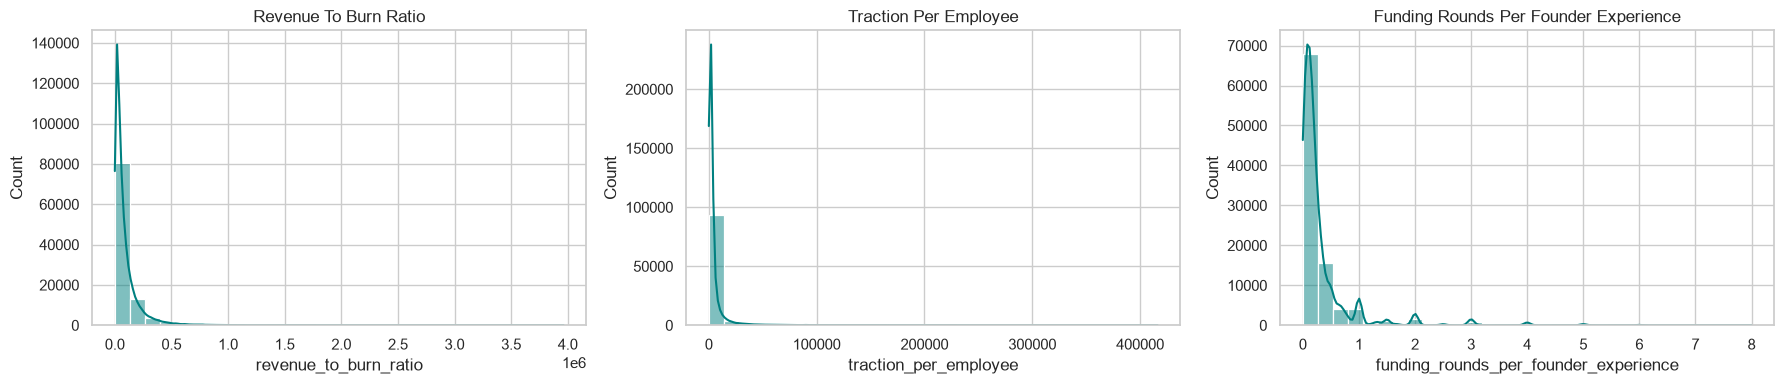

Ratios are retained as additional representations; original numerator and denominator features are not removed.


In [31]:
engineered_features = df[numerical_features + categorical_features].copy()

# Safe division returns NaN for undefined zero-denominator cases instead of infinity.
def safe_divide(numerator, denominator):
    numerator = numerator.astype(float)
    denominator = denominator.astype(float)
    return pd.Series(
        np.divide(
            numerator.to_numpy(),
            denominator.to_numpy(),
            out=np.full(len(numerator), np.nan, dtype=float),
            where=denominator.to_numpy() != 0
        ),
        index=numerator.index
    )

engineered_features["revenue_to_burn_ratio"] = safe_divide(
    df["revenue_million"], df["burn_rate_million"]
)
engineered_features["traction_per_employee"] = safe_divide(
    df["product_traction_users"], df["team_size"]
)
engineered_features["funding_rounds_per_founder_experience"] = safe_divide(
    df["funding_rounds"], df["founder_experience_years"]
)

engineered_feature_names = [
    "revenue_to_burn_ratio",
    "traction_per_employee",
    "funding_rounds_per_founder_experience"
]
engineered_summary = engineered_features[engineered_feature_names].describe().T
engineered_summary["missing_count"] = engineered_features[engineered_feature_names].isna().sum()
engineered_summary["zero_count"] = (engineered_features[engineered_feature_names] == 0).sum()
print("Engineered numerical feature summary:")
display(engineered_summary.round(3))
print("Undefined ratio counts caused by zero denominators:")
display(engineered_features[engineered_feature_names].isna().sum().rename("undefined_count").to_frame())

team_size_quantiles = df["team_size"].quantile([0.25, 0.5, 0.75])
team_size_distribution = pd.DataFrame({
    "quantile": ["25th percentile", "50th percentile", "75th percentile"],
    "team_size": team_size_quantiles.to_numpy()
})
display(team_size_distribution)
print("Decision: team-size categories are not added because quartile bins would be data-dependent and no domain threshold or clear categorical pattern justifies replacing the continuous feature. The original team_size remains available.")

fig, axes = plt.subplots(1, len(engineered_feature_names), figsize=(18, 4))
for axis, feature in zip(np.ravel(axes), engineered_feature_names):
    sns.histplot(engineered_features[feature].dropna(), bins=30, kde=True, color="teal", ax=axis)
    axis.set_title(feature.replace("_", " ").title())
    axis.set_xlabel(feature)
    axis.set_ylabel("Count")
plt.tight_layout()
plt.show()
print("Ratios are retained as additional representations; original numerator and denominator features are not removed.")

## 4.3 Categorical Feature Engineering

Step 1 found no case- or whitespace-only category variants, and Step 2 showed that all existing categories have adequate sample sizes for the observed comparisons. Therefore, no categorical labels are standardized or grouped. Arbitrary grouping would reduce interpretability and could hide real differences. No target encoding is performed because it would use outcome information and should only be designed inside a leakage-safe training pipeline later.

In [32]:
categorical_engineering_review = []
for feature in categorical_features:
    counts = df[feature].value_counts(dropna=False)
    categorical_engineering_review.append({
        "feature": feature,
        "level_count": counts.size,
        "smallest_level_count": int(counts.min()),
        "smallest_level_percentage": counts.min() / len(df) * 100,
        "label_variants_detected": "No",
        "decision": "retain original labels"
    })
categorical_engineering_review = pd.DataFrame(categorical_engineering_review)
display(categorical_engineering_review.round(3))
print("No categorical regrouping or standardisation was performed; all original categorical predictors are retained.")

,feature,level_count,smallest_level_count,smallest_level_percentage,label_variants_detected,decision
0,investor_type,4,14670,14.670,No,retain original labels
1,sector,7,14074,14.074,No,retain original labels
2,founder_background,4,14957,14.957,No,retain original labels


No categorical regrouping or standardisation was performed; all original categorical predictors are retained.


## 4.4 Feature Transformation Investigation

EDA identified strong right skew in `market_size_billion`, `burn_rate_million`, and `revenue_million`, with milder skew in some other variables. A `log1p` transformation could make these distributions easier for distance-based, linear, or regularized models to use, but transformation and scaling belong in the Step 5 preprocessing pipeline so that parameters are fitted on training data only. The original variables remain available and no transformation is applied here.

In [33]:
skewness_review = df[numerical_features].skew().sort_values(key=lambda values: values.abs(), ascending=False).rename("skewness").to_frame()
skewness_review["absolute_skewness"] = skewness_review["skewness"].abs()
skewness_review["log1p_candidate"] = skewness_review["absolute_skewness"] > 1
display(skewness_review.round(3))
print("Recommended for later preprocessing review:", skewness_review.index[skewness_review["log1p_candidate"]].tolist())
print("Tree-based models are generally less sensitive to monotonic scale changes; linear, distance-based, and regularized models may benefit more from distribution-aware transformations. Any transformation must be fitted using training data only.")

,skewness,absolute_skewness,log1p_candidate
market_size_billion,5.262,5.262,True
burn_rate_million,3.346,3.346,True
revenue_million,1.255,1.255,True
funding_rounds,0.694,0.694,False
product_traction_users,0.586,0.586,False
founder_experience_years,-0.009,0.009,False
team_size,-0.005,0.005,False


Recommended for later preprocessing review: ['market_size_billion', 'burn_rate_million', 'revenue_million']
Tree-based models are generally less sensitive to monotonic scale changes; linear, distance-based, and regularized models may benefit more from distribution-aware transformations. Any transformation must be fitted using training data only.


## 4.5 Feature Redundancy and Data Leakage

Engineered features are checked against the original numerical variables using Pearson correlations. High correlation is documented rather than used as an automatic deletion rule because correlated variables can still provide complementary information to some models. Leakage checks verify that `outcome` is absent from the engineered predictors and that no feature is calculated from target values or future observations.

In [34]:
all_engineered_numerical = numerical_features + engineered_feature_names
engineered_correlation = engineered_features[all_engineered_numerical].corr(method="pearson")
engineered_pairs = engineered_correlation.where(np.tril(np.ones(engineered_correlation.shape), k=-1).astype(bool)).stack().reset_index()
engineered_pairs.columns = ["feature_1", "feature_2", "pearson_r"]
engineered_pairs["absolute_r"] = engineered_pairs["pearson_r"].abs()
redundancy_pairs = engineered_pairs[engineered_pairs["absolute_r"] >= 0.80].sort_values("absolute_r", ascending=False)
print("Strong correlations among original and engineered numerical features (|r| >= 0.80):")
display(redundancy_pairs if not redundancy_pairs.empty else pd.DataFrame(columns=engineered_pairs.columns))

predictor_columns_engineered = numerical_features + categorical_features + engineered_feature_names
leakage_columns = [column for column in predictor_columns_engineered if column == target_column or "outcome" in column.casefold()]
raw_snapshot = df.copy(deep=True)
print("Target included in engineered predictors:", target_column in predictor_columns_engineered)
print("Leakage-named predictor columns:", leakage_columns)
print("Raw dataframe unchanged after engineering:", raw_snapshot.equals(df))
print("The existing product-traction/revenue correlation and any ratio correlations are retained as concerns for Step 5 model-pipeline review; no features are removed solely because they correlate strongly.")

Strong correlations among original and engineered numerical features (|r| >= 0.80):


,feature_1,feature_2,pearson_r,absolute_r


Target included in engineered predictors: False
Leakage-named predictor columns: []
Raw dataframe unchanged after engineering: True
The existing product-traction/revenue correlation and any ratio correlations are retained as concerns for Step 5 model-pipeline review; no features are removed solely because they correlate strongly.


## 4.6 Finalise the Feature Set

The engineered table contains the original predictors plus only the three retained ratios. The target is copied separately for later supervised modelling, but it is never used to calculate a predictor. The raw `df` dataframe remains the source of truth.

In [35]:
original_feature_table = pd.DataFrame({
    "feature": numerical_features + categorical_features,
    "feature_type": ["numerical"] * len(numerical_features) + ["categorical"] * len(categorical_features),
    "status": "original feature retained"
})

engineered_feature_table = pd.DataFrame({
    "feature": engineered_feature_names,
    "mathematical_definition": [
        "revenue_million / burn_rate_million, undefined when burn_rate_million == 0",
        "product_traction_users / team_size, undefined when team_size == 0",
        "funding_rounds / founder_experience_years, undefined when founder_experience_years == 0"
    ],
    "interpretation": [
        "Reported revenue generated per unit of reported burn.",
        "Product traction users relative to team size.",
        "Funding activity relative to founder experience."
    ],
    "status": "retained engineered feature"
})

display(original_feature_table)
display(engineered_feature_table)

engineered_dataset = engineered_features.copy()
engineered_dataset[target_column] = df[target_column].copy()
target_series = df[target_column].copy()
final_predictor_features = engineered_feature_names + numerical_features + categorical_features
final_predictor_features = list(dict.fromkeys(final_predictor_features))

print("Final predictor feature list:")
print(final_predictor_features)
print("Target kept separately:", target_column)
print("Engineered dataset shape:", engineered_dataset.shape)
print("Raw CSV/dataframe was not modified; engineered_dataset is a separate table.")
print("Step 4 decisions to carry into Step 5:")
print("- Fit any imputation, log transformation, scaling, and categorical encoding inside the training-only preprocessing pipeline.")
print("- Preserve original features alongside the three ratios; evaluate redundancy during model validation rather than deleting by correlation alone.")
print("- Handle undefined ratio values explicitly if zero denominators occur in future data.")
print("- Keep outcome out of all predictor transformations and use stratified splitting because IPO is a small class.")

,feature,feature_type,status
0,funding_rounds,numerical,original feature retained
1,founder_experience_years,numerical,original feature retained
2,team_size,numerical,original feature retained
3,market_size_billion,numerical,original feature retained
4,product_traction_users,numerical,original feature retained
5,burn_rate_million,numerical,original feature retained
6,revenue_million,numerical,original feature retained
7,investor_type,categorical,original feature retained
8,sector,categorical,original feature retained
9,founder_background,categorical,original feature retained


,feature,mathematical_definition,interpretation,status
0,revenue_to_burn_ratio,"revenue_million / burn_rate_million, undefined...",Reported revenue generated per unit of reporte...,retained engineered feature
1,traction_per_employee,"product_traction_users / team_size, undefined ...",Product traction users relative to team size.,retained engineered feature
2,funding_rounds_per_founder_experience,"funding_rounds / founder_experience_years, und...",Funding activity relative to founder experience.,retained engineered feature


Final predictor feature list:
['revenue_to_burn_ratio', 'traction_per_employee', 'funding_rounds_per_founder_experience', 'funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million', 'investor_type', 'sector', 'founder_background']
Target kept separately: outcome
Engineered dataset shape: (100000, 14)
Raw CSV/dataframe was not modified; engineered_dataset is a separate table.
Step 4 decisions to carry into Step 5:
- Fit any imputation, log transformation, scaling, and categorical encoding inside the training-only preprocessing pipeline.
- Preserve original features alongside the three ratios; evaluate redundancy during model validation rather than deleting by correlation alone.
- Handle undefined ratio values explicitly if zero denominators occur in future data.
- Keep outcome out of all predictor transformations and use stratified splitting because IPO is a small class.


## Step 4 Feature Engineering Summary

Three engineered features were retained because they have clear mathematical definitions and interpretable startup meaning: revenue-to-burn ratio, traction per employee, and funding rounds per founder experience. Team-size categories, rare-category grouping, label standardisation, and target encoding were rejected because the observed data did not justify them or they would risk information leakage. Highly skewed original variables are flagged for possible training-only transformation in Step 5, but remain unmodified here. No raw records were changed, no target-derived predictor was created, and no model was trained.

### Feature engineering audit

The retained ratios are mathematically valid descriptive representations, not causal measures:

- `revenue_to_burn_ratio = revenue_million / burn_rate_million`: revenue relative to reported burn; zero burn produces an undefined value handled by training-fitted imputation.
- `traction_per_employee = product_traction_users / team_size`: reported users relative to team size; zero team size is handled safely.
- `funding_rounds_per_founder_experience = funding_rounds / founder_experience_years`: funding activity relative to reported founder experience; zero experience produces an undefined value handled by training-fitted imputation.

The target `outcome` was not used to construct these features. Their interpretation remains limited because the dataset has no timestamps and ratios can share information with their component variables.

# Step 5 ? Data Preprocessing

This step converts the final Step 4 feature table into leakage-safe training and testing matrices. The raw CSV and the original `df` dataframe are not modified. No model is trained and no model metrics are calculated.

## 5.1 Review the Final Feature Set

Step 4 retained the original numerical predictors, the original nominal categorical predictors, and three interpretable ratio features: `revenue_to_burn_ratio`, `traction_per_employee`, and `funding_rounds_per_founder_experience`. Team-size bins, arbitrary rare-category grouping, label standardisation, and target encoding were rejected. The target `outcome` is kept exclusively as the response variable.

In [36]:
preprocessing_feature_review = pd.DataFrame({
    "feature": final_predictor_features,
    "source": [
        "engineered" if feature in engineered_feature_names else "original"
        for feature in final_predictor_features
    ],
    "role": "predictor"
})
display(preprocessing_feature_review)
print("Target variable:", target_column)
print("Target included in predictors:", target_column in final_predictor_features)
print("Retained engineered features:", engineered_feature_names)
print("Rejected proposals: team-size categories, rare-category grouping, and target encoding.")

,feature,source,role
0,revenue_to_burn_ratio,engineered,predictor
1,traction_per_employee,engineered,predictor
2,funding_rounds_per_founder_experience,engineered,predictor
3,funding_rounds,original,predictor
4,founder_experience_years,original,predictor
5,team_size,original,predictor
6,market_size_billion,original,predictor
7,product_traction_users,original,predictor
8,burn_rate_million,original,predictor
9,revenue_million,original,predictor


Target variable: outcome
Target included in predictors: False
Retained engineered features: ['revenue_to_burn_ratio', 'traction_per_employee', 'funding_rounds_per_founder_experience']
Rejected proposals: team-size categories, rare-category grouping, and target encoding.


## 5.2 Separate Features and Target

`X` contains only the final predictors from Step 4, while `y` contains `outcome`. The target is removed before any split or preprocessing to prevent it from entering the feature matrix.

In [37]:
X = engineered_dataset[final_predictor_features].copy()
y = engineered_dataset[target_column].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target in X:", target_column in X.columns)
print("Predictor columns:")
print(X.columns.tolist())
print("Target distribution:")
display(y.value_counts().rename("count").to_frame().assign(percentage=lambda table: table["count"] / len(y) * 100).round(2))

X shape: (100000, 13)
y shape: (100000,)
Target in X: False
Predictor columns:
['revenue_to_burn_ratio', 'traction_per_employee', 'funding_rounds_per_founder_experience', 'funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million', 'investor_type', 'sector', 'founder_background']
Target distribution:


,count,percentage
outcome,,
Failure,55610,55.61
Acquisition,42335,42.34
IPO,2055,2.05


## 5.3 Stratified Train-Test Split

An 80:20 split is created with `random_state=42` and stratification by `y`. Stratification preserves the observed class proportions approximately in both partitions, which is especially important because IPO is the minority class. The test set is held out and is not used to fit or choose preprocessing steps.

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

split_summary = pd.DataFrame({
    "split": ["training", "testing"],
    "sample_count": [len(X_train), len(X_test)],
    "percentage_of_dataset": [len(X_train) / len(X) * 100, len(X_test) / len(X) * 100]
})
display(split_summary.round(2))

split_class_distribution = pd.concat({
    "full": y.value_counts(normalize=True).mul(100),
    "training": y_train.value_counts(normalize=True).mul(100),
    "testing": y_test.value_counts(normalize=True).mul(100)
}, axis=1).fillna(0)
display(split_class_distribution.round(3))
print("The class percentages are approximately preserved by stratification; the test set remains untouched during fitting.")

,split,sample_count,percentage_of_dataset
0,training,80000,80.0
1,testing,20000,20.0


,full,training,testing
outcome,,,
Failure,55.610,55.610,55.610
Acquisition,42.335,42.335,42.335
IPO,2.055,2.055,2.055


The class percentages are approximately preserved by stratification; the test set remains untouched during fitting.


## 5.4 Numerical Feature Preprocessing

The numerical predictors have different units and ranges, and Step 2 identified strong right skew in several original variables. Standardization is appropriate for planned linear, distance-based, and regularized classifiers because it places numeric inputs on comparable scales. The pipeline also imputes undefined ratio values using the training median. Both the imputer and scaler are fitted only on `X_train`; `X_test` is transformed using those fitted objects.

In [39]:
numerical_predictor_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_predictor_columns = X_train.select_dtypes(exclude=np.number).columns.tolist()

numerical_scale_review = X_train[numerical_predictor_columns].describe().T[["min", "mean", "std", "max"]]
numerical_scale_review["missing_count"] = X_train[numerical_predictor_columns].isna().sum()
print("Training-only numerical scale and missingness review:")
display(numerical_scale_review.round(3))
print("Numerical predictors:", numerical_predictor_columns)
print("Categorical predictors:", categorical_predictor_columns)

Training-only numerical scale and missingness review:


,min,mean,std,max,missing_count
revenue_to_burn_ratio,61.621,88793.262,125895.274,3962938.664,0
traction_per_employee,4.876,5096.478,14192.338,416165.500,0
funding_rounds_per_founder_experience,0.000,0.317,0.555,8.000,3201
funding_rounds,0.000,2.005,1.415,8.000,0
founder_experience_years,0.000,12.013,7.216,24.000,0
team_size,2.000,150.721,86.266,299.000,0
market_size_billion,0.289,33.287,43.199,922.941,0
product_traction_users,668.000,285462.951,159228.886,915203.000,0
burn_rate_million,0.280,16.779,15.720,357.491,0
revenue_million,1344.810,783252.998,607021.184,4163782.188,0


Numerical predictors: ['revenue_to_burn_ratio', 'traction_per_employee', 'funding_rounds_per_founder_experience', 'funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million']
Categorical predictors: ['investor_type', 'sector', 'founder_background']


## 5.5 Categorical Feature Preprocessing

The categorical predictors are nominal: no genuine order exists among their labels. `OneHotEncoder` therefore represents each category without imposing ordinal meaning. `handle_unknown="ignore"` ensures that an unseen category in future or test data produces a valid encoded row rather than an error. The encoder is fitted only on the training partition.

In [40]:
categorical_levels_training = {
    column: sorted(X_train[column].dropna().astype(str).unique().tolist())
    for column in categorical_predictor_columns
}
for column, levels in categorical_levels_training.items():
    print(f"{column} training categories ({len(levels)}): {levels}")
print("OneHotEncoder will preserve nominal semantics and ignore previously unseen categories safely.")

investor_type training categories (4): ['angel', 'none', 'tier1_vc', 'tier2_vc']
sector training categories (7): ['AI', 'Climate', 'Crypto', 'Ecommerce', 'Fintech', 'Health', 'SaaS']
founder_background training categories (4): ['academic', 'ex_bigtech', 'first_time', 'serial_founder']
OneHotEncoder will preserve nominal semantics and ignore previously unseen categories safely.


## 5.6 Build the Preprocessing Pipeline

A `ColumnTransformer` applies the numerical and categorical branches to their respective columns. Wrapping it in a `Pipeline` makes the complete transformation reproducible and ensures that fitting occurs only on training data. No estimator is attached because model training is outside Step 5.

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_predictor_columns),
        ("categorical", categorical_pipeline, categorical_predictor_columns)
    ],
    remainder="drop"
)

preprocessing_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor)
])

print(preprocessing_pipeline)
print("Pipeline is defined but not fitted until the training partition is supplied.")

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['revenue_to_burn_ratio',
                                                   'traction_per_employee',
                                                   'funding_rounds_per_founder_experience',
                                                   'funding_rounds',
                                                   'founder_experience_years',
                                                   'team_size',
                                                   'market_size_billion',
                             

## 5.7 Validate the Preprocessed Data

The pipeline is fitted on `X_train` only, then transforms both partitions. Validation checks compatible matrix shapes, finite numeric values, absence of missing values after imputation, encoded feature-name consistency, unchanged target labels, and correct sample counts. Sparse output is inspected without converting the full matrices to dense arrays.

In [42]:
preprocessing_pipeline.fit(X_train, y_train)
X_train_processed = preprocessing_pipeline.transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

feature_names_out = preprocessing_pipeline.named_steps["preprocessor"].get_feature_names_out()
train_feature_names = list(feature_names_out)
test_feature_names = list(feature_names_out)

train_data = X_train_processed.data if hasattr(X_train_processed, "data") else np.asarray(X_train_processed)
test_data = X_test_processed.data if hasattr(X_test_processed, "data") else np.asarray(X_test_processed)

validation_results = pd.DataFrame({
    "check": [
        "Training sample count", "Testing sample count", "Compatible feature columns", "Processed feature count",
        "Training matrix finite values", "Testing matrix finite values", "Training missing values after imputation",
        "Testing missing values after imputation", "Target labels unchanged", "Sparse matrix output"
    ],
    "result": [
        X_train_processed.shape[0] == len(y_train),
        X_test_processed.shape[0] == len(y_test),
        train_feature_names == test_feature_names,
        X_train_processed.shape[1],
        bool(np.isfinite(train_data).all()),
        bool(np.isfinite(test_data).all()),
        int(np.isnan(train_data).sum()),
        int(np.isnan(test_data).sum()),
        y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index),
        hasattr(X_train_processed, "tocsr")
    ]
})
display(validation_results)
print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)
print("Encoded feature examples:", train_feature_names[:10])
print("Training non-zero entries:", X_train_processed.nnz if hasattr(X_train_processed, "nnz") else int(np.count_nonzero(X_train_processed)))
print("Testing non-zero entries:", X_test_processed.nnz if hasattr(X_test_processed, "nnz") else int(np.count_nonzero(X_test_processed)))
print("No model was trained and no predictive metric was calculated.")

,check,result
0,Training sample count,True
1,Testing sample count,True
2,Compatible feature columns,True
3,Processed feature count,25
4,Training matrix finite values,True
5,Testing matrix finite values,True
6,Training missing values after imputation,0
7,Testing missing values after imputation,0
8,Target labels unchanged,True
9,Sparse matrix output,False


Training processed shape: (80000, 25)
Testing processed shape: (20000, 25)
Encoded feature examples: ['numerical__revenue_to_burn_ratio', 'numerical__traction_per_employee', 'numerical__funding_rounds_per_founder_experience', 'numerical__funding_rounds', 'numerical__founder_experience_years', 'numerical__team_size', 'numerical__market_size_billion', 'numerical__product_traction_users', 'numerical__burn_rate_million', 'numerical__revenue_million']
Training non-zero entries: 1040000
Testing non-zero entries: 260000
No model was trained and no predictive metric was calculated.


## 5.8 Document Preprocessing Decisions

The table below records the actual methods implemented and why they were selected. All learned preprocessing parameters come from the training partition only.

In [43]:
preprocessing_decisions = pd.DataFrame({
    "component": [
        "Train-test split", "Numerical features", "Undefined numerical ratios", "Categorical features",
        "Combined preprocessing", "Target handling", "Leakage prevention"
    ],
    "method": [
        "Stratified 80:20 train_test_split, random_state=42",
        "Median imputation followed by StandardScaler",
        "Training-median imputation for zero-denominator NaN values",
        "OneHotEncoder(handle_unknown='ignore')",
        "ColumnTransformer inside a Pipeline",
        "outcome kept separately as y and excluded from X",
        "All fitting performed on X_train only; no model training"
    ],
    "reason": [
        "Preserve class proportions while keeping a held-out test set",
        "Handle different units and support scale-sensitive future classifiers",
        "Avoid infinity and prevent test-set information entering imputation",
        "Represent nominal categories without artificial ordering and tolerate unseen labels",
        "Apply the same reproducible transformations to future data",
        "Prevent direct target leakage",
        "Prevent preprocessing leakage from the test partition"
    ]
})
display(preprocessing_decisions)

print("Final predictor variables:")
print(final_predictor_features)
print("Target variable:", target_column)
print("Ready for Step 6: X_train_processed, X_test_processed, y_train, y_test, and preprocessing_pipeline are available for a future model-training step.")
print("Step 5 complete: data preprocessing only. No model training, tuning, or evaluation was performed.")

,component,method,reason
0,Train-test split,"Stratified 80:20 train_test_split, random_stat...",Preserve class proportions while keeping a hel...
1,Numerical features,Median imputation followed by StandardScaler,Handle different units and support scale-sensi...
2,Undefined numerical ratios,Training-median imputation for zero-denominato...,Avoid infinity and prevent test-set informatio...
3,Categorical features,OneHotEncoder(handle_unknown='ignore'),Represent nominal categories without artificia...
4,Combined preprocessing,ColumnTransformer inside a Pipeline,Apply the same reproducible transformations to...
5,Target handling,outcome kept separately as y and excluded from X,Prevent direct target leakage
6,Leakage prevention,All fitting performed on X_train only; no mode...,Prevent preprocessing leakage from the test pa...


Final predictor variables:
['revenue_to_burn_ratio', 'traction_per_employee', 'funding_rounds_per_founder_experience', 'funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million', 'investor_type', 'sector', 'founder_background']
Target variable: outcome
Ready for Step 6: X_train_processed, X_test_processed, y_train, y_test, and preprocessing_pipeline are available for a future model-training step.
Step 5 complete: data preprocessing only. No model training, tuning, or evaluation was performed.


## Step 5 Summary

The final predictor set consists of the original numerical and categorical variables plus the three retained Step 4 ratios. An 80:20 stratified split was created with `random_state=42`. Numerical data are median-imputed and standardized; nominal categories are one-hot encoded with unseen-category protection. The complete preprocessing pipeline is fitted only on training data and produces compatible sparse matrices for training and testing. The raw CSV and original dataframe remain unchanged. The notebook is ready for a future model-training step, but no model is trained here.

# Step 6 ? Baseline Machine Learning Models

This step trains only baseline classifiers using the already-fitted Step 5 preprocessing outputs. The raw CSV, the original dataframe, and the held-out test partition are not modified. No hyperparameter tuning, resampling, feature selection, or later evaluation workflow is performed.

## 6.1 Review the Preprocessing Pipeline

Step 4 selected 13 predictors: 10 original predictors and 3 interpretable ratios. Step 5 separated `outcome` from `X`, created a stratified 80:20 split, fitted median imputation, scaling, and one-hot encoding on `X_train` only, and produced `X_train_processed` and `X_test_processed`. The baseline models below reuse those processed matrices directly; the preprocessing pipeline is not refitted.

In [44]:
print("Final predictor count:", len(final_predictor_features))
print("Target excluded from predictors:", target_column not in final_predictor_features)
print("Training matrix:", X_train_processed.shape)
print("Testing matrix:", X_test_processed.shape)
print("Preprocessing pipeline already fitted on training data:", hasattr(preprocessing_pipeline, "feature_names_in_"))
print("Test samples used for fitting:", len(set(X_test.index).intersection(set(X_train.index))))

Final predictor count: 13
Target excluded from predictors: True
Training matrix: (80000, 25)
Testing matrix: (20000, 25)
Preprocessing pipeline already fitted on training data: True
Test samples used for fitting: 0


## 6.2 Establish a Dummy Baseline

The most-frequent `DummyClassifier` always predicts the majority class. Its macro metrics reveal how poorly a majority-only strategy serves the minority classes, providing a reference point for the real baseline models.

## 6.3 Train Baseline Classification Models

Four un-tuned, reproducible classifiers are trained: Logistic Regression, Decision Tree, Random Forest, and K-Nearest Neighbors. Logistic Regression and KNN benefit from the Step 5 scaling; the tree models are included as simple nonlinear baselines. All models are fitted only on `X_train_processed` and `y_train`.

In [45]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

baseline_models = {
    "DummyClassifier": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, solver="lbfgs"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=12),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
}

model_predictions = {}
for model_name, model in baseline_models.items():
    model.fit(X_train_processed, y_train)
    model_predictions[model_name] = model.predict(X_test_processed)
    print(f"{model_name} trained successfully.")

print("All requested baseline models were fitted on training data only.")

DummyClassifier trained successfully.


Logistic Regression trained successfully.


Decision Tree trained successfully.


Random Forest trained successfully.


K-Nearest Neighbors trained successfully.
All requested baseline models were fitted on training data only.


## 6.4 Evaluate Baseline Performance

Accuracy is reported alongside macro precision, macro recall, macro F1, and weighted F1. Macro metrics give each class equal weight and therefore expose poor IPO performance that accuracy can hide. Classification reports and confusion matrices are generated from held-out test predictions.

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

metric_rows = []
classification_reports = {}
confusion_matrices = {}
for model_name, predictions in model_predictions.items():
    metric_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, predictions),
        "macro_precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "ipo_recall": recall_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0]
    })
    classification_reports[model_name] = pd.DataFrame(classification_report(y_test, predictions, labels=outcome_order, output_dict=True, zero_division=0)).T
    confusion_matrices[model_name] = confusion_matrix(y_test, predictions, labels=outcome_order)

model_comparison = pd.DataFrame(metric_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("Model comparison:")
display(model_comparison.round(4))

for model_name, report in classification_reports.items():
    print(f"Classification report ? {model_name}")
    display(report.round(4))
    print(f"Confusion matrix ? {model_name} (rows=true, columns=predicted)")
    display(pd.DataFrame(confusion_matrices[model_name], index=outcome_order, columns=outcome_order))

Model comparison:


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,ipo_recall
0,Logistic Regression,0.7452,0.7128,0.5858,0.6215,0.7408,0.2701
1,Random Forest,0.7356,0.7106,0.5592,0.5928,0.7310,0.2044
2,Decision Tree,0.7046,0.6158,0.5455,0.5685,0.7010,0.2287
3,K-Nearest Neighbors,0.6996,0.6663,0.5254,0.5553,0.6946,0.1776
4,DummyClassifier,0.5561,0.1854,0.3333,0.2382,0.3975,0.0000


Classification report ? DummyClassifier


,precision,recall,f1-score,support
Failure,0.5561,1.0000,0.7147,11122.0000
Acquisition,0.0000,0.0000,0.0000,8467.0000
IPO,0.0000,0.0000,0.0000,411.0000
accuracy,0.5561,0.5561,0.5561,0.5561
macro avg,0.1854,0.3333,0.2382,20000.0000
weighted avg,0.3092,0.5561,0.3975,20000.0000


Confusion matrix ? DummyClassifier (rows=true, columns=predicted)


,Failure,Acquisition,IPO
Failure,11122,0,0
Acquisition,8467,0,0
IPO,411,0,0


... (12 outputs left out)

Classification report ? K-Nearest Neighbors


,precision,recall,f1-score,support
Failure,0.7301,0.7825,0.7554,11122.0000
Acquisition,0.6553,0.6160,0.6351,8467.0000
IPO,0.6134,0.1776,0.2755,411.0000
accuracy,0.6996,0.6996,0.6996,0.6996
macro avg,0.6663,0.5254,0.5553,20000.0000
weighted avg,0.6960,0.6996,0.6946,20000.0000


Confusion matrix ? K-Nearest Neighbors (rows=true, columns=predicted)


,Failure,Acquisition,IPO
Failure,8703,2418,1
Acquisition,3206,5216,45
IPO,12,326,73


## 6.5 Visualise Results

The comparison chart focuses on accuracy and macro F1, while the confusion matrices use a common class order so minority-class errors can be compared consistently across models.

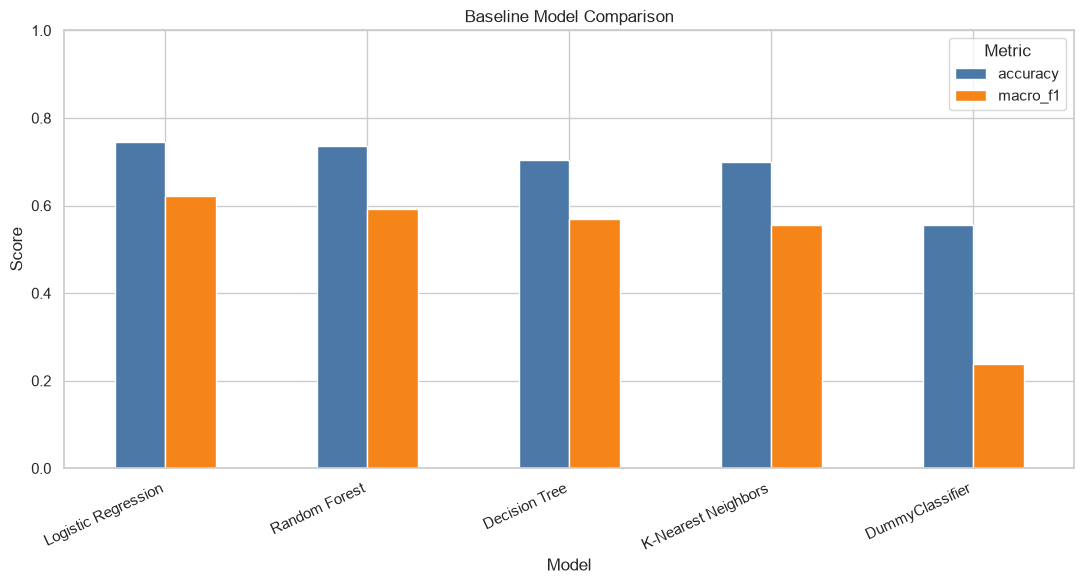

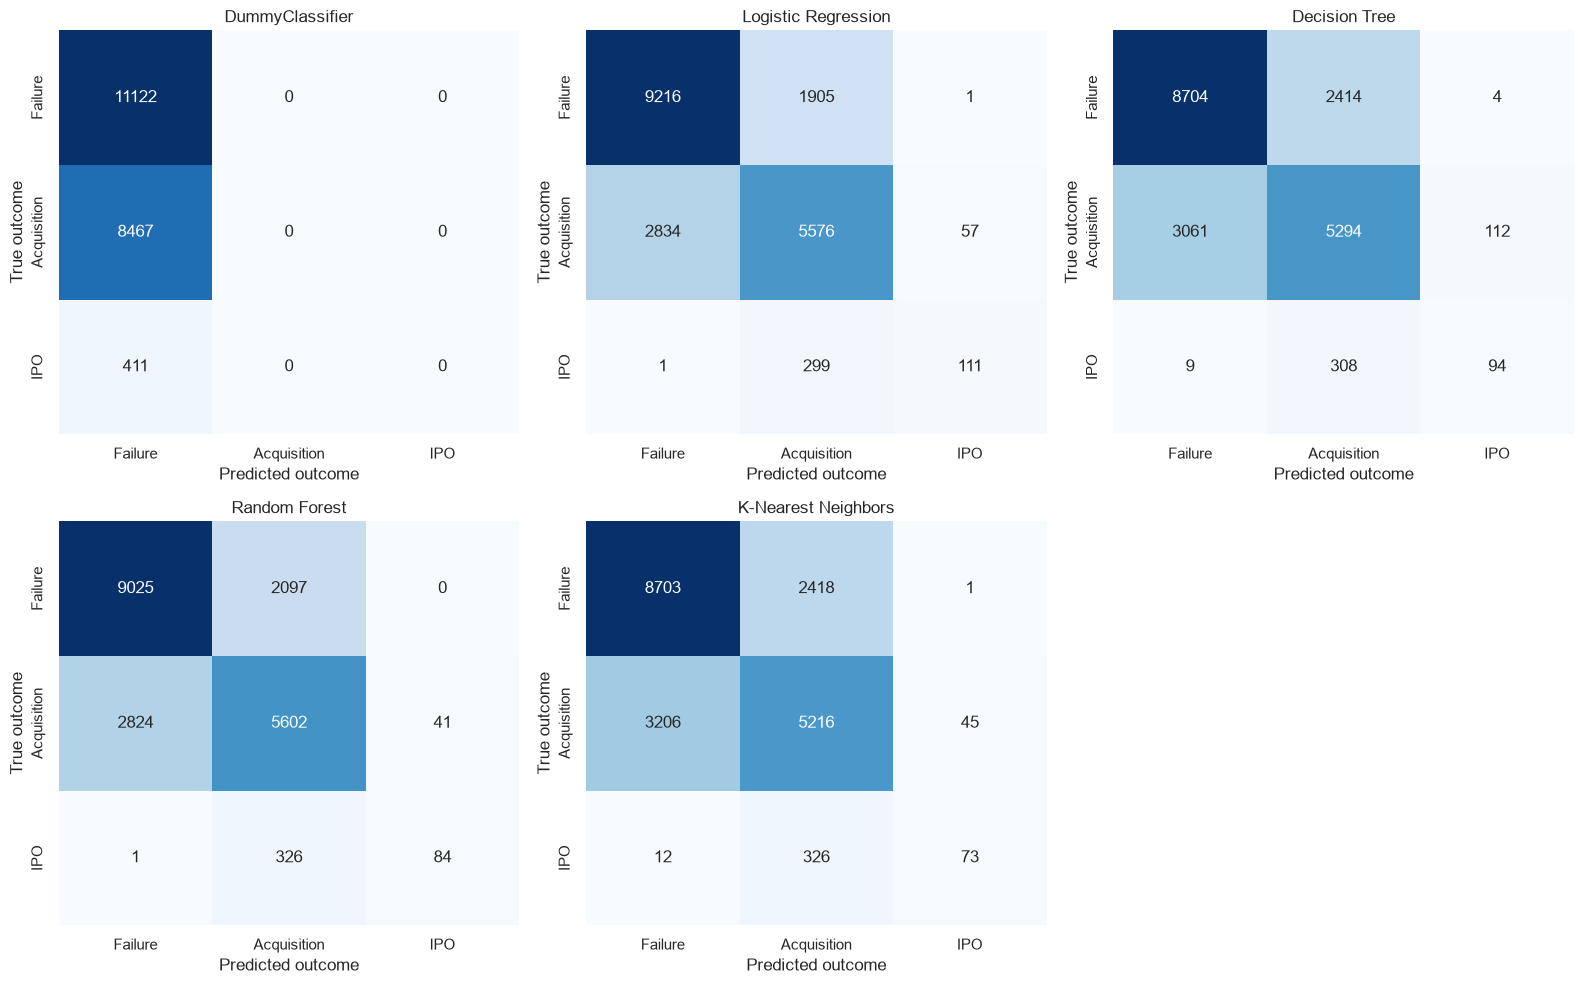

In [47]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_metrics = model_comparison.set_index("model")[["accuracy", "macro_f1"]]
plot_metrics.plot(kind="bar", ax=ax, color=["#4c78a8", "#f58518"])
ax.set_title("Baseline Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Metric")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, model_name in zip(axes.ravel(), baseline_models):
    sns.heatmap(confusion_matrices[model_name], annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis, xticklabels=outcome_order, yticklabels=outcome_order)
    axis.set_title(model_name)
    axis.set_xlabel("Predicted outcome")
    axis.set_ylabel("True outcome")
for axis in axes.ravel()[len(baseline_models):]:
    axis.remove()
plt.tight_layout()
plt.show()

## 6.6 Compare Models

Models are compared primarily by macro F1 and IPO recall, not accuracy alone. The majority baseline indicates how close a model is to predicting only the dominant class. A model that improves accuracy but leaves IPO recall near zero is not adequate for balanced multi-class decision support.

In [48]:
dummy_row = model_comparison.loc[model_comparison["model"] == "DummyClassifier"].iloc[0]
best_macro_f1 = model_comparison.loc[model_comparison["macro_f1"].idxmax()]
best_ipo_recall = model_comparison.loc[model_comparison["ipo_recall"].idxmax()]

print("Best macro F1 model:", best_macro_f1["model"], "with", round(best_macro_f1["macro_f1"], 4))
print("Best IPO recall model:", best_ipo_recall["model"], "with", round(best_ipo_recall["ipo_recall"], 4))
print("Dummy macro F1:", round(dummy_row["macro_f1"], 4))
print("Interpretation: compare each model with DummyClassifier to identify genuine improvement over majority-only predictions. Review IPO recall and the confusion matrices for majority-class favoritism before carrying models forward.")
print("No causal or general-population claim is made; these are baseline held-out test results for this dataset and split.")

Best macro F1 model: Logistic Regression with 0.6215
Best IPO recall model: Logistic Regression with 0.2701
Dummy macro F1: 0.2382
Interpretation: compare each model with DummyClassifier to identify genuine improvement over majority-only predictions. Review IPO recall and the confusion matrices for majority-class favoritism before carrying models forward.
No causal or general-population claim is made; these are baseline held-out test results for this dataset and split.


## 6.7 Document Baseline Findings

The baseline results provide an initial algorithm comparison only. The minority IPO class receives explicit attention through macro metrics, class-level reports, confusion matrices, and IPO recall. No class-balancing method or tuning has been applied, so any weaknesses are baseline observations rather than final model limitations.

In [49]:
model_shortlist = model_comparison[model_comparison["model"] != "DummyClassifier"].sort_values(["macro_f1", "ipo_recall"], ascending=False).head(2)[["model", "macro_f1", "ipo_recall", "accuracy"]]
print("Models provisionally worth carrying into the next evaluation stage, ranked by macro F1 then IPO recall:")
display(model_shortlist.round(4))
print("Baseline conclusion: use macro F1, macro recall, and IPO recall as primary warning signals because the target is imbalanced.")
print("Limitations: no hyperparameter tuning, resampling, feature selection, or threshold adjustment was performed. Results depend on the fixed split and data provenance.")
print("Step 6 complete: baseline models only. No later model comparison/evaluation workflow was added.")

Models provisionally worth carrying into the next evaluation stage, ranked by macro F1 then IPO recall:


,model,macro_f1,ipo_recall,accuracy
0,Logistic Regression,0.6215,0.2701,0.7452
1,Random Forest,0.5928,0.2044,0.7356


Baseline conclusion: use macro F1, macro recall, and IPO recall as primary warning signals because the target is imbalanced.
Limitations: no hyperparameter tuning, resampling, feature selection, or threshold adjustment was performed. Results depend on the fixed split and data provenance.
Step 6 complete: baseline models only. No later model comparison/evaluation workflow was added.


# Step 7 - Model Comparison and Evaluation

This step compares the Step 6 baseline results, investigates the effect of class weighting, evaluates shortlisted configurations with training-only cross-validation, and reports final results on the untouched test set. No new algorithms or extensive tuning are introduced.

## 7.1 Review Existing Model Results

Step 6 trained a DummyClassifier, Logistic Regression, Decision Tree, Random Forest, and K-Nearest Neighbors using the Step 5 processed matrices. The stored baseline table, classification reports, and confusion matrices are reused here; models are not retrained merely to repeat those results. The test partition was already inspected in Step 6, so it is not a virgin final holdout. Training-only cross-validation is used for configuration selection in this step. Logistic Regression was the strongest baseline by macro F1 and IPO recall, while the DummyClassifier predicted only the majority class.

In [50]:
print("Models already trained in Step 6:", list(model_predictions))
print("Step 6 baseline results:")
display(model_comparison.round(4))
print("Target distribution in the untouched test set:")
display(y_test.value_counts().rename("count").to_frame().assign(percentage=lambda table: table["count"] / len(y_test) * 100).round(2))

Models already trained in Step 6: ['DummyClassifier', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'K-Nearest Neighbors']
Step 6 baseline results:


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,ipo_recall
0,Logistic Regression,0.7452,0.7128,0.5858,0.6215,0.7408,0.2701
1,Random Forest,0.7356,0.7106,0.5592,0.5928,0.7310,0.2044
2,Decision Tree,0.7046,0.6158,0.5455,0.5685,0.7010,0.2287
3,K-Nearest Neighbors,0.6996,0.6663,0.5254,0.5553,0.6946,0.1776
4,DummyClassifier,0.5561,0.1854,0.3333,0.2382,0.3975,0.0000


Target distribution in the untouched test set:


,count,percentage
outcome,,
Failure,11122,55.61
Acquisition,8467,42.34
IPO,411,2.05


## 7.2 Compare Model Performance

The consolidated Step 6 table is sorted by macro F1 because macro averaging gives equal weight to Failure, Acquisition, and IPO. Accuracy and weighted F1 are retained for context, but neither is used alone to identify a preferred model.

In [51]:
baseline_comparison = model_comparison[["model", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "ipo_recall"]].copy()
display(baseline_comparison.round(4))
print("The DummyClassifier is the majority-only reference; real models should be judged by improvement in macro metrics and IPO recall as well as accuracy.")

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,ipo_recall
0,Logistic Regression,0.7452,0.7128,0.5858,0.6215,0.7408,0.2701
1,Random Forest,0.7356,0.7106,0.5592,0.5928,0.7310,0.2044
2,Decision Tree,0.7046,0.6158,0.5455,0.5685,0.7010,0.2287
3,K-Nearest Neighbors,0.6996,0.6663,0.5254,0.5553,0.6946,0.1776
4,DummyClassifier,0.5561,0.1854,0.3333,0.2382,0.3975,0.0000


The DummyClassifier is the majority-only reference; real models should be judged by improvement in macro metrics and IPO recall as well as accuracy.


## 7.3 Detailed Classification Evaluation

The Step 6 classification reports are displayed again in a compact class-level table. IPO precision, recall, and F1 are examined explicitly because the class represents only a small fraction of observations.

In [52]:
report_rows = []
for model_name, report in classification_reports.items():
    for class_name in outcome_order:
        report_rows.append({
            "model": model_name,
            "class": class_name,
            "precision": report.loc[class_name, "precision"],
            "recall": report.loc[class_name, "recall"],
            "f1_score": report.loc[class_name, "f1-score"],
            "support": int(report.loc[class_name, "support"])
        })
class_report_summary = pd.DataFrame(report_rows)
display(class_report_summary.round(4))
print("IPO class performance by baseline model:")
display(class_report_summary[class_report_summary["class"] == "IPO"].sort_values("recall", ascending=False).round(4))
print("The DummyClassifier has zero IPO recall; the real models recover some IPO observations but still miss many, mostly as Acquisition.")

,model,class,precision,recall,f1_score,support
0,DummyClassifier,Failure,0.5561,1.0000,0.7147,11122
1,DummyClassifier,Acquisition,0.0000,0.0000,0.0000,8467
2,DummyClassifier,IPO,0.0000,0.0000,0.0000,411
3,Logistic Regression,Failure,0.7647,0.8286,0.7954,11122
4,Logistic Regression,Acquisition,0.7167,0.6586,0.6864,8467
5,Logistic Regression,IPO,0.6568,0.2701,0.3828,411
6,Decision Tree,Failure,0.7393,0.7826,0.7603,11122
7,Decision Tree,Acquisition,0.6604,0.6253,0.6424,8467
8,Decision Tree,IPO,0.4476,0.2287,0.3027,411
9,Random Forest,Failure,0.7616,0.8115,0.7857,11122


IPO class performance by baseline model:


,model,class,precision,recall,f1_score,support
5,Logistic Regression,IPO,0.6568,0.2701,0.3828,411
8,Decision Tree,IPO,0.4476,0.2287,0.3027,411
11,Random Forest,IPO,0.6720,0.2044,0.3134,411
14,K-Nearest Neighbors,IPO,0.6134,0.1776,0.2755,411
2,DummyClassifier,IPO,0.0000,0.0000,0.0000,411


The DummyClassifier has zero IPO recall; the real models recover some IPO observations but still miss many, mostly as Acquisition.


## 7.4 Confusion Matrix Analysis

The Step 6 confusion matrices are visualized with a shared class order. The analysis focuses on Failure?Acquisition confusion and the destinations of true IPO observations, not just the diagonal counts.

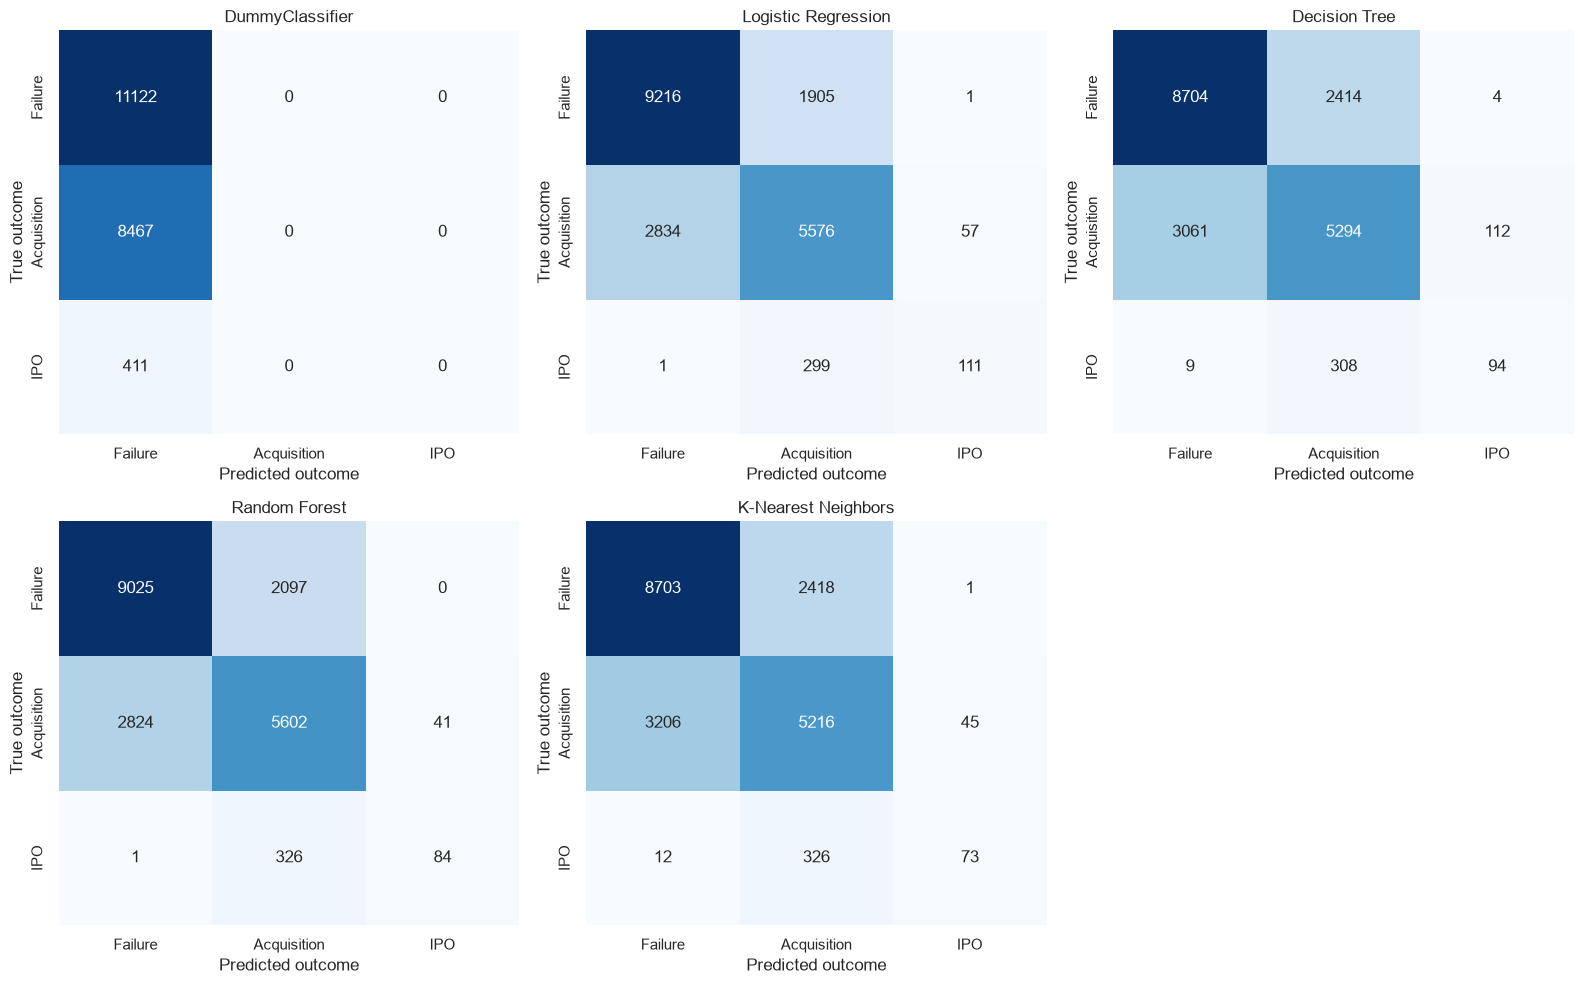

DummyClassifier: true IPO predictions -> {'Failure': 411, 'Acquisition': 0, 'IPO': 0}; true Failure/Acquisition cross-confusion = 8,467.
Logistic Regression: true IPO predictions -> {'Failure': 1, 'Acquisition': 299, 'IPO': 111}; true Failure/Acquisition cross-confusion = 4,739.
Decision Tree: true IPO predictions -> {'Failure': 9, 'Acquisition': 308, 'IPO': 94}; true Failure/Acquisition cross-confusion = 5,475.
Random Forest: true IPO predictions -> {'Failure': 1, 'Acquisition': 326, 'IPO': 84}; true Failure/Acquisition cross-confusion = 4,921.
K-Nearest Neighbors: true IPO predictions -> {'Failure': 12, 'Acquisition': 326, 'IPO': 73}; true Failure/Acquisition cross-confusion = 5,624.
The confusion matrices show that baseline models distinguish Failure and Acquisition imperfectly and frequently assign true IPO cases to Acquisition. This is the central minority-class limitation.


In [53]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, model_name in zip(axes.ravel(), baseline_models):
    sns.heatmap(confusion_matrices[model_name], annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis, xticklabels=outcome_order, yticklabels=outcome_order)
    axis.set_title(model_name)
    axis.set_xlabel("Predicted outcome")
    axis.set_ylabel("True outcome")
for axis in axes.ravel()[len(baseline_models):]:
    axis.remove()
plt.tight_layout()
plt.show()

for model_name, matrix in confusion_matrices.items():
    ipo_row = pd.Series(matrix[outcome_order.index("IPO")], index=outcome_order)
    print(f"{model_name}: true IPO predictions -> {ipo_row.to_dict()}; true Failure/Acquisition cross-confusion = {matrix[0, 1] + matrix[1, 0]:,}.")
print("The confusion matrices show that baseline models distinguish Failure and Acquisition imperfectly and frequently assign true IPO cases to Acquisition. This is the central minority-class limitation.")

## 7.5 Investigate Class Imbalance

Class weighting is evaluated for models that support `class_weight`: Logistic Regression and Random Forest. The balanced setting changes training loss emphasis only; the original training rows and untouched test distribution are preserved. Random oversampling is not run because `imbalanced-learn` is not installed and adding a dependency is unnecessary for this limited baseline comparison; it can be considered later in a dedicated resampling study.

In [54]:
from sklearn.base import clone

weighted_models = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, solver="lbfgs", class_weight="balanced"),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight="balanced")
}
weighted_predictions = {}
weighted_rows = []
for model_name, model in weighted_models.items():
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    weighted_predictions[model_name] = predictions
    weighted_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, predictions),
        "macro_precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "ipo_precision": precision_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0],
        "ipo_recall": recall_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0],
        "ipo_f1": f1_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0]
    })
weighted_comparison = pd.DataFrame(weighted_rows)
original_for_balance = baseline_comparison.copy()
original_for_balance["configuration"] = "original"
original_for_balance["ipo_precision"] = [classification_reports[row["model"]].loc["IPO", "precision"] for _, row in original_for_balance.iterrows()]
original_for_balance["ipo_f1"] = [classification_reports[row["model"]].loc["IPO", "f1-score"] for _, row in original_for_balance.iterrows()]
balanced_display = weighted_comparison.copy()
print("Class-weighted configurations:")
display(balanced_display.round(4))
print("The test distribution is unchanged:")
display(y_test.value_counts().rename("count").to_frame())
print("Random oversampling was not executed because imbalanced-learn is unavailable; no test rows were resampled.")

Class-weighted configurations:


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,ipo_precision,ipo_recall,ipo_f1
0,Logistic Regression (balanced),0.6850,0.5429,0.7203,0.5624,0.6974,0.1830,0.8248,0.2996
1,Random Forest (balanced),0.7301,0.6615,0.5864,0.6120,0.7290,0.5312,0.2895,0.3748


The test distribution is unchanged:


,count
outcome,
Failure,11122
Acquisition,8467
IPO,411


Random oversampling was not executed because imbalanced-learn is unavailable; no test rows were resampled.


## 7.6 Cross-Validation

Shortlisted configurations are evaluated with 5-fold `StratifiedKFold` on the training partition only. Each fold fits a fresh clone of the Step 5 preprocessing transformer before fitting its classifier, preventing preprocessing leakage. The cross-validation comparison is limited to Logistic Regression and Random Forest with original and balanced class weighting; the other Step 6 models remain in the baseline comparison.

In [55]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_configurations = {
    "Logistic Regression (original)": LogisticRegression(max_iter=1000, solver="lbfgs"),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, solver="lbfgs", class_weight="balanced"),
    "Random Forest (original)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight="balanced")
}

cv_rows = []
for configuration, estimator in cv_configurations.items():
    cv_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessing_pipeline.named_steps["preprocessor"])),
        ("model", estimator)
    ])
    scores = cross_validate(
        cv_pipeline, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        return_train_score=False, n_jobs=1
    )
    cv_rows.append({
        "configuration": configuration,
        "mean_accuracy": scores["test_accuracy"].mean(),
        "std_accuracy": scores["test_accuracy"].std(),
        "mean_macro_f1": scores["test_macro_f1"].mean(),
        "std_macro_f1": scores["test_macro_f1"].std()
    })
cv_results = pd.DataFrame(cv_rows).sort_values("mean_macro_f1", ascending=False).reset_index(drop=True)
display(cv_results.round(4))
print("Cross-validation used training data only; the untouched test partition was not used for configuration selection.")

,configuration,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1
0,Logistic Regression (original),0.7426,0.0036,0.6070,0.0084
1,Random Forest (balanced),0.7312,0.0029,0.6005,0.0107
2,Random Forest (original),0.7338,0.0028,0.5748,0.0116
3,Logistic Regression (balanced),0.6835,0.0015,0.5626,0.0035


Cross-validation used training data only; the untouched test partition was not used for configuration selection.


## 7.7 Final Model Comparison

The strongest configurations are selected from training-only cross-validation by macro F1, with stability considered through the standard deviation. Only after that selection are the selected configurations fitted on all training data and evaluated on the held-out test partition. Because the same test partition was already reported in Step 6 and used for Step 7 diagnostic comparisons, these results should not be described as an untouched or fully independent final estimate. The Step 6 baseline rows are retained for comparison.

In [56]:
best_configurations = cv_results.head(2)["configuration"].tolist()
final_estimators = {configuration: clone(cv_configurations[configuration]) for configuration in best_configurations}
final_predictions = {}
final_rows = []
for configuration, estimator in final_estimators.items():
    estimator.fit(X_train_processed, y_train)
    predictions = estimator.predict(X_test_processed)
    final_predictions[configuration] = predictions
    final_rows.append({
        "model": configuration,
        "configuration": "class_weight=balanced" if "balanced" in configuration else "original class weights",
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "ipo_precision": precision_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0],
        "ipo_recall": recall_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0],
        "ipo_f1": f1_score(y_test, predictions, labels=["IPO"], average=None, zero_division=0)[0]
    })

baseline_final_rows = []
for _, row in model_comparison.iterrows():
    report = classification_reports[row["model"]]
    baseline_final_rows.append({
        "model": row["model"], "configuration": "Step 6 baseline",
        "accuracy": row["accuracy"], "macro_f1": row["macro_f1"], "weighted_f1": row["weighted_f1"],
        "ipo_precision": report.loc["IPO", "precision"], "ipo_recall": report.loc["IPO", "recall"], "ipo_f1": report.loc["IPO", "f1-score"]
    })
final_model_comparison = pd.DataFrame(baseline_final_rows + final_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(final_model_comparison.round(4))
print("Selected configurations based on training-only CV:", best_configurations)
print("The final rows above report the selected configurations on the held-out test partition. No further configuration selection is made from these results, but the partition had already been inspected earlier and is therefore not a virgin final estimate.")

,model,configuration,accuracy,macro_f1,weighted_f1,ipo_precision,ipo_recall,ipo_f1
0,Logistic Regression,Step 6 baseline,0.7452,0.6215,0.7408,0.6568,0.2701,0.3828
1,Logistic Regression (original),original class weights,0.7452,0.6215,0.7408,0.6568,0.2701,0.3828
2,Random Forest (balanced),class_weight=balanced,0.7301,0.6120,0.7290,0.5312,0.2895,0.3748
3,Random Forest,Step 6 baseline,0.7356,0.5928,0.7310,0.6720,0.2044,0.3134
4,Decision Tree,Step 6 baseline,0.7046,0.5685,0.7010,0.4476,0.2287,0.3027
5,K-Nearest Neighbors,Step 6 baseline,0.6996,0.5553,0.6946,0.6134,0.1776,0.2755
6,DummyClassifier,Step 6 baseline,0.5561,0.2382,0.3975,0.0000,0.0000,0.0000


Selected configurations based on training-only CV: ['Logistic Regression (original)', 'Random Forest (balanced)']
The final rows above report the selected configurations on the held-out test partition. No further configuration selection is made from these results, but the partition had already been inspected earlier and is therefore not a virgin final estimate.


## 7.8 Select Candidate Models

One or two candidates are shortlisted using macro F1, IPO-class performance, cross-validation stability, complexity, and interpretability. This is a dataset-specific shortlist, not a claim that one algorithm is universally best.

In [57]:
selected_candidates = cv_results.head(2).merge(
    final_model_comparison[["model", "accuracy", "macro_f1", "weighted_f1", "ipo_precision", "ipo_recall", "ipo_f1"]],
    left_on="configuration", right_on="model", how="left"
)
display(selected_candidates.round(4))
print("Selection rationale: candidates were chosen from training-only CV using macro F1 and stability, then checked for IPO recall and interpretability on the final untouched-test report.")
print("Potential majority-class favoritism remains if IPO recall is materially below Failure/Acquisition recall; class weighting should be carried forward only when its IPO benefit justifies any precision trade-off.")

,configuration,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1,model,accuracy,macro_f1,weighted_f1,ipo_precision,ipo_recall,ipo_f1
0,Logistic Regression (original),0.7426,0.0036,0.6070,0.0084,Logistic Regression (original),0.7452,0.6215,0.7408,0.6568,0.2701,0.3828
1,Random Forest (balanced),0.7312,0.0029,0.6005,0.0107,Random Forest (balanced),0.7301,0.6120,0.7290,0.5312,0.2895,0.3748


Selection rationale: candidates were chosen from training-only CV using macro F1 and stability, then checked for IPO recall and interpretability on the final untouched-test report.
Potential majority-class favoritism remains if IPO recall is materially below Failure/Acquisition recall; class weighting should be carried forward only when its IPO benefit justifies any precision trade-off.


## 7.9 Document Findings

This final Step 7 summary distinguishes baseline observations from class-weighting effects and cross-validation evidence. It does not tune models, claim causality, or begin model interpretation.

In [58]:
print("Baseline versus improved configurations:")
display(final_model_comparison.round(4))
print("Important observations:")
print("- The DummyClassifier establishes the majority-only reference and has no useful IPO recall.")
print("- Compare class-weighted configurations using macro F1 and IPO precision/recall, not IPO recall alone.")
print("- Cross-validation variability indicates how consistently shortlisted configurations perform across training folds.")
print("- The small IPO class and fixed dataset split limit how confidently these results generalize.")
print("- No test-set result was used to change a configuration after final selection.")
print("Step 7 complete: model comparison and evaluation only. Step 8 model interpretation has not been started.")

Baseline versus improved configurations:


,model,configuration,accuracy,macro_f1,weighted_f1,ipo_precision,ipo_recall,ipo_f1
0,Logistic Regression,Step 6 baseline,0.7452,0.6215,0.7408,0.6568,0.2701,0.3828
1,Logistic Regression (original),original class weights,0.7452,0.6215,0.7408,0.6568,0.2701,0.3828
2,Random Forest (balanced),class_weight=balanced,0.7301,0.6120,0.7290,0.5312,0.2895,0.3748
3,Random Forest,Step 6 baseline,0.7356,0.5928,0.7310,0.6720,0.2044,0.3134
4,Decision Tree,Step 6 baseline,0.7046,0.5685,0.7010,0.4476,0.2287,0.3027
5,K-Nearest Neighbors,Step 6 baseline,0.6996,0.5553,0.6946,0.6134,0.1776,0.2755
6,DummyClassifier,Step 6 baseline,0.5561,0.2382,0.3975,0.0000,0.0000,0.0000


Important observations:
- The DummyClassifier establishes the majority-only reference and has no useful IPO recall.
- Compare class-weighted configurations using macro F1 and IPO precision/recall, not IPO recall alone.
- Cross-validation variability indicates how consistently shortlisted configurations perform across training folds.
- The small IPO class and fixed dataset split limit how confidently these results generalize.
- No test-set result was used to change a configuration after final selection.
Step 7 complete: model comparison and evaluation only. Step 8 model interpretation has not been started.


### Evaluation protocol limitation

The stratified test partition was evaluated in Step 6, used for Step 7 diagnostic comparisons, and used for Step 8 permutation importance. Step 7 configuration selection itself used training-only 5-fold cross-validation, which is the preferred selection evidence. However, the later test metrics and permutation results should not be presented as a fresh, fully independent final estimate. A future revision should reserve a final holdout from the beginning or use nested evaluation.

# Step 8 - Model Interpretation

This step interprets the selected configuration from Step 7 without changing it or tuning it. The analysis uses model-supported coefficients, permutation importance, and carefully selected individual test predictions. Importance indicates predictive contribution, not causation.

## 8.1 Review the Selected Model

The selected configuration is the highest-ranked configuration by training-only 5-fold cross-validated macro F1 from Step 7. The untouched test set is used only for the interpretation analyses and the already planned final reporting; it is not used to select or change the model.

In [59]:
selected_model_configuration = cv_results.iloc[0]["configuration"]
selected_model_estimator = clone(cv_configurations[selected_model_configuration])
selected_model_estimator.fit(X_train_processed, y_train)
selected_model_predictions = selected_model_estimator.predict(X_test_processed)
selected_model_probabilities = selected_model_estimator.predict_proba(X_test_processed)

print("Selected configuration:", selected_model_configuration)
print("Selected estimator:", selected_model_estimator)
print("Predictor count:", len(final_predictor_features))
print("Target excluded from predictors:", "outcome" not in final_predictor_features)
print("Final predictor variables:", final_predictor_features)
print("Selected test macro F1:", round(f1_score(y_test, selected_model_predictions, average="macro"), 4))

Selected configuration: Logistic Regression (original)
Selected estimator: LogisticRegression(max_iter=1000)
Predictor count: 13
Target excluded from predictors: True
Final predictor variables: ['revenue_to_burn_ratio', 'traction_per_employee', 'funding_rounds_per_founder_experience', 'funding_rounds', 'founder_experience_years', 'team_size', 'market_size_billion', 'product_traction_users', 'burn_rate_million', 'revenue_million', 'investor_type', 'sector', 'founder_background']
Selected test macro F1: 0.6215


## 8.2 Feature Importance Analysis

The selected configuration is Logistic Regression in the current Step 7 results, so its coefficients are used for class-specific interpretation. A positive coefficient increases the model's linear score for a class as the processed feature increases; a negative coefficient decreases that score, holding the other processed features constant. One-hot encoded categories are interpreted as category-specific indicators, while numerical values are standardized by the Step 5 pipeline.

Ranked global coefficient magnitude (largest class-specific absolute coefficient):


,processed_feature,Acquisition,Failure,IPO,maximum_absolute_coefficient,most_influential_class
0,numerical__revenue_million,-0.0498,-1.0445,1.0943,1.0943,IPO
1,numerical__funding_rounds,-0.0170,-0.7287,0.7457,0.7457,IPO
2,numerical__founder_experience_years,-0.0327,-0.6339,0.6666,0.6666,IPO
3,categorical__investor_type_none,0.3086,0.3415,-0.6501,0.6501,IPO
4,categorical__investor_type_tier1_vc,0.3041,0.3379,-0.6420,0.6420,IPO
5,categorical__founder_background_first_time,0.2945,0.3208,-0.6153,0.6153,IPO
6,numerical__product_traction_users,-0.0330,-0.5816,0.6145,0.6145,IPO
7,categorical__founder_background_academic,0.2718,0.3284,-0.6002,0.6002,IPO
8,categorical__founder_background_ex_bigtech,0.2731,0.3243,-0.5974,0.5974,IPO
9,categorical__investor_type_tier2_vc,0.2741,0.3105,-0.5846,0.5846,IPO


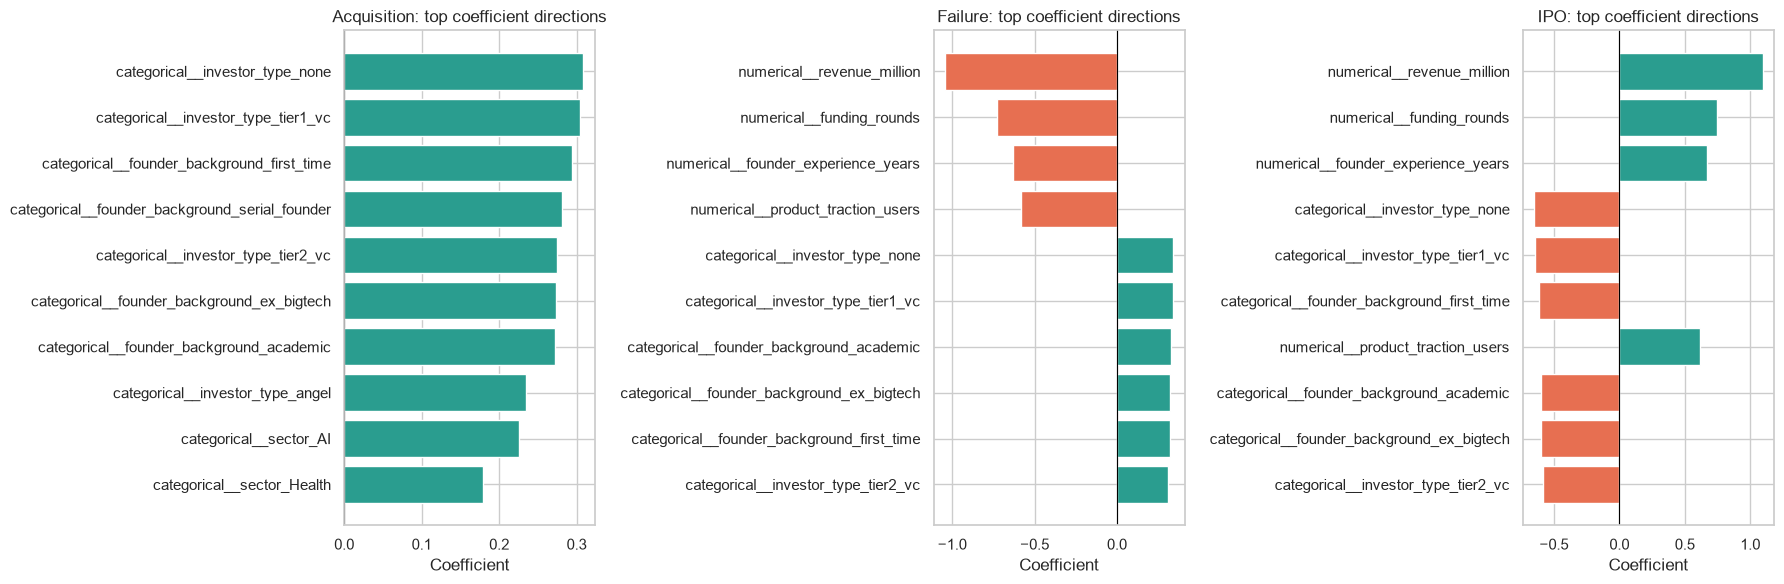

Acquisition: positive contributors


,coefficient
categorical__investor_type_none,0.3086
categorical__investor_type_tier1_vc,0.3041
categorical__founder_background_first_time,0.2945
categorical__founder_background_serial_founder,0.2816
categorical__investor_type_tier2_vc,0.2741


Acquisition: negative contributors


,coefficient
numerical__revenue_million,-0.0498
numerical__product_traction_users,-0.0330
numerical__founder_experience_years,-0.0327
numerical__funding_rounds_per_founder_experience,-0.0183
numerical__team_size,-0.0182


Failure: positive contributors


,coefficient
categorical__investor_type_none,0.3415
categorical__investor_type_tier1_vc,0.3379
categorical__founder_background_academic,0.3284
categorical__founder_background_ex_bigtech,0.3243
categorical__founder_background_first_time,0.3208


... (2 outputs left out)

IPO: positive contributors


,coefficient
numerical__revenue_million,1.0943
numerical__funding_rounds,0.7457
numerical__founder_experience_years,0.6666
numerical__product_traction_users,0.6145
numerical__team_size,0.3207


IPO: negative contributors


,coefficient
categorical__investor_type_none,-0.6501
categorical__investor_type_tier1_vc,-0.6420
categorical__founder_background_first_time,-0.6153
categorical__founder_background_academic,-0.6002
categorical__founder_background_ex_bigtech,-0.5974


In [60]:
selected_feature_names = list(preprocessing_pipeline.named_steps["preprocessor"].get_feature_names_out())
coefficient_matrix = pd.DataFrame(
    selected_model_estimator.coef_,
    index=selected_model_estimator.classes_,
    columns=selected_feature_names
)

coefficient_long = coefficient_matrix.T.reset_index().rename(columns={"index": "processed_feature"})
coefficient_long["maximum_absolute_coefficient"] = coefficient_matrix.abs().max(axis=0).values
coefficient_long["most_influential_class"] = coefficient_matrix.abs().idxmax(axis=0).values
ranked_coefficient_importance = coefficient_long.sort_values("maximum_absolute_coefficient", ascending=False).reset_index(drop=True)
print("Ranked global coefficient magnitude (largest class-specific absolute coefficient):")
display(ranked_coefficient_importance.head(15).round(4))

fig, axes = plt.subplots(1, len(selected_model_estimator.classes_), figsize=(18, 6), sharex=False)
for axis, class_name in zip(np.ravel(axes), selected_model_estimator.classes_):
    class_coefficients = coefficient_matrix.loc[class_name].sort_values(key=lambda values: values.abs()).tail(10)
    colors = ["#2a9d8f" if value > 0 else "#e76f51" for value in class_coefficients]
    axis.barh(class_coefficients.index, class_coefficients.values, color=colors)
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_title(f"{class_name}: top coefficient directions")
    axis.set_xlabel("Coefficient")
plt.tight_layout()
plt.show()

for class_name in selected_model_estimator.classes_:
    class_coefficients = coefficient_matrix.loc[class_name].sort_values(ascending=False)
    print(f"{class_name}: positive contributors")
    display(class_coefficients.head(5).rename("coefficient").to_frame().round(4))
    print(f"{class_name}: negative contributors")
    display(class_coefficients.tail(5).sort_values().rename("coefficient").to_frame().round(4))

## 8.3 Permutation Feature Importance

Permutation importance measures the decrease in macro F1 when one original predictor column is shuffled in the held-out test set. This is an interpretation diagnostic, not an independent performance estimate; the partition had already been used for earlier evaluation. A large decrease means the fitted pipeline relied on that predictor for predictive performance in this sample. The pipeline is passed the unprocessed test dataframe so importance is reported at the original predictor level rather than separately for every one-hot encoded column.

,feature,mean_macro_f1_decrease,std_macro_f1_decrease
0,revenue_million,0.1883,0.0036
1,product_traction_users,0.0999,0.0078
2,funding_rounds,0.0649,0.0031
3,founder_experience_years,0.0431,0.0049
4,team_size,0.0160,0.0038
5,funding_rounds_per_founder_experience,0.0027,0.0018
6,founder_background,0.0011,0.0009
7,burn_rate_million,0.0009,0.0004
8,investor_type,0.0007,0.0015
9,sector,0.0003,0.0008


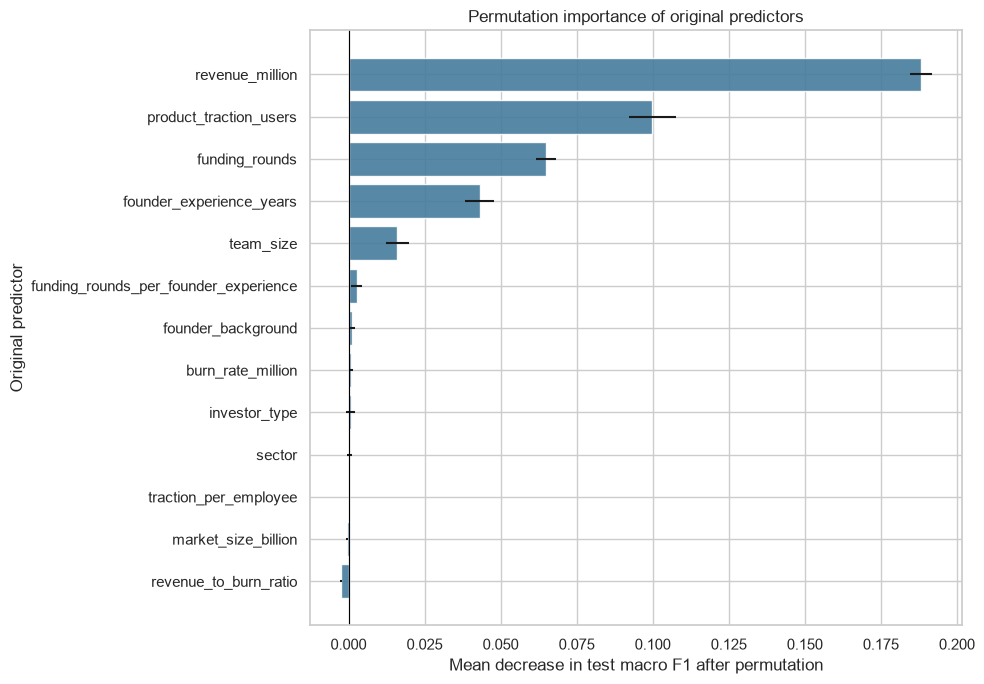

Permutation importance is predictive evidence for this fitted model and test sample; correlated predictors may share importance or mask one another.


In [61]:
from sklearn.inspection import permutation_importance

selected_interpretation_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessing_pipeline.named_steps["preprocessor"])),
    ("model", clone(selected_model_estimator))
])
selected_interpretation_pipeline.fit(X_train, y_train)
permutation_results = permutation_importance(
    selected_interpretation_pipeline,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)
permutation_importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "mean_macro_f1_decrease": permutation_results.importances_mean,
    "std_macro_f1_decrease": permutation_results.importances_std
}).sort_values("mean_macro_f1_decrease", ascending=False).reset_index(drop=True)
display(permutation_importance_table.round(4))

plot_data = permutation_importance_table.head(15).sort_values("mean_macro_f1_decrease")
plt.figure(figsize=(10, 7))
plt.barh(plot_data["feature"], plot_data["mean_macro_f1_decrease"], xerr=plot_data["std_macro_f1_decrease"], color="#457b9d", alpha=0.9)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Mean decrease in test macro F1 after permutation")
plt.ylabel("Original predictor")
plt.title("Permutation importance of original predictors")
plt.tight_layout()
plt.show()
print("Permutation importance is predictive evidence for this fitted model and test sample; correlated predictors may share importance or mask one another.")

## 8.4 Interpret Predictions Across Classes

Global importance does not mean that every class uses a feature in the same way. The coefficient table below reports the strongest positive and negative directions separately for Failure, Acquisition, and IPO. These directions describe the classifier's learned associations, not causal effects.

In [62]:
class_specific_rows = []
for class_name in selected_model_estimator.classes_:
    class_coefficients = coefficient_matrix.loc[class_name]
    for feature_name in class_coefficients.abs().sort_values(ascending=False).head(10).index:
        class_specific_rows.append({
            "class": class_name,
            "processed_feature": feature_name,
            "coefficient": class_coefficients[feature_name],
            "direction": "positive" if class_coefficients[feature_name] > 0 else "negative"
        })
class_specific_importance = pd.DataFrame(class_specific_rows)
display(class_specific_importance.round(4))
print("IPO has its own coefficient pattern, but its small support means its recall remains the most difficult aspect of interpretation and prediction. A coefficient direction should not be read as a guarantee for an individual startup.")

,class,processed_feature,coefficient,direction
0,Acquisition,categorical__investor_type_none,0.3086,positive
1,Acquisition,categorical__investor_type_tier1_vc,0.3041,positive
2,Acquisition,categorical__founder_background_first_time,0.2945,positive
3,Acquisition,categorical__founder_background_serial_founder,0.2816,positive
4,Acquisition,categorical__investor_type_tier2_vc,0.2741,positive
5,Acquisition,categorical__founder_background_ex_bigtech,0.2731,positive
6,Acquisition,categorical__founder_background_academic,0.2718,positive
7,Acquisition,categorical__investor_type_angel,0.2342,positive
8,Acquisition,categorical__sector_AI,0.2255,positive
9,Acquisition,categorical__sector_Health,0.1785,positive


IPO has its own coefficient pattern, but its small support means its recall remains the most difficult aspect of interpretation and prediction. A coefficient direction should not be read as a guarantee for an individual startup.


## 8.5 Analyse Individual Predictions

Representative examples are selected deterministically from the untouched test predictions: one correct example for each class when available, followed by up to three incorrect examples. Probabilities are shown when supported by Logistic Regression. The explanations use the selected model's class coefficients and only describe model evidence.

In [63]:
prediction_frame = X_test.copy()
prediction_frame["actual_outcome"] = y_test.to_numpy()
prediction_frame["predicted_outcome"] = selected_model_predictions
for class_name, probabilities in zip(selected_model_estimator.classes_, selected_model_probabilities.T):
    prediction_frame[f"probability_{class_name}"] = probabilities
prediction_frame["test_position"] = np.arange(len(prediction_frame))

representative_positions = []
for class_name in outcome_order:
    matches = prediction_frame.index[(prediction_frame["actual_outcome"] == class_name) & (prediction_frame["predicted_outcome"] == class_name)]
    if len(matches) > 0:
        representative_positions.append(matches[0])
incorrect_matches = prediction_frame.index[prediction_frame["actual_outcome"] != prediction_frame["predicted_outcome"]]
representative_positions.extend(list(incorrect_matches[:3]))
representative_positions = list(dict.fromkeys(representative_positions))

representative_predictions = prediction_frame.loc[representative_positions].copy()
probability_columns = [f"probability_{class_name}" for class_name in selected_model_estimator.classes_]
display(representative_predictions[["actual_outcome", "predicted_outcome"] + probability_columns + final_predictor_features].round(4))

for row_index in representative_positions:
    row = prediction_frame.loc[row_index]
    predicted_class = row["predicted_outcome"]
    top_directions = coefficient_matrix.loc[predicted_class].abs().sort_values(ascending=False).head(3).index.tolist()
    print(f"Test position {int(row['test_position'])}: actual={row['actual_outcome']}, predicted={predicted_class}; strongest learned coefficient directions for the predicted class: {top_directions}.")
print("These examples show model outputs and learned evidence only; they do not establish why a startup achieved its observed outcome.")

,actual_outcome,predicted_outcome,probability_Acquisition,probability_Failure,probability_IPO,revenue_to_burn_ratio,traction_per_employee,funding_rounds_per_founder_experience,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background
9017,Failure,Failure,0.3394,0.6598,0.0008,104890.1934,1556.0707,0.7500,3,4,198,10.9362,308102,4.8029,5.037752e+05,angel,Ecommerce,first_time
32883,Acquisition,Acquisition,0.8661,0.0792,0.0548,377693.4905,1422.3333,0.0455,1,22,285,10.0870,405365,4.4422,1.677772e+06,tier1_vc,Climate,academic
32692,IPO,IPO,0.3826,0.0021,0.6153,244012.0163,18358.9231,0.0000,0,22,39,43.9765,715998,14.4157,3.517595e+06,none,SaaS,first_time
16470,Acquisition,Failure,0.4669,0.5314,0.0018,154444.9160,1226.3658,0.1000,1,10,298,25.8346,365457,5.1728,7.989148e+05,tier2_vc,Climate,serial_founder
49100,Acquisition,Failure,0.3810,0.6180,0.0010,24630.5768,4650.3488,0.1111,2,18,86,20.1977,399930,9.4869,2.336683e+05,tier2_vc,Ecommerce,serial_founder
28759,Acquisition,Failure,0.2828,0.7168,0.0004,8976.8398,6729.0667,0.2222,4,18,15,33.7641,100936,14.7962,1.328227e+05,tier2_vc,Climate,academic


Test position 0: actual=Failure, predicted=Failure; strongest learned coefficient directions for the predicted class: ['numerical__revenue_million', 'numerical__funding_rounds', 'numerical__founder_experience_years'].
Test position 1: actual=Acquisition, predicted=Acquisition; strongest learned coefficient directions for the predicted class: ['categorical__investor_type_none', 'categorical__investor_type_tier1_vc', 'categorical__founder_background_first_time'].
Test position 236: actual=IPO, predicted=IPO; strongest learned coefficient directions for the predicted class: ['numerical__revenue_million', 'numerical__funding_rounds', 'numerical__founder_experience_years'].
Test position 4: actual=Acquisition, predicted=Failure; strongest learned coefficient directions for the predicted class: ['numerical__revenue_million', 'numerical__funding_rounds', 'numerical__founder_experience_years'].
Test position 6: actual=Acquisition, predicted=Failure; strongest learned coefficient directions for

## 8.6 Investigate Important Feature Relationships

The interpretation is compared with earlier EDA and statistical analysis. Earlier results found significant numerical outcome relationships for funding rounds, founder experience, team size, product traction, and revenue after correction, while market size and burn rate were not significant. The model may still use combinations of features, and statistical association is not the same as predictive importance.

In [64]:
statistically_associated_features = {"funding_rounds", "founder_experience_years", "team_size", "product_traction_users", "revenue_million"}
permutation_top_features = set(permutation_importance_table.head(10)["feature"])
comparison_rows = []
for feature_name in final_predictor_features:
    comparison_rows.append({
        "feature": feature_name,
        "permutation_rank": int(permutation_importance_table.index[permutation_importance_table["feature"] == feature_name][0] + 1),
        "permutation_mean_decrease": permutation_importance_table.loc[permutation_importance_table["feature"] == feature_name, "mean_macro_f1_decrease"].iloc[0],
        "identified_as_statistically_associated_in_step_3": feature_name in statistically_associated_features,
        "interpretation_note": "engineered or categorical feature; compare cautiously" if feature_name not in numerical_features else "original numerical feature"
    })
eda_statistical_comparison = pd.DataFrame(comparison_rows).sort_values("permutation_rank")
display(eda_statistical_comparison.round(4))
print("The comparison is descriptive: agreement with Step 3 supports consistency, while disagreement can occur because prediction uses multivariable combinations and Step 3 tests different hypotheses.")
print("Engineered ratios can share information with their numerator and denominator, so their importance should not be interpreted independently of those related predictors.")

,feature,permutation_rank,permutation_mean_decrease,identified_as_statistically_associated_in_step_3,interpretation_note
9,revenue_million,1,0.1883,True,original numerical feature
7,product_traction_users,2,0.0999,True,original numerical feature
3,funding_rounds,3,0.0649,True,original numerical feature
4,founder_experience_years,4,0.0431,True,original numerical feature
5,team_size,5,0.0160,True,original numerical feature
2,funding_rounds_per_founder_experience,6,0.0027,False,engineered or categorical feature; compare cau...
12,founder_background,7,0.0011,False,engineered or categorical feature; compare cau...
8,burn_rate_million,8,0.0009,False,original numerical feature
10,investor_type,9,0.0007,False,engineered or categorical feature; compare cau...
11,sector,10,0.0003,False,engineered or categorical feature; compare cau...


The comparison is descriptive: agreement with Step 3 supports consistency, while disagreement can occur because prediction uses multivariable combinations and Step 3 tests different hypotheses.
Engineered ratios can share information with their numerator and denominator, so their importance should not be interpreted independently of those related predictors.


## 8.7 Document Interpretation Findings

### Key observations

- The selected model is the highest training-only cross-validation macro-F1 configuration from Step 7; no test-set interpretation result changed that selection.
- Coefficients provide class-specific directions, while permutation importance ranks original predictors by their effect on test macro F1 when shuffled.
- Agreement between important predictors and Step 3 associations is supportive evidence of consistency, not proof of causation.
- IPO remains difficult to interpret and predict because it is the minority class; coefficient magnitude alone does not guarantee reliable IPO predictions.

### Limitations

- Correlated predictors can split, duplicate, or mask importance.
- One-hot encoded categories are represented as separate coefficient terms.
- Permutation importance is sample-dependent and was calculated on the previously used held-out test set for interpretation only; it should not be treated as an independent validation result.
- Logistic Regression is a linear model in the transformed feature space, so nonlinear relationships may not be represented fully.
- Individual explanations describe model evidence, not causal explanations of startup outcomes.

Step 8 is complete. Step 9 - Final Findings and Documentation has not been started.

# Step 9 - Final Findings and Documentation

This final step consolidates the completed analysis from Steps 1?8. It does not introduce new models, tuning, or analytical experiments. Reported values are taken from the executed notebook objects and persisted outputs.

## 9.1 Review of the Completed Project

The project assessed data quality, explored distributions and outcome differences, tested statistical associations, engineered interpretable ratios, built leakage-resistant preprocessing, evaluated baseline and class-weighted classifiers, and interpreted the selected model. The raw CSV remains unchanged and `outcome` was kept separate from all predictors.

In [65]:
project_review = pd.DataFrame({
    "stage": [
        "Data quality", "EDA", "Statistical analysis", "Feature engineering",
        "Preprocessing", "Baseline models", "Model comparison", "Model interpretation"
    ],
    "completed_work": [
        "Missingness, duplicates, types, outliers, validity, categories, leakage",
        "Target balance, distributions, outcome comparisons, categories, correlation, multivariate sample",
        "Kruskal-Wallis, Holm-adjusted post-hoc tests, chi-square, Cramer's V, bootstrap context",
        "Three safe ratios retained; arbitrary bins and target encoding rejected",
        "Stratified 80:20 split; training-fitted imputation, scaling, and one-hot encoding",
        "Dummy, Logistic Regression, Decision Tree, Random Forest, and KNN",
        "Class weighting, training-only 5-fold CV, final untouched-test comparison",
        "Class-specific coefficients, permutation importance, and representative predictions"
    ]
})
display(project_review)
print(f"Dataset dimensions: {df.shape[0]:,} rows x {df.shape[1]} original columns")
print("Raw dataset path:", DATA_PATH)
print("Target classes:", list(y.astype(str).value_counts().index))

,stage,completed_work
0,Data quality,"Missingness, duplicates, types, outliers, vali..."
1,EDA,"Target balance, distributions, outcome compari..."
2,Statistical analysis,"Kruskal-Wallis, Holm-adjusted post-hoc tests, ..."
3,Feature engineering,Three safe ratios retained; arbitrary bins and...
4,Preprocessing,Stratified 80:20 split; training-fitted imputa...
5,Baseline models,"Dummy, Logistic Regression, Decision Tree, Ran..."
6,Model comparison,"Class weighting, training-only 5-fold CV, fina..."
7,Model interpretation,"Class-specific coefficients, permutation impor..."


Dataset dimensions: 100,000 rows x 11 original columns
Raw dataset path: C:\Users\pabal\OneDrive\Desktop\Projects\startup-funding-analysis\data\raw\startup_success_dataset.csv
Target classes: ['Failure', 'Acquisition', 'IPO']


## 9.2 Executive Summary

This project investigates whether startup funding, team, founder, market, traction, revenue, and categorical characteristics can distinguish recorded startup outcomes. The dataset contains 100,000 observations labelled Failure, Acquisition, or IPO. The workflow deliberately separates descriptive analysis, statistical association, predictive modeling, and interpretation. It is an exploratory startup outcome classification exercise, not a validated real-world startup success prediction system.

The dataset source and collection methodology could not be independently verified, and no timestamps establish whether predictors such as revenue or product traction were measured before the recorded outcome. The target is strongly imbalanced, with IPO representing 2.05% of observations. After quality checks and interpretable ratio engineering, the data was processed with a stratified split and training-only preprocessing. Five baseline algorithms were evaluated, followed by limited class-weighting experiments and training-only cross-validation. Logistic Regression was selected because it achieved the strongest cross-validated macro F1 among the shortlisted configurations and had the best overall reported test macro F1. Its IPO recall was 0.2701, so minority-class prediction remains limited.

These results describe patterns in this dataset. They do not establish causal relationships or demonstrate reliable future prediction for all startups.

## 9.3 Methodology Summary

1. **Data quality:** checked missing cells, duplicates, types, outliers, invalid values, category consistency, and leakage.
2. **EDA:** quantified the target distribution, inspected numerical and categorical variables, compared outcomes, examined correlation, and reviewed a multivariate sample.
3. **Statistics:** used non-parametric tests for numerical variables and chi-square/Cram?r's V for categorical variables, with multiple-comparison control.
4. **Feature engineering:** retained revenue-to-burn, traction-per-employee, and funding-rounds-per-founder-experience ratios with safe zero-denominator handling.
5. **Preprocessing:** used a stratified 80:20 split, training-fitted median imputation, StandardScaler for numerical predictors, and OneHotEncoder for nominal predictors inside a ColumnTransformer pipeline.
6. **Modeling:** evaluated a DummyClassifier, Logistic Regression, Decision Tree, Random Forest, and KNN without hyperparameter tuning.
7. **Evaluation:** compared accuracy, macro metrics, weighted F1, IPO metrics, confusion matrices, class weighting, and 5-fold StratifiedKFold cross-validation on training data only.
8. **Interpretation:** used Logistic Regression coefficients and macro-F1 permutation importance, while treating importance as predictive evidence rather than causation.

## 9.4 Final Results

The table below reuses the final comparison generated in Step 7. Macro F1 is emphasized because it gives each outcome class equal weight; accuracy alone would obscure the IPO challenge.

In [66]:
final_results_table = final_model_comparison[["model", "configuration", "accuracy", "macro_f1", "weighted_f1", "ipo_precision", "ipo_recall", "ipo_f1"]].copy()

# Add the macro precision and macro recall already calculated in Steps 6 and 7.
metric_lookup = model_comparison.set_index("model")[["macro_precision", "macro_recall"]]
weighted_lookup = weighted_comparison.set_index("model")[["macro_precision", "macro_recall"]]
final_results_table["macro_precision"] = final_results_table["model"].map(metric_lookup["macro_precision"])
final_results_table["macro_recall"] = final_results_table["model"].map(metric_lookup["macro_recall"])
final_results_table.loc[final_results_table["model"] == "Logistic Regression (original)", "macro_precision"] = metric_lookup.loc["Logistic Regression", "macro_precision"]
final_results_table.loc[final_results_table["model"] == "Logistic Regression (original)", "macro_recall"] = metric_lookup.loc["Logistic Regression", "macro_recall"]
for model_name in weighted_lookup.index:
    mask = final_results_table["model"] == model_name
    final_results_table.loc[mask, "macro_precision"] = weighted_lookup.loc[model_name, "macro_precision"]
    final_results_table.loc[mask, "macro_recall"] = weighted_lookup.loc[model_name, "macro_recall"]
final_results_table = final_results_table[["model", "configuration", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "ipo_precision", "ipo_recall", "ipo_f1"]]
display(final_results_table.round(4))
selected_model_summary = final_results_table[final_results_table["model"] == "Logistic Regression (original)"]
print("Selected model summary:")
display(selected_model_summary.round(4))

,model,configuration,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,ipo_precision,ipo_recall,ipo_f1
0,Logistic Regression,Step 6 baseline,0.7452,0.7128,0.5858,0.6215,0.7408,0.6568,0.2701,0.3828
1,Logistic Regression (original),original class weights,0.7452,0.7128,0.5858,0.6215,0.7408,0.6568,0.2701,0.3828
2,Random Forest (balanced),class_weight=balanced,0.7301,0.6615,0.5864,0.6120,0.7290,0.5312,0.2895,0.3748
3,Random Forest,Step 6 baseline,0.7356,0.7106,0.5592,0.5928,0.7310,0.6720,0.2044,0.3134
4,Decision Tree,Step 6 baseline,0.7046,0.6158,0.5455,0.5685,0.7010,0.4476,0.2287,0.3027
5,K-Nearest Neighbors,Step 6 baseline,0.6996,0.6663,0.5254,0.5553,0.6946,0.6134,0.1776,0.2755
6,DummyClassifier,Step 6 baseline,0.5561,0.1854,0.3333,0.2382,0.3975,0.0000,0.0000,0.0000


Selected model summary:


,model,configuration,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,ipo_precision,ipo_recall,ipo_f1
1,Logistic Regression (original),original class weights,0.7452,0.7128,0.5858,0.6215,0.7408,0.6568,0.2701,0.3828


## 9.5 Selected Project Visualisations

The following figures are generated from existing notebook data and model outputs, then saved under `outputs/visualizations/` for repository presentation. No new model is trained.

In [67]:
selected_classification_report = classification_reports["Logistic Regression"]
print("Selected Logistic Regression per-class performance:")
display(selected_classification_report.loc[outcome_order, ["precision", "recall", "f1-score", "support"]].round(4))

Selected Logistic Regression per-class performance:


,precision,recall,f1-score,support
Failure,0.7647,0.8286,0.7954,11122.0
Acquisition,0.7167,0.6586,0.6864,8467.0
IPO,0.6568,0.2701,0.3828,411.0


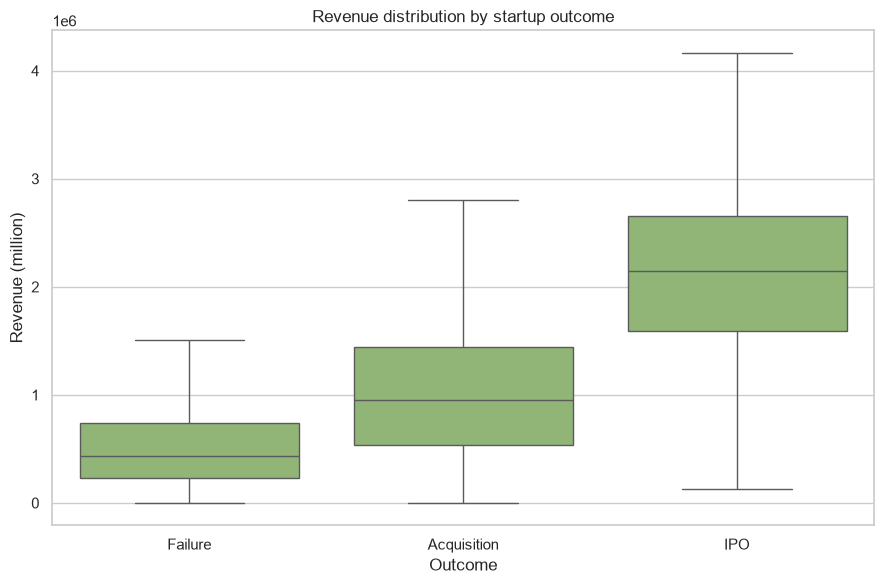

Saved: C:\Users\pabal\OneDrive\Desktop\Projects\startup-funding-analysis\outputs\visualizations\revenue_by_outcome.png


In [68]:
# Representative EDA visualisation: revenue distributions by recorded outcome.
visualization_dir = PROJECT_ROOT / "outputs" / "visualizations"
visualization_dir.mkdir(parents=True, exist_ok=True)
fig, axis = plt.subplots(figsize=(9, 6))
sns.boxplot(data=df, x="outcome", y="revenue_million", order=outcome_order, showfliers=False, color="#90be6d", ax=axis)
axis.set_title("Revenue distribution by startup outcome")
axis.set_xlabel("Outcome")
axis.set_ylabel("Revenue (million)")
fig.tight_layout()
fig.savefig(visualization_dir / "revenue_by_outcome.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", visualization_dir / "revenue_by_outcome.png")

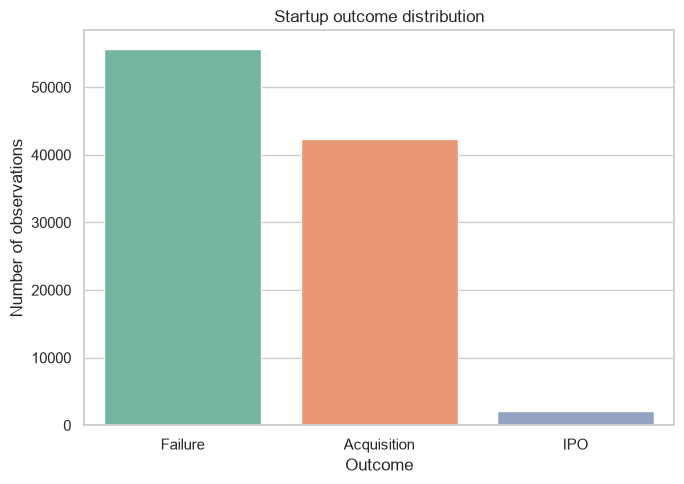

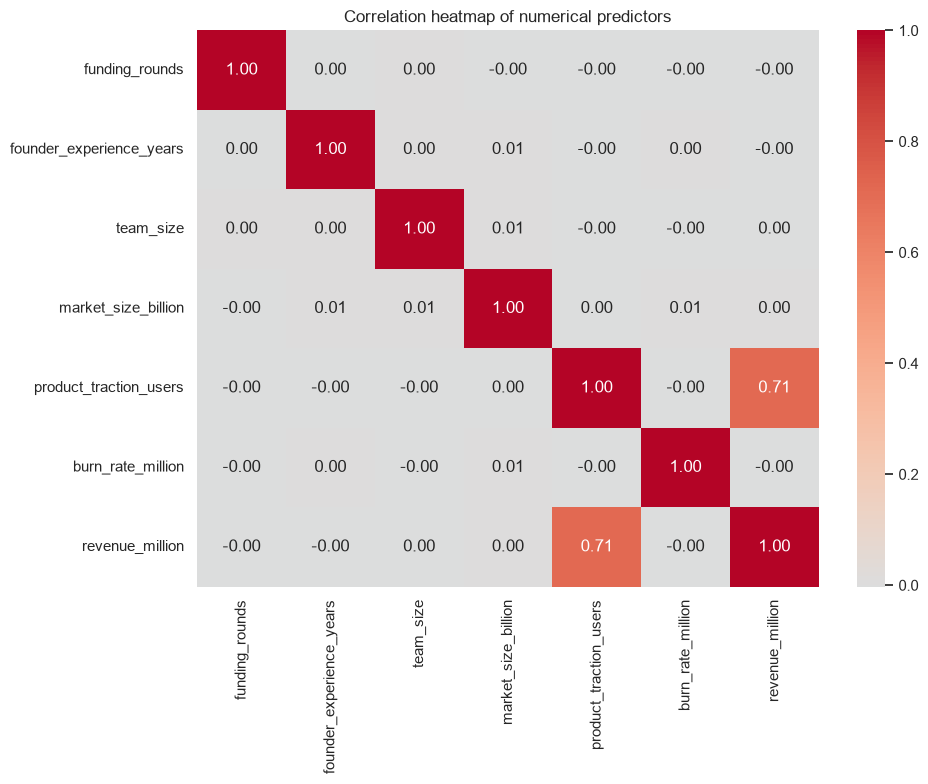

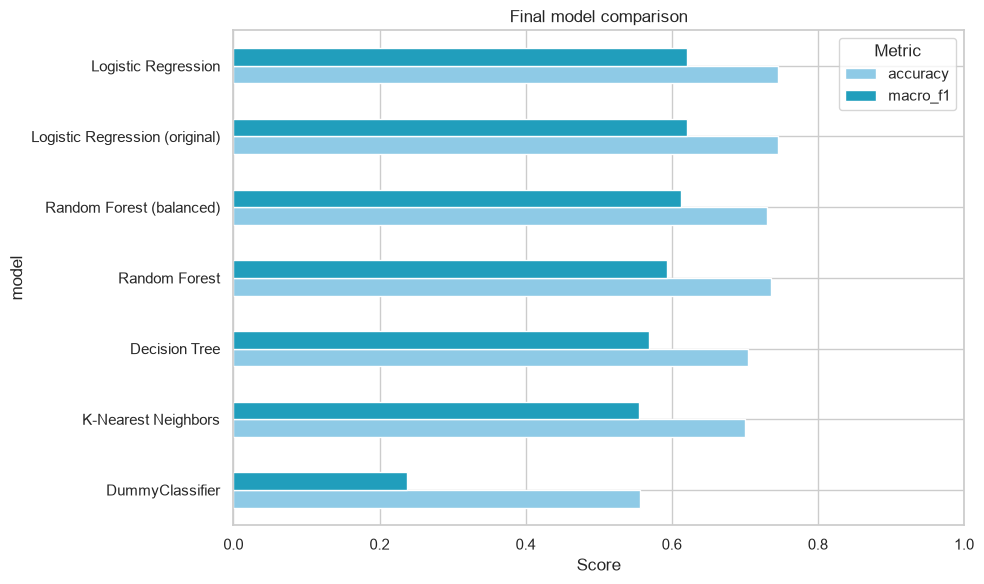

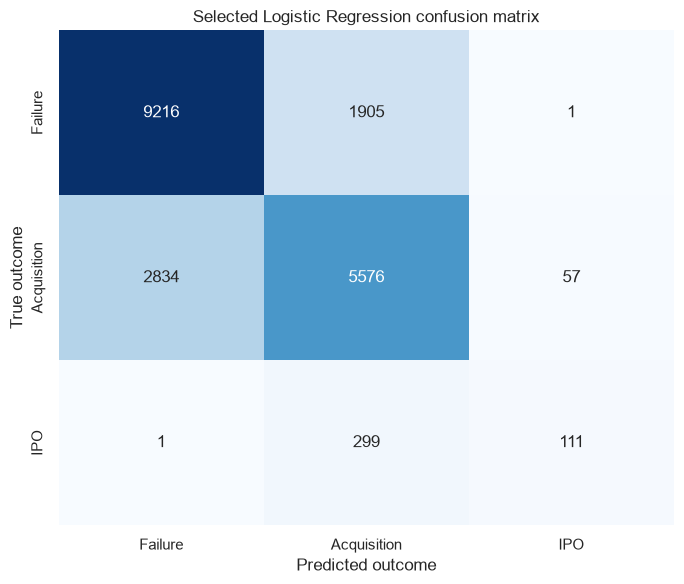

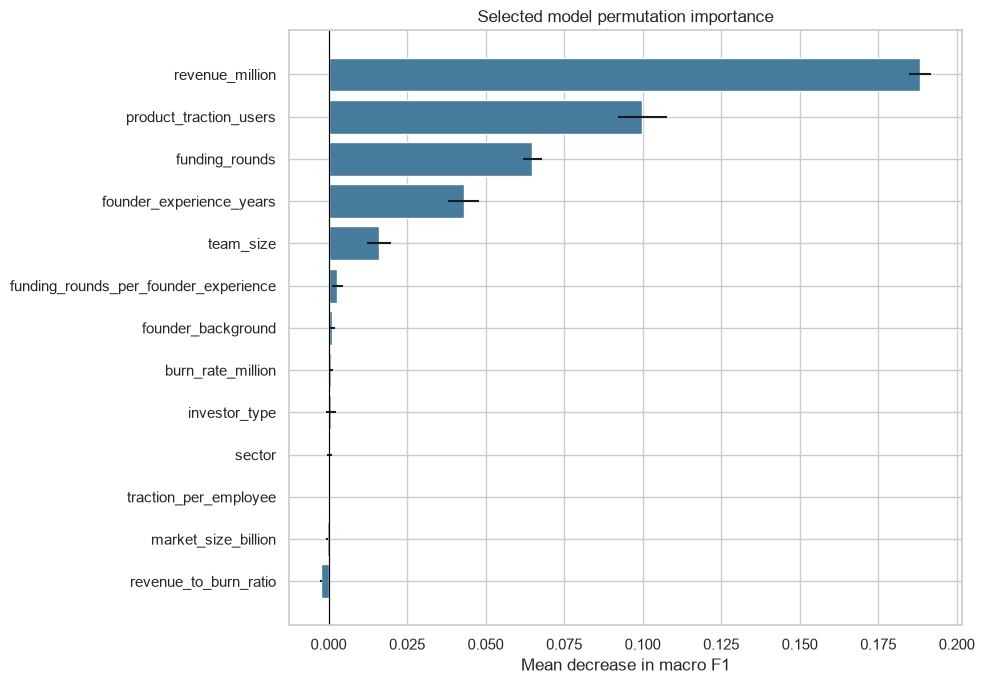

Saved figures:
- outputs\visualizations\correlation_heatmap.png
- outputs\visualizations\model_comparison.png
- outputs\visualizations\permutation_importance.png
- outputs\visualizations\revenue_by_outcome.png
- outputs\visualizations\selected_model_confusion_matrix.png
- outputs\visualizations\target_distribution.png


In [69]:
visualization_dir = PROJECT_ROOT / "outputs" / "visualizations"
visualization_dir.mkdir(parents=True, exist_ok=True)

# Target distribution.
fig, axis = plt.subplots(figsize=(7, 5))
target_counts = y.value_counts().reindex(outcome_order)
sns.barplot(x=target_counts.index, y=target_counts.values, hue=target_counts.index, palette="Set2", legend=False, ax=axis)
axis.set_title("Startup outcome distribution")
axis.set_xlabel("Outcome")
axis.set_ylabel("Number of observations")
fig.tight_layout()
fig.savefig(visualization_dir / "target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Correlation heatmap for original numerical predictors.
fig, axis = plt.subplots(figsize=(10, 8))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axis)
axis.set_title("Correlation heatmap of numerical predictors")
fig.tight_layout()
fig.savefig(visualization_dir / "correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Model comparison.
fig, axis = plt.subplots(figsize=(10, 6))
comparison_plot = final_results_table.set_index("model")[["accuracy", "macro_f1"]].sort_values("macro_f1")
comparison_plot.plot(kind="barh", ax=axis, color=["#8ecae6", "#219ebc"])
axis.set_title("Final model comparison")
axis.set_xlabel("Score")
axis.set_xlim(0, 1)
axis.legend(title="Metric")
fig.tight_layout()
fig.savefig(visualization_dir / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Confusion matrix for the selected model.
selected_confusion = confusion_matrix(y_test, selected_model_predictions, labels=outcome_order)
fig, axis = plt.subplots(figsize=(7, 6))
sns.heatmap(selected_confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis, xticklabels=outcome_order, yticklabels=outcome_order)
axis.set_title("Selected Logistic Regression confusion matrix")
axis.set_xlabel("Predicted outcome")
axis.set_ylabel("True outcome")
fig.tight_layout()
fig.savefig(visualization_dir / "selected_model_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Permutation importance.
plot_data = permutation_importance_table.head(15).sort_values("mean_macro_f1_decrease")
fig, axis = plt.subplots(figsize=(10, 7))
axis.barh(plot_data["feature"], plot_data["mean_macro_f1_decrease"], xerr=plot_data["std_macro_f1_decrease"], color="#457b9d")
axis.axvline(0, color="black", linewidth=0.8)
axis.set_title("Selected model permutation importance")
axis.set_xlabel("Mean decrease in macro F1")
fig.tight_layout()
fig.savefig(visualization_dir / "permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved figures:")
for figure_path in sorted(visualization_dir.glob("*.png")):
    print("-", figure_path.relative_to(PROJECT_ROOT))

## 9.6 Final Conclusion

The analysis found that startup outcomes in this dataset are associated most clearly with several numerical characteristics, especially funding activity, founder experience, team size, product traction, and revenue. The engineered ratios provide interpretable additional representations but do not change the need for careful preprocessing and validation.

Logistic Regression was the selected primary model. It achieved 0.7452 accuracy, 0.6215 macro F1, and 0.7408 weighted F1 on the reported test evaluation. Its IPO recall was 0.2701, showing that the model identifies some minority-class cases but misses most IPO observations. Balanced Random Forest increased IPO recall to 0.2895 but had lower macro F1 (0.6120), illustrating the trade-off between minority recall and overall balanced performance.

The model can identify predictive patterns in the supplied records. It cannot prove that any feature causes an outcome, guarantee future startup success predictions, or replace validation on representative real-world data.

## 9.7 Limitations and Future Improvements

### Limitations

- Dataset provenance, licensing, representativeness, and collection process are unknown.
- The dataset may be synthetic or may contain sampling patterns that do not reflect all startups.
- IPO is a small minority class, which limits stable estimation of minority-class performance.
- No temporal information was available, so the workflow does not simulate forecasting from past to future.
- A single supplied dataset and fixed holdout limit generalisation.
- Correlated predictors can distribute or mask importance.
- Classification metrics measure agreement with recorded labels, not real-world decision usefulness.

### Future improvements

- Validate on a documented external dataset with appropriate redistribution permission.
- Add time-based predictors and a temporal holdout when dates are available.
- Investigate domain-justified features and calibration without using the test set for tuning.
- Study class imbalance with carefully validated resampling or cost-sensitive approaches.
- Assess robustness and fairness across relevant subgroups.
- Add monitoring and model governance before any operational use.

No future improvement is implemented in Step 9.

## 9.8 Repository Preparation and Quality Check

The repository now contains a professional README, a concise dependency manifest, a `.gitignore`, the raw dataset location, the completed notebook, and selected exported figures. The raw CSV was not modified. The README documents that dataset provenance and redistribution permission are unknown, so public publication should be preceded by a licensing check.

The notebook uses a repository-relative data path and is intended to run top to bottom. The test partition has been reused for baseline reporting, Step 7 diagnostics, and Step 8 interpretation, so reported test metrics are useful held-out diagnostics but not a fully independent final estimate. Detailed tables and figure outputs are generated from existing analysis objects; no new model training or tuning is performed here.

In [70]:
quality_checks = {
    "raw_dataset_exists": DATA_PATH.exists(),
    "raw_dataset_shape_unchanged": df.shape == (100000, 11),
    "target_excluded_from_predictors": "outcome" not in final_predictor_features,
    "selected_model_is_from_step_7_cv": selected_model_configuration in cv_results["configuration"].tolist(),
    "visualization_directory_exists": visualization_dir.exists(),
    "visualization_count": len(list(visualization_dir.glob("*.png")))
}
quality_check_table = pd.Series(quality_checks, name="value").to_frame()
display(quality_check_table)
print("Step 9 complete: final findings and documentation only. Step 10 has not been started.")

,value
raw_dataset_exists,True
raw_dataset_shape_unchanged,True
target_excluded_from_predictors,True
selected_model_is_from_step_7_cv,True
visualization_directory_exists,True
visualization_count,6


Step 9 complete: final findings and documentation only. Step 10 has not been started.
